# 🛒 Corporation Favorita Grocery Sales Forecasting

---

## 📌 1. Project Overview
This notebook focuses on conducting a comprehensive **Exploratory Data Analysis (EDA)** and **Data Cleaning** on the **Corporation Favorita Grocery Sales Forecasting** dataset. 

Corporation Favorita is a large Ecuador-based grocery retailer. The primary objective is to inspect, clean, and extract actionable insights from massive multi-table historical sales data to better understand purchasing patterns, store behaviors, and promotional effects.

---

## 🎯 2. Project Objectives
* **Data Hygiene & Integrity:** Inspect and clean raw datasets (handling missing values, schema validation, and memory optimization).
* **Exploratory Data Analysis:** Analyze sales trends across different stores, product families, locations, and promotional periods.
* **External Factors Analysis:** Evaluate the impact of oil prices, national/local holidays, and transactions on daily sales.
* **Preparation for Modeling:** Feature engineering and pipeline-ready dataset transformation for time-series forecasting.

---

## 🗂️ 3. Dataset Description & Schema
The project leverages several relational tables provided by Corporation Favorita:

| Dataset | Key Description | Primary Keys / Join Keys |
| :--- | :--- | :--- |
| **`train.csv`** | Core sales data including date, store, item, units sold (`unit_sales`), and promotion flag (`onpromotion`). | `id`, `date`, `store_nbr`, `item_nbr` |
| **`stores.csv`** | Metadata about retail stores (city, state, type, and cluster). | `store_nbr` |
| **`items.csv`** | Metadata about items sold (family, class, and perishability score). | `item_nbr` |
| **`oil.csv`** | Daily oil prices (a key economic indicator in Ecuador affecting purchasing power). | `date` |
| **`holidays_events.csv`** | Metadata on national, regional, and local holidays, including transfer days and events. | `date`, `locale`, `locale_name` |
| **`transactions.csv`** | Daily transaction counts per store. | `date`, `store_nbr` |

---

## ⚙️ 4. Tech Stack & Tools
* **Language:** Python 3.x
* **High-Performance Data Processing:** `Polars` *(optimized for large-scale / 100M+ rows datasets)*
* **Data Visualization:** `Matplotlib`, `Seaborn`
* **Development Environment:** Jupyter Notebook / VS Code

---

## 🚀 5. Workflow Roadmap
1. **Environment Setup & Data Loading** (Memory-aware lazy loading via Polars).
2. **Schema & Null Values Inspection.**
3. **Data Cleaning & Type Casting** (Handling missing oil prices, date parsing, and invalid records).
4. **Feature Exploration & Visual EDA.**
5. **Insights Summary & Export.**

### 🛠️ Step 1: Import Libraries & Environment Setup

In [4]:
import pandas  as pd
import numpy  as np
import matplotlib as plt
import seaborn as sn
import polars as pl


# 🔍 Step 2: Data Loading & Initial Inspection

In this step, we load and inspect each dataset—including `train`, `stores`, `items`, `oil`, `holidays_events`, and `transactions`. We examine their total dimensions (shapes), review data types (schemas), check for missing values (nulls), and preview initial sample rows to assess data quality and plan the cleaning process.

# Exploratory Data Analysis and Data Cleaning Plan: `holidays_events.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `holidays_events.csv` dataset from the Corporation Favorita project using **Pandas**. This step ensures that spatial-temporal features, holiday flags, and event descriptions are correctly structured, clean, and properly formatted before integrating them with the core transactional sales data.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `holidays_events.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe info using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to identify missing event metadata.
* **Categorical Integrity:** Evaluate distinct categories within the `type`, `locale`, `locale_name`, and `transferred` fields using `.value_counts()` or `.unique()` to detect structural anomalies or unexpected values.
* **Duplicate Verification:** Check for record redundancies across specific primary keys and date bounds using `.duplicated().sum()`.

### 3. Data Cleaning & Optimization
* **Temporal Conversion:** Parse the `date` string column into a native datetime format using `pd.to_datetime()`.
* **Boolean Normalization:** Standardize the `transferred` indicator column into a strictly-typed boolean format and handle missing values appropriately using `.fillna()`.
* **Text Standardization:** Strip leading/trailing whitespaces and apply lowercase formatting across string attributes for consistency using `.str.strip()` and `.str.lower()`.

In [5]:
holidays_events_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\holidays_events.csv\holidays_events.csv")

In [6]:
holidays_events_df.head()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [7]:
holidays_events_df.shape

(350, 6)

In [8]:
holidays_events_df.isnull().sum()

date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

In [9]:
holidays_events_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         350 non-null    str  
 1   type         350 non-null    str  
 2   locale       350 non-null    str  
 3   locale_name  350 non-null    str  
 4   description  350 non-null    str  
 5   transferred  350 non-null    bool 
dtypes: bool(1), str(5)
memory usage: 32.1 KB


In [10]:
holidays_events_df.nunique()

date           312
type             6
locale           3
locale_name     24
description    103
transferred      2
dtype: int64

In [11]:
cols=['type','locale','locale_name']
for col  in cols:
    print(f"{col} Column :")
    print(holidays_events_df[col].value_counts(dropna=False).reset_index())
    print("-"*50)

type Column :
         type  count
0     Holiday    221
1       Event     56
2  Additional     51
3    Transfer     12
4      Bridge      5
5    Work Day      5
--------------------------------------------------
locale Column :
     locale  count
0  National    174
1     Local    152
2  Regional     24
--------------------------------------------------
locale_name Column :
                       locale_name  count
0                          Ecuador    174
1                            Quito     13
2                         Riobamba     12
3                         Guaranda     12
4                        Latacunga     12
5                           Ambato     12
6                        Guayaquil     11
7                           Cuenca      7
8                           Ibarra      7
9                            Manta      6
10                        Cotopaxi      6
11                        Libertad      6
12                            Puyo      6
13                        Imbabura  

In [12]:
holidays_events_df['date']=pd.to_datetime(holidays_events_df['date'])

In [13]:
holidays_events_df.duplicated().sum()

np.int64(0)

In [14]:
holidays_events_df['Day  Name']=holidays_events_df['date'].dt.day_name()
holidays_events_df['Day  Number']=holidays_events_df['date'].dt.day
holidays_events_df['Year']=holidays_events_df['date'].dt.year
holidays_events_df['Month']=holidays_events_df['date'].dt.month_name()


In [15]:
string_columns = ['type', 'locale', 'locale_name', 'description']

for col in string_columns:
    if col in holidays_events_df.columns:
        holidays_events_df[col] = holidays_events_df[col].astype(str).str.strip().str.lower()

# Exploratory Data Analysis and Data Cleaning Plan: `items.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `items.csv` dataset from the Corporation Favorita project using **Pandas**. This step ensures that product attributes, item families, classes, and perishable flags are correctly structured, clean, and properly formatted before integrating them with the core transactional sales data.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `items.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe structure using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to identify any missing product metadata.
* **Categorical Integrity:** Evaluate distinct categories within structural fields such as `family`, `class`, and `perishable` using `.value_counts()` or `.unique()` to detect anomalies or unexpected values.
* **Duplicate Verification:** Check for record redundancies or duplicate item IDs using `.duplicated().sum()`.

### 3. Data Cleaning & Optimization
* **Boolean Normalization:** Standardize the `perishable` indicator column into a strictly-typed boolean format and handle missing values appropriately using `.fillna()`.
* **Text Standardization:** Strip leading/trailing whitespaces and apply lowercase formatting across string attributes (like `family`) for consistency using `.str.strip()` and `.str.lower()`.
* **Type Casting:** Ensure numerical identifiers like `item_nbr` and `class` are properly typed as integers.

In [16]:
items_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\items.csv\items.csv")
items_df.head()



,item_nbr,family,class,perishable
0,96995,GROCERY I,1093,0
1,99197,GROCERY I,1067,0
2,103501,CLEANING,3008,0
3,103520,GROCERY I,1028,0
4,103665,BREAD/BAKERY,2712,1


In [17]:
items_df.shape

(4100, 4)

In [18]:
items_df.isnull().sum()

item_nbr      0
family        0
class         0
perishable    0
dtype: int64

In [19]:
items_df.nunique()

item_nbr      4100
family          33
class          337
perishable       2
dtype: int64

In [20]:
items_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   item_nbr    4100 non-null   int64
 1   family      4100 non-null   str  
 2   class       4100 non-null   int64
 3   perishable  4100 non-null   int64
dtypes: int64(3), str(1)
memory usage: 164.8 KB


In [21]:
items_df.duplicated().sum()

np.int64(0)

In [22]:
items_df['family'] = items_df['family'].astype(str).str.strip().str.lower()

In [23]:
items_df.head()

,item_nbr,family,class,perishable
0,96995,grocery i,1093,0
1,99197,grocery i,1067,0
2,103501,cleaning,3008,0
3,103520,grocery i,1028,0
4,103665,bread/bakery,2712,1


# Exploratory Data Analysis and Data Cleaning Plan: `oil.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `oil.csv` dataset from the Corporation Favorita project using **Pandas**. This step ensures that daily oil prices are correctly structured, temporal attributes are standardized, and missing price values are properly handled before merging with the main sales and store transactional data.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `oil.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe structure using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to identify any missing oil price records on specific dates (e.g., weekends or holidays).
* **Temporal Continuity Check:** Verify the date range and look for gaps or missing continuous days in the timeline.
* **Duplicate Verification:** Check for record redundancies or duplicate dates using `.duplicated().sum()`.

### 3. Data Cleaning & Optimization
* **Temporal Conversion:** Parse the `date` string column into a native datetime format using `pd.to_datetime()`.
* **Missing Value Handling:** Address missing oil prices (duties/weekends) using appropriate strategies such as forward-filling (`.ffill()`) since oil prices typically carry over from the last recorded business day.
* **Numerical Integrity:** Ensure the `dcoilwtico` (Daily Crude Oil Prices) column is properly typed as a float for analytical consistency.

In [24]:
oil_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\oil.csv\oil.csv")
oil_df.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [25]:
oil_df.shape

(1218, 2)

In [26]:
oil_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   str    
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), str(1)
memory usage: 31.1 KB


In [27]:
oil_df['date']=pd.to_datetime(oil_df['date'])


In [28]:
oil_df.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

In [29]:
oil_df['dcoilwtico']=oil_df['dcoilwtico'].ffill().bfill()

In [30]:
oil_df.head()

,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [31]:
oil_df.duplicated().sum()

np.int64(0)

In [32]:
oil_df['Day  Name']=oil_df['date'].dt.day_name()
oil_df['Day  Number']=oil_df['date'].dt.day
oil_df['Year']=oil_df['date'].dt.year
oil_df['Month']=oil_df['date'].dt.month_name()


In [33]:
sample_submission_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\sample_submission.csv\sample_submission.csv")
sample_submission_df.head()

,id,unit_sales
0,125497040,0
1,125497041,0
2,125497042,0
3,125497043,0
4,125497044,0


In [34]:
sample_submission_df.shape

(3370464, 2)

In [35]:
sample_submission_df.isnull().sum()

id            0
unit_sales    0
dtype: int64

In [36]:
sample_submission_df.nunique()

id            3370464
unit_sales          1
dtype: int64

# Exploratory Data Analysis and Data Cleaning Plan: `stores.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `stores.csv` dataset from the Corporation Favorita project using **Pandas**. This step ensures that store metadata—including city, state, store type, and cluster assignments—are correctly structured, clean, and properly formatted before integrating them with the core transactional sales data.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `stores.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe structure using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to ensure complete metadata across all stores.
* **Categorical Integrity:** Evaluate distinct categories and distributions within structural fields such as `city`, `state`, `type`, and `cluster` using `.value_counts()` or `.unique()` to detect anomalies or formatting inconsistencies.
* **Duplicate Verification:** Check for record redundancies or duplicate store identifiers (`store_nbr`) using `.duplicated().sum()`.

### 3. Data Cleaning & Optimization
* **Text Standardization:** Strip leading/trailing whitespaces and apply lowercase formatting across string attributes (like `city`, `state`, and `type`) for consistency using `.str.strip()` and `.str.lower()`.
* **Type Casting:** Ensure numerical identifiers like `store_nbr` and `cluster` are properly typed as integers.

In [37]:
stores_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\stores.csv\stores.csv")
stores_df.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [38]:
stores_df.shape

(54, 5)

In [39]:
stores_df.isnull().sum()

store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

In [40]:
stores_df.nunique()

store_nbr    54
city         22
state        16
type          5
cluster      17
dtype: int64

In [41]:
cols_2 =['city','state','type']
for  col in cols_2 :
    print(f"{col} Column :")
    print(stores_df[col].unique())
    print('-'*50)

city Column :
<ArrowStringArray>
[        'Quito', 'Santo Domingo',       'Cayambe',     'Latacunga',
      'Riobamba',        'Ibarra',      'Guaranda',          'Puyo',
        'Ambato',     'Guayaquil',       'Salinas',         'Daule',
      'Babahoyo',       'Quevedo',        'Playas',      'Libertad',
        'Cuenca',          'Loja',       'Machala',    'Esmeraldas',
         'Manta',     'El Carmen']
Length: 22, dtype: str
--------------------------------------------------
state Column :
<ArrowStringArray>
[                     'Pichincha', 'Santo Domingo de los Tsachilas',
                       'Cotopaxi',                     'Chimborazo',
                       'Imbabura',                        'Bolivar',
                        'Pastaza',                     'Tungurahua',
                         'Guayas',                    'Santa Elena',
                       'Los Rios',                          'Azuay',
                           'Loja',                         'El Or

In [42]:
stores_df.duplicated().sum()

np.int64(0)

In [43]:
stores_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   store_nbr  54 non-null     int64
 1   city       54 non-null     str  
 2   state      54 non-null     str  
 3   type       54 non-null     str  
 4   cluster    54 non-null     int64
dtypes: int64(2), str(3)
memory usage: 3.1 KB


In [44]:
stores_df.describe()

,store_nbr,cluster
count,54.000000,54.000000
mean,27.500000,8.481481
std,15.732133,4.693395
min,1.000000,1.000000
25%,14.250000,4.000000
50%,27.500000,8.500000
75%,40.750000,13.000000
max,54.000000,17.000000


# Exploratory Data Analysis and Data Cleaning Plan: `test.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `test.csv` dataset from the Corporation Favorita project using **Pandas**. This dataset mirrors the structure of the training data for the forecasting horizon, and this step ensures that temporal features, store-item combinations, and promotional flags are correctly structured and clean before generating predictions.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `test.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe structure using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to verify that essential features like `date`, `store_nbr`, and `item_nbr` are fully populated.
* **Temporal Range Check:** Inspect the start and end dates of the forecasting period to ensure correct alignment with the submission requirements.
* **Duplicate Verification:** Check for record redundancies or duplicate combinations of `date`, `store_nbr`, and `item_nbr` using `.duplicated().sum()`.

### 3. Data Cleaning & Optimization
* **Temporal Conversion:** Parse the `date` string column into a native datetime format using `pd.to_datetime()`.
* **Boolean Normalization:** Standardize the `onpromotion` indicator column into a strictly-typed boolean format and handle missing values appropriately using `.fillna()`.
* **Type Casting:** Ensure numerical identifiers like `store_nbr` and `item_nbr` are properly typed as integers for seamless merging and alignment with auxiliary features.

In [45]:
test_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\test.csv\test.csv")
test_df.head()

,id,date,store_nbr,item_nbr,onpromotion
0,125497040,2017-08-16,1,96995,False
1,125497041,2017-08-16,1,99197,False
2,125497042,2017-08-16,1,103501,False
3,125497043,2017-08-16,1,103520,False
4,125497044,2017-08-16,1,103665,False


In [46]:
test_df.shape

(3370464, 5)

In [47]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3370464 entries, 0 to 3370463
Data columns (total 5 columns):
 #   Column       Dtype
---  ------       -----
 0   id           int64
 1   date         str  
 2   store_nbr    int64
 3   item_nbr     int64
 4   onpromotion  bool 
dtypes: bool(1), int64(3), str(1)
memory usage: 138.2 MB


In [48]:
test_df['date']=pd.to_datetime(test_df['date'])

In [49]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3370464 entries, 0 to 3370463
Data columns (total 5 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   item_nbr     int64         
 4   onpromotion  bool          
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 106.1 MB


In [50]:
test_df.isnull().sum()

id             0
date           0
store_nbr      0
item_nbr       0
onpromotion    0
dtype: int64

In [51]:
test_df.duplicated().sum()

np.int64(0)

In [52]:
test_df['Day  Name']=test_df['date'].dt.day_name()
test_df['Day  Number']=test_df['date'].dt.day
test_df['Year']=test_df['date'].dt.year
test_df['Month']=test_df['date'].dt.month_name()


In [53]:

missing_count = test_df["onpromotion"].isna().sum()
total_rows = len(test_df)
missing_percentage = missing_count / total_rows * 100

print("Total rows:", total_rows)
print("Missing rows:", missing_count)
print("Missing percentage:", round(missing_percentage, 2), "%")


Total rows: 3370464
Missing rows: 0
Missing percentage: 0.0 %


In [54]:
test_df.isnull().sum()

id             0
date           0
store_nbr      0
item_nbr       0
onpromotion    0
Day  Name      0
Day  Number    0
Year           0
Month          0
dtype: int64

# Exploratory Data Analysis and Data Cleaning Plan: `train.csv` (Polars Engine)

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the large-scale `train.csv` dataset from the Corporation Favorita project using the **Polars** library. Because of its massive size, utilizing Polars (LazyFrames) ensures memory efficiency, high-speed execution, and optimized processing for time-series sales forecasting before merging with auxiliary features.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `train.csv` file lazily using `pl.scan_csv()` to prevent memory bottlenecks.
* Inspect column names, inferred data types, and initial schema structure.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Compute null counts efficiently across all columns using `.null_count()` expressions in Polars.
* **Temporal Range Check:** Verify start/end dates and inspect time-series continuity across the historical sales records.
* **Duplicate Verification:** Check for record redundancies or duplicate combinations of `date`, `store_nbr`, and `item_nbr` using `.is_duplicated().sum()`.
* **Target Distribution Check:** Briefly inspect basic statistical metrics of the target variable (`unit_sales`) to detect outliers, negative values, or anomalies.

### 3. Data Cleaning & Optimization
* **Temporal Conversion:** Parse the `date` string column into a native `Date` or `Datetime` format using `.str.to_date()`.
* **Boolean Normalization:** Standardize the `onpromotion` indicator column into a strictly-typed `Boolean` format and handle missing or null values appropriately using `.fill_null(False)`.
* **Type Casting & Memory Optimization:** Ensure numerical identifiers (`store_nbr`, `item_nbr`) and target values (`unit_sales`) are correctly typed with appropriate integer/float precisions to optimize memory footprint.

In [55]:
file_path = r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\train.csv\train.csv"

train_df = pl.scan_csv(
    file_path,
    schema_overrides={
        "date": pl.Date,
        "onpromotion": pl.String
    }
)

print(train_df.collect_schema())


Schema({'id': Int64, 'date': Date, 'store_nbr': Int64, 'item_nbr': Int64, 'unit_sales': Float64, 'onpromotion': String})


In [56]:

train_df = train_df.with_columns(
    pl.when(pl.col("onpromotion") == "True")
    .then(pl.lit(True))
    .when(pl.col("onpromotion") == "False")
    .then(pl.lit(False))
    .otherwise(None)
    .cast(pl.Boolean)
    .alias("onpromotion")
)

print(train_df.collect_schema())


Schema({'id': Int64, 'date': Date, 'store_nbr': Int64, 'item_nbr': Int64, 'unit_sales': Float64, 'onpromotion': Boolean})


In [57]:

train_df.head(10).collect()


id,date,store_nbr,item_nbr,unit_sales,onpromotion
i64,date,i64,i64,f64,bool
0,2013-01-01,25,103665,7.0,null
1,2013-01-01,25,105574,1.0,null
2,2013-01-01,25,105575,2.0,null
3,2013-01-01,25,108079,1.0,null
4,2013-01-01,25,108701,1.0,null
5,2013-01-01,25,108786,3.0,null
6,2013-01-01,25,108797,1.0,null
7,2013-01-01,25,108952,1.0,null
8,2013-01-01,25,111397,13.0,null


In [58]:

train_df.tail(10).collect()


id,date,store_nbr,item_nbr,unit_sales,onpromotion
i64,date,i64,i64,f64,bool
125497030,2017-08-15,54,2086882,1.0,false
125497031,2017-08-15,54,2087409,3.0,false
125497032,2017-08-15,54,2087978,8.0,false
125497033,2017-08-15,54,2088922,7.0,false
125497034,2017-08-15,54,2089036,4.0,false
125497035,2017-08-15,54,2089339,4.0,false
125497036,2017-08-15,54,2106464,1.0,true
125497037,2017-08-15,54,2110456,192.0,false
125497038,2017-08-15,54,2113914,198.0,true


In [59]:

train_df.select(
    pl.len().alias("total_rows"),
    pl.all().null_count()
).collect()


total_rows,id,date,store_nbr,item_nbr,unit_sales,onpromotion
u32,u32,u32,u32,u32,u32,u32
125497040,0,0,0,0,0,21657651


In [60]:

train_df.select(
    pl.col("store_nbr").min().alias("min_store"),
    pl.col("store_nbr").max().alias("max_store"),
    pl.col("item_nbr").min().alias("min_item"),
    pl.col("item_nbr").max().alias("max_item"),
    pl.col("unit_sales").min().alias("min_sales"),
    pl.col("unit_sales").max().alias("max_sales"),
    pl.col("unit_sales").mean().alias("mean_sales"),
    pl.col("unit_sales").median().alias("median_sales")
).collect()


min_store,max_store,min_item,max_item,min_sales,max_sales,mean_sales,median_sales
i64,i64,i64,i64,f64,f64,f64,f64
1,54,96995,2127114,-15372.0,89440.0,8.554865,4.0


In [61]:

train_df.select(
    pl.len().alias("total_rows"),
    pl.col("id").n_unique().alias("unique_ids")
).collect()


total_rows,unique_ids
u32,u32
125497040,125497040


In [62]:

train_df.select(
    (pl.col("unit_sales") < 0).sum().alias("negative_rows"),
    (pl.col("unit_sales") == 0).sum().alias("zero_rows"),
    (pl.col("unit_sales") > 0).sum().alias("positive_rows"),
    (
        (pl.col("unit_sales") < 0).sum() * 100.0 / pl.len()
    ).alias("negative_percentage")
).collect()


negative_rows,zero_rows,positive_rows,negative_percentage
u32,u32,u32,f64
7795,0,125489245,0.006211


In [63]:

train_df.select(
    (pl.col("unit_sales") < -10).sum().alias("below_minus_10"),
    (pl.col("unit_sales") < -100).sum().alias("below_minus_100"),
    (pl.col("unit_sales") < -1000).sum().alias("below_minus_1000"),
    (pl.col("unit_sales") < -10000).sum().alias("below_minus_10000")
).collect()


below_minus_10,below_minus_100,below_minus_1000,below_minus_10000
u32,u32,u32,u32
1003,154,20,2


In [64]:

train_df.filter(
    pl.col("unit_sales") < 0
).select(
    "date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"
).head(20).collect()


date,store_nbr,item_nbr,unit_sales,onpromotion
date,i64,i64,f64,bool
2013-01-02,10,456875,-3.0,null
2013-01-03,5,559044,-1.0,null
2013-01-03,9,365138,-3.0,null
2013-01-03,41,812716,-19.0,null
2013-01-03,41,1004551,-27.0,null
…,…,…,…,…
2013-01-09,35,1079215,-8.0,null
2013-01-09,43,847859,-17.0,null
2013-01-09,44,307740,-2.0,null


In [65]:

train_df = train_df.with_columns(
    pl.col("date").dt.year().alias("year"),
    pl.col("date").dt.month().alias("month"),
    pl.col("date").dt.strftime("%B").alias("month_name"),
    pl.col("date").dt.day().alias("day"),
    pl.col("date").dt.weekday().alias("weekday"),
    pl.col("date").dt.strftime("%A").alias("day_name")
)

train_df.select(
    "date", "year", "month", "month_name",
    "day", "weekday", "day_name"
).head(10).collect()


date,year,month,month_name,day,weekday,day_name
date,i32,i8,str,i8,i8,str
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""
2013-01-01,2013,1,"""January""",1,2,"""Tuesday"""


In [66]:

train_df.select(
    pl.col("date").min().alias("first_date"),
    pl.col("date").max().alias("last_date"),
    pl.col("year").n_unique().alias("unique_years"),
    pl.col("month").n_unique().alias("unique_month_numbers")
).collect()


first_date,last_date,unique_years,unique_month_numbers
date,date,u32,u32
2013-01-01,2017-08-15,5,12


In [67]:

train_df.group_by("onpromotion").len().sort(
    "len", descending=True
).collect()


onpromotion,len
bool,u32
false,96028767
null,21657651
true,7810622


In [68]:

train_df.select(
    (pl.col("store_nbr") <= 0).sum().alias("invalid_stores"),
    (pl.col("item_nbr") <= 0).sum().alias("invalid_items"),
    pl.col("date").null_count().alias("null_dates"),
    pl.col("unit_sales").is_in(
        [float("inf"), float("-inf")]
    ).sum().alias("infinite_sales")
).collect()


invalid_stores,invalid_items,null_dates,infinite_sales
u32,u32,u32,u32
0,0,0,0


In [69]:

print(train_df.collect_schema())


Schema({'id': Int64, 'date': Date, 'store_nbr': Int64, 'item_nbr': Int64, 'unit_sales': Float64, 'onpromotion': Boolean, 'year': Int32, 'month': Int8, 'month_name': String, 'day': Int8, 'weekday': Int8, 'day_name': String})


In [70]:

train_df.select(
    "id",
    "date",
    "store_nbr",
    "item_nbr",
    "unit_sales",
    "onpromotion",
    "year",
    "month",
    "month_name",
    "day",
    "weekday",
    "day_name"
).head(10).collect()


id,date,store_nbr,item_nbr,unit_sales,onpromotion,year,month,month_name,day,weekday,day_name
i64,date,i64,i64,f64,bool,i32,i8,str,i8,i8,str
0,2013-01-01,25,103665,7.0,null,2013,1,"""January""",1,2,"""Tuesday"""
1,2013-01-01,25,105574,1.0,null,2013,1,"""January""",1,2,"""Tuesday"""
2,2013-01-01,25,105575,2.0,null,2013,1,"""January""",1,2,"""Tuesday"""
3,2013-01-01,25,108079,1.0,null,2013,1,"""January""",1,2,"""Tuesday"""
4,2013-01-01,25,108701,1.0,null,2013,1,"""January""",1,2,"""Tuesday"""
5,2013-01-01,25,108786,3.0,null,2013,1,"""January""",1,2,"""Tuesday"""
6,2013-01-01,25,108797,1.0,null,2013,1,"""January""",1,2,"""Tuesday"""
7,2013-01-01,25,108952,1.0,null,2013,1,"""January""",1,2,"""Tuesday"""
8,2013-01-01,25,111397,13.0,null,2013,1,"""January""",1,2,"""Tuesday"""


In [71]:

train_df.select(
    pl.len().alias("total_rows"),
    pl.col("onpromotion").null_count().alias("null_count"),
    (
        pl.col("onpromotion").null_count() * 100.0 / pl.len()
    ).alias("null_percentage")
).collect()


total_rows,null_count,null_percentage
u32,u32,f64
125497040,21657651,17.257499


In [72]:

train_df.group_by("onpromotion").len().sort(
    "len", descending=True
).collect()


onpromotion,len
bool,u32
false,96028767
null,21657651
true,7810622


In [73]:

missing_by_month = (
    train_df
    .group_by(
        pl.col("date").dt.year().alias("year"),
        pl.col("date").dt.month().alias("month")
    )
    .agg(
        pl.len().alias("total_rows"),
        pl.col("onpromotion").null_count().alias("missing_rows")
    )
    .with_columns(
        (pl.col("missing_rows") / pl.col("total_rows") * 100)
        .round(2)
        .alias("missing_percentage")
    )
    .sort(["year", "month"])
)

missing_by_month.collect()


year,month,total_rows,missing_rows,missing_percentage
i32,i8,u32,u32,f64
2013,1,1211964,1211964,100.0
2013,2,1160386,1160386,100.0
2013,3,1321927,1321927,100.0
2013,4,1284375,1284375,100.0
2013,5,1360917,1360917,100.0
…,…,…,…,…
2017,4,3168724,0,0.0
2017,5,3301627,0,0.0
2017,6,3165034,0,0.0


In [74]:
missing_by_year = (
    train_df
    .group_by(pl.col("date").dt.year().alias("year"))
    .agg(
        pl.len().alias("total_rows"),
        pl.col("onpromotion").null_count().alias("missing_rows")
    )
    .with_columns(
        (pl.col("missing_rows") / pl.col("total_rows") * 100)
        .round(2)
        .alias("missing_percentage")
    )
    .sort("year")
)

missing_by_year.collect()


year,total_rows,missing_rows,missing_percentage
i32,u32,u32,f64
2013,16322662,16322662,100.0
2014,22271602,5334989,23.95
2015,27864644,0,0.0
2016,35229871,0,0.0
2017,23808261,0,0.0


In [75]:

train_df.select([
    pl.col(c).null_count().alias(c)
    for c in train_df.collect_schema().names()
]).collect()


id,date,store_nbr,item_nbr,unit_sales,onpromotion,year,month,month_name,day,weekday,day_name
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,21657651,0,0,0,0,0,0


In [76]:
train_df.select(
    pl.all().n_unique()
).collect()

id,date,store_nbr,item_nbr,unit_sales,onpromotion,year,month,month_name,day,weekday,day_name
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
125497040,1684,54,4036,258474,3,5,12,12,31,7,7


In [77]:
items_pl = pl.from_pandas(items_df)

train_items = train_df.select("item_nbr").unique().collect()

missing_items = items_pl.join(
    train_items,
    on="item_nbr",
    how="anti"
)

print(missing_items)
print("Count:", missing_items.height)

shape: (64, 4)
┌──────────┬──────────────────┬───────┬────────────┐
│ item_nbr ┆ family           ┆ class ┆ perishable │
│ ---      ┆ ---              ┆ ---   ┆ ---        │
│ i64      ┆ str              ┆ i64   ┆ i64        │
╞══════════╪══════════════════╪═══════╪════════════╡
│ 313094   ┆ grocery i        ┆ 1042  ┆ 0          │
│ 766493   ┆ grocery i        ┆ 1005  ┆ 0          │
│ 1464607  ┆ beverages        ┆ 1114  ┆ 0          │
│ 1467088  ┆ grocery i        ┆ 1087  ┆ 0          │
│ 1467093  ┆ grocery i        ┆ 1093  ┆ 0          │
│ …        ┆ …                ┆ …     ┆ …          │
│ 2132318  ┆ grocery i        ┆ 1002  ┆ 0          │
│ 2132945  ┆ grocery i        ┆ 1026  ┆ 0          │
│ 2132957  ┆ grocery i        ┆ 1068  ┆ 0          │
│ 2134058  ┆ beverages        ┆ 1124  ┆ 0          │
│ 2134244  ┆ liquor,wine,beer ┆ 1364  ┆ 0          │
└──────────┴──────────────────┴───────┴────────────┘
Count: 64


In [78]:
train_only_items = train_items.join(
    items_pl.select("item_nbr"),
    on="item_nbr",
    how="anti"
)

print(train_only_items)
print("Count:", train_only_items.height)

shape: (0, 1)
┌──────────┐
│ item_nbr │
│ ---      │
│ i64      │
╞══════════╡
└──────────┘
Count: 0


In [79]:
stores_pl = pl.from_pandas(stores_df)

train_stores = train_df.select("store_nbr").unique().collect()

train_only_stores = train_stores.join(
    stores_pl.select("store_nbr"),
    on="store_nbr",
    how="anti"
)

print(train_only_stores)
print("Count:", train_only_stores.height)

shape: (0, 1)
┌───────────┐
│ store_nbr │
│ ---       │
│ i64       │
╞═══════════╡
└───────────┘
Count: 0


In [80]:
oil_pl = pl.from_pandas(oil_df)

oil_pl = oil_pl.with_columns(
    pl.col("date").cast(pl.Date)
)
oil_pl = oil_pl.with_columns(
    pl.col("date").cast(pl.Date)
)

train_dates = train_df.select("date").unique().collect()

train_only_dates = train_dates.join(
    oil_pl.select("date").unique(),
    on="date",
    how="anti"
)

print(train_only_dates)
print("Count:", train_only_dates.height)

shape: (481, 1)
┌────────────┐
│ date       │
│ ---        │
│ date       │
╞════════════╡
│ 2013-06-01 │
│ 2013-09-21 │
│ 2014-07-06 │
│ 2014-11-15 │
│ 2014-12-20 │
│ …          │
│ 2013-09-14 │
│ 2013-12-22 │
│ 2015-05-31 │
│ 2013-05-25 │
│ 2017-01-01 │
└────────────┘
Count: 481


In [81]:
print("Train date range:")
print(train_dates.select(
    pl.col("date").min().alias("min_date"),
    pl.col("date").max().alias("max_date")
))

print("\nOil date range:")
print(oil_pl.select(
    pl.col("date").min().alias("min_date"),
    pl.col("date").max().alias("max_date")
))

print("\nMissing dates range:")
print(train_only_dates.select(
    pl.col("date").min().alias("min_date"),
    pl.col("date").max().alias("max_date")
))

Train date range:
shape: (1, 2)
┌────────────┬────────────┐
│ min_date   ┆ max_date   │
│ ---        ┆ ---        │
│ date       ┆ date       │
╞════════════╪════════════╡
│ 2013-01-01 ┆ 2017-08-15 │
└────────────┴────────────┘

Oil date range:
shape: (1, 2)
┌────────────┬────────────┐
│ min_date   ┆ max_date   │
│ ---        ┆ ---        │
│ date       ┆ date       │
╞════════════╪════════════╡
│ 2013-01-01 ┆ 2017-08-31 │
└────────────┴────────────┘

Missing dates range:
shape: (1, 2)
┌────────────┬────────────┐
│ min_date   ┆ max_date   │
│ ---        ┆ ---        │
│ date       ┆ date       │
╞════════════╪════════════╡
│ 2013-01-05 ┆ 2017-08-13 │
└────────────┴────────────┘


In [82]:
print(
    train_only_dates
    .with_columns(
        pl.col("date").dt.strftime("%A").alias("day_name")
    )
    .group_by("day_name")
    .len()
    .sort("len", descending=True)
)

shape: (2, 2)
┌──────────┬─────┐
│ day_name ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ Saturday ┆ 241 │
│ Sunday   ┆ 240 │
└──────────┴─────┘


In [83]:
transactions_df = pd.read_csv(
    r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\transactions.csv\transactions.csv"
)

transactions_pl = pl.from_pandas(transactions_df)

transactions_pl = transactions_pl.with_columns(
    pl.col("date").str.to_date("%Y-%m-%d")
)
train_store_dates = (
    train_df
    .select("date", "store_nbr")
    .unique()
    .collect()
)
missing_transactions = train_store_dates.join(
    transactions_pl.select("date", "store_nbr").unique(),
    on=["date", "store_nbr"],
    how="anti"
)

print(missing_transactions)
print("Count:", missing_transactions.height)

shape: (118, 2)
┌────────────┬───────────┐
│ date       ┆ store_nbr │
│ ---        ┆ ---       │
│ date       ┆ i64       │
╞════════════╪═══════════╡
│ 2016-01-04 ┆ 14        │
│ 2016-01-02 ┆ 18        │
│ 2016-01-04 ┆ 41        │
│ 2016-01-03 ┆ 3         │
│ 2016-09-27 ┆ 7         │
│ …          ┆ …         │
│ 2016-01-02 ┆ 3         │
│ 2016-01-02 ┆ 9         │
│ 2016-01-04 ┆ 17        │
│ 2016-01-03 ┆ 24        │
│ 2016-01-04 ┆ 8         │
└────────────┴───────────┘
Count: 118


In [84]:
print(
    missing_transactions
    .group_by("date")
    .len()
    .sort("date")
)

shape: (8, 2)
┌────────────┬─────┐
│ date       ┆ len │
│ ---        ┆ --- │
│ date       ┆ u32 │
╞════════════╪═════╡
│ 2013-06-19 ┆ 4   │
│ 2014-01-02 ┆ 1   │
│ 2014-03-24 ┆ 1   │
│ 2016-01-01 ┆ 1   │
│ 2016-01-02 ┆ 17  │
│ 2016-01-03 ┆ 53  │
│ 2016-01-04 ┆ 39  │
│ 2016-09-27 ┆ 2   │
└────────────┴─────┘


In [85]:
print(
    transactions_pl
    .filter(
        pl.col("date").is_in(
            missing_transactions.get_column("date").unique()
        )
    )
    .group_by("date")
    .len()
    .sort("date")
)

shape: (6, 2)
┌────────────┬─────┐
│ date       ┆ len │
│ ---        ┆ --- │
│ date       ┆ u32 │
╞════════════╪═════╡
│ 2013-06-19 ┆ 43  │
│ 2014-01-02 ┆ 46  │
│ 2014-03-24 ┆ 46  │
│ 2016-01-02 ┆ 36  │
│ 2016-01-04 ┆ 14  │
│ 2016-09-27 ┆ 49  │
└────────────┴─────┘


C:\Users\Mahmoud\AppData\Local\Temp\ipykernel_19172\2553381751.py:3: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(


In [86]:
print(
    train_store_dates
    .filter(pl.col("date") == pl.date(2016, 1, 3))
    .height
)

53


In [87]:
print(
    train_store_dates
    .filter(pl.col("date") == pl.date(2016, 1, 3))
    .sort("store_nbr")
)

shape: (53, 2)
┌────────────┬───────────┐
│ date       ┆ store_nbr │
│ ---        ┆ ---       │
│ date       ┆ i64       │
╞════════════╪═══════════╡
│ 2016-01-03 ┆ 1         │
│ 2016-01-03 ┆ 2         │
│ 2016-01-03 ┆ 3         │
│ 2016-01-03 ┆ 4         │
│ 2016-01-03 ┆ 5         │
│ …          ┆ …         │
│ 2016-01-03 ┆ 49        │
│ 2016-01-03 ┆ 50        │
│ 2016-01-03 ┆ 51        │
│ 2016-01-03 ┆ 53        │
│ 2016-01-03 ┆ 54        │
└────────────┴───────────┘


In [88]:
print(
    train_store_dates.filter(
        (pl.col("date") == pl.date(2016, 1, 3)) &
        (pl.col("store_nbr") == 52)
    )
)

shape: (0, 2)
┌──────┬───────────┐
│ date ┆ store_nbr │
│ ---  ┆ ---       │
│ date ┆ i64       │
╞══════╪═══════════╡
└──────┴───────────┘


In [89]:
print(
    transactions_pl
    .filter(pl.col("date") == pl.date(2016, 1, 3))
)

shape: (0, 3)
┌──────┬───────────┬──────────────┐
│ date ┆ store_nbr ┆ transactions │
│ ---  ┆ ---       ┆ ---          │
│ date ┆ i64       ┆ i64          │
╞══════╪═══════════╪══════════════╡
└──────┴───────────┴──────────────┘


In [90]:
missing_summary = (
    missing_transactions
    .group_by("date")
    .len()
    .rename({"len": "missing_stores"})
    .join(
        train_store_dates
        .group_by("date")
        .len()
        .rename({"len": "sales_stores"}),
        on="date",
        how="left"
    )
    .sort("date")
)

print(missing_summary)

shape: (8, 3)
┌────────────┬────────────────┬──────────────┐
│ date       ┆ missing_stores ┆ sales_stores │
│ ---        ┆ ---            ┆ ---          │
│ date       ┆ u32            ┆ u32          │
╞════════════╪════════════════╪══════════════╡
│ 2013-06-19 ┆ 4              ┆ 47           │
│ 2014-01-02 ┆ 1              ┆ 47           │
│ 2014-03-24 ┆ 1              ┆ 47           │
│ 2016-01-01 ┆ 1              ┆ 1            │
│ 2016-01-02 ┆ 17             ┆ 53           │
│ 2016-01-03 ┆ 53             ┆ 53           │
│ 2016-01-04 ┆ 39             ┆ 53           │
│ 2016-09-27 ┆ 2              ┆ 51           │
└────────────┴────────────────┴──────────────┘


In [91]:
holidays_pl = pl.from_pandas(holidays_events_df)

holidays_pl = holidays_pl.with_columns(
    pl.col("date").cast(pl.Date)
)

print(
    holidays_pl.filter(
        pl.col("date").is_in(
            missing_transactions
            .get_column("date")
            .implode()
        )
    ).sort("date")
)

shape: (1, 10)
┌────────────┬─────────┬──────────┬─────────────┬───┬───────────┬─────────────┬──────┬─────────┐
│ date       ┆ type    ┆ locale   ┆ locale_name ┆ … ┆ Day  Name ┆ Day  Number ┆ Year ┆ Month   │
│ ---        ┆ ---     ┆ ---      ┆ ---         ┆   ┆ ---       ┆ ---         ┆ ---  ┆ ---     │
│ date       ┆ str     ┆ str      ┆ str         ┆   ┆ str       ┆ i32         ┆ i32  ┆ str     │
╞════════════╪═════════╪══════════╪═════════════╪═══╪═══════════╪═════════════╪══════╪═════════╡
│ 2016-01-01 ┆ holiday ┆ national ┆ ecuador     ┆ … ┆ Friday    ┆ 1           ┆ 2016 ┆ January │
└────────────┴─────────┴──────────┴─────────────┴───┴───────────┴─────────────┴──────┴─────────┘


In [92]:
holiday_dates = holidays_pl.select("date").unique()

train_holiday_dates = train_df.select("date").unique().collect()

matching_holidays = train_holiday_dates.join(
    holiday_dates,
    on="date",
    how="inner"
)

print(matching_holidays)
print("Matching dates:", matching_holidays.height)

shape: (252, 1)
┌────────────┐
│ date       │
│ ---        │
│ date       │
╞════════════╡
│ 2013-04-29 │
│ 2014-12-08 │
│ 2016-02-08 │
│ 2016-04-28 │
│ 2016-05-07 │
│ …          │
│ 2017-06-25 │
│ 2013-10-09 │
│ 2015-06-23 │
│ 2016-05-10 │
│ 2013-10-11 │
└────────────┘
Matching dates: 252


In [93]:
holiday_date_counts = (
    holidays_pl
    .group_by("date")
    .len()
    .filter(pl.col("len") > 1)
    .sort("len", descending=True)
)

print(holiday_date_counts)
print("Dates with multiple records:", holiday_date_counts.height)

shape: (31, 2)
┌────────────┬─────┐
│ date       ┆ len │
│ ---        ┆ --- │
│ date       ┆ u32 │
╞════════════╪═════╡
│ 2014-06-25 ┆ 4   │
│ 2017-06-25 ┆ 3   │
│ 2012-06-25 ┆ 3   │
│ 2015-06-25 ┆ 3   │
│ 2013-06-25 ┆ 3   │
│ …          ┆ …   │
│ 2016-12-22 ┆ 2   │
│ 2012-07-03 ┆ 2   │
│ 2014-12-22 ┆ 2   │
│ 2016-05-08 ┆ 2   │
│ 2017-12-08 ┆ 2   │
└────────────┴─────┘
Dates with multiple records: 31


In [94]:
print(
    holidays_pl
    .filter(pl.col("date") == pl.date(2014, 6, 25))
)

shape: (4, 10)
┌────────────┬─────────┬──────────┬─────────────┬───┬───────────┬─────────────┬──────┬───────┐
│ date       ┆ type    ┆ locale   ┆ locale_name ┆ … ┆ Day  Name ┆ Day  Number ┆ Year ┆ Month │
│ ---        ┆ ---     ┆ ---      ┆ ---         ┆   ┆ ---       ┆ ---         ┆ ---  ┆ ---   │
│ date       ┆ str     ┆ str      ┆ str         ┆   ┆ str       ┆ i32         ┆ i32  ┆ str   │
╞════════════╪═════════╪══════════╪═════════════╪═══╪═══════════╪═════════════╪══════╪═══════╡
│ 2014-06-25 ┆ holiday ┆ local    ┆ latacunga   ┆ … ┆ Wednesday ┆ 25          ┆ 2014 ┆ June  │
│ 2014-06-25 ┆ holiday ┆ local    ┆ machala     ┆ … ┆ Wednesday ┆ 25          ┆ 2014 ┆ June  │
│ 2014-06-25 ┆ holiday ┆ regional ┆ imbabura    ┆ … ┆ Wednesday ┆ 25          ┆ 2014 ┆ June  │
│ 2014-06-25 ┆ event   ┆ national ┆ ecuador     ┆ … ┆ Wednesday ┆ 25          ┆ 2014 ┆ June  │
└────────────┴─────────┴──────────┴─────────────┴───┴───────────┴─────────────┴──────┴───────┘


In [95]:
original_cols = [
    "date", "type", "locale",
    "locale_name", "description", "transferred"
]

print(
    holidays_pl
    .height - holidays_pl.select(original_cols).unique().height
)

0


In [96]:
print(
    holidays_pl
    .group_by("locale")
    .len()
    .sort("len", descending=True)
)

shape: (3, 2)
┌──────────┬─────┐
│ locale   ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ national ┆ 174 │
│ local    ┆ 152 │
│ regional ┆ 24  │
└──────────┴─────┘


In [97]:
print("Holiday locale names:")
print(
    holidays_pl
    .filter(pl.col("locale") != "national")
    .select("locale", "locale_name")
    .unique()
    .sort(["locale", "locale_name"])
)

Holiday locale names:
shape: (23, 2)
┌──────────┬────────────────────────────────┐
│ locale   ┆ locale_name                    │
│ ---      ┆ ---                            │
│ str      ┆ str                            │
╞══════════╪════════════════════════════════╡
│ local    ┆ ambato                         │
│ local    ┆ cayambe                        │
│ local    ┆ cuenca                         │
│ local    ┆ el carmen                      │
│ local    ┆ esmeraldas                     │
│ …        ┆ …                              │
│ local    ┆ santo domingo                  │
│ regional ┆ cotopaxi                       │
│ regional ┆ imbabura                       │
│ regional ┆ santa elena                    │
│ regional ┆ santo domingo de los tsachilas │
└──────────┴────────────────────────────────┘


In [98]:
print(
    stores_pl
    .select("city", "state")
    .unique()
    .sort(["state", "city"])
)

shape: (22, 2)
┌───────────────┬────────────────────────────────┐
│ city          ┆ state                          │
│ ---           ┆ ---                            │
│ str           ┆ str                            │
╞═══════════════╪════════════════════════════════╡
│ Cuenca        ┆ Azuay                          │
│ Guaranda      ┆ Bolivar                        │
│ Riobamba      ┆ Chimborazo                     │
│ Latacunga     ┆ Cotopaxi                       │
│ Machala       ┆ El Oro                         │
│ …             ┆ …                              │
│ Cayambe       ┆ Pichincha                      │
│ Quito         ┆ Pichincha                      │
│ Salinas       ┆ Santa Elena                    │
│ Santo Domingo ┆ Santo Domingo de los Tsachilas │
│ Ambato        ┆ Tungurahua                     │
└───────────────┴────────────────────────────────┘


In [99]:
cities = (
    stores_pl
    .select(pl.col("city").str.to_lowercase().alias("locale_name"))
    .unique()
)

states = (
    stores_pl
    .select(pl.col("state").str.to_lowercase().alias("locale_name"))
    .unique()
)

local_names = (
    holidays_pl
    .filter(pl.col("locale") == "local")
    .select("locale_name")
    .unique()
)

regional_names = (
    holidays_pl
    .filter(pl.col("locale") == "regional")
    .select("locale_name")
    .unique()
)

print("Local names not found in store cities:")
print(local_names.join(cities, on="locale_name", how="anti"))

print("\nRegional names not found in store states:")
print(regional_names.join(states, on="locale_name", how="anti"))

Local names not found in store cities:
shape: (0, 1)
┌─────────────┐
│ locale_name │
│ ---         │
│ str         │
╞═════════════╡
└─────────────┘

Regional names not found in store states:
shape: (0, 1)
┌─────────────┐
│ locale_name │
│ ---         │
│ str         │
╞═════════════╡
└─────────────┘


In [100]:
print(
    holidays_pl
    .group_by("transferred")
    .len()
    .sort("len", descending=True)
)

shape: (2, 2)
┌─────────────┬─────┐
│ transferred ┆ len │
│ ---         ┆ --- │
│ bool        ┆ u32 │
╞═════════════╪═════╡
│ false       ┆ 338 │
│ true        ┆ 12  │
└─────────────┴─────┘


In [101]:
print(
    holidays_pl
    .filter(pl.col("transferred") == True)
    .select(
        "date",
        "type",
        "locale",
        "locale_name",
        "description",
        "transferred"
    )
    .sort("date")
)

shape: (12, 6)
┌────────────┬─────────┬──────────┬─────────────┬───────────────────────────────┬─────────────┐
│ date       ┆ type    ┆ locale   ┆ locale_name ┆ description                   ┆ transferred │
│ ---        ┆ ---     ┆ ---      ┆ ---         ┆ ---                           ┆ ---         │
│ date       ┆ str     ┆ str      ┆ str         ┆ str                           ┆ bool        │
╞════════════╪═════════╪══════════╪═════════════╪═══════════════════════════════╪═════════════╡
│ 2012-10-09 ┆ holiday ┆ national ┆ ecuador     ┆ independencia de guayaquil    ┆ true        │
│ 2013-10-09 ┆ holiday ┆ national ┆ ecuador     ┆ independencia de guayaquil    ┆ true        │
│ 2014-10-09 ┆ holiday ┆ national ┆ ecuador     ┆ independencia de guayaquil    ┆ true        │
│ 2016-05-24 ┆ holiday ┆ national ┆ ecuador     ┆ batalla de pichincha          ┆ true        │
│ 2016-07-25 ┆ holiday ┆ local    ┆ guayaquil   ┆ fundacion de guayaquil        ┆ true        │
│ …          ┆ …       ┆ 

In [102]:
print(
    holidays_pl
    .filter(pl.col("type") == "work day")
    .select(
        "date",
        "type",
        "locale",
        "locale_name",
        "description",
        "transferred"
    )
    .sort("date")
)

shape: (5, 6)
┌────────────┬──────────┬──────────┬─────────────┬─────────────────────────────────┬─────────────┐
│ date       ┆ type     ┆ locale   ┆ locale_name ┆ description                     ┆ transferred │
│ ---        ┆ ---      ┆ ---      ┆ ---         ┆ ---                             ┆ ---         │
│ date       ┆ str      ┆ str      ┆ str         ┆ str                             ┆ bool        │
╞════════════╪══════════╪══════════╪═════════════╪═════════════════════════════════╪═════════════╡
│ 2013-01-05 ┆ work day ┆ national ┆ ecuador     ┆ recupero puente navidad         ┆ false       │
│ 2013-01-12 ┆ work day ┆ national ┆ ecuador     ┆ recupero puente primer dia del… ┆ false       │
│ 2014-12-20 ┆ work day ┆ national ┆ ecuador     ┆ recupero puente navidad         ┆ false       │
│ 2015-01-10 ┆ work day ┆ national ┆ ecuador     ┆ recupero puente primer dia del… ┆ false       │
│ 2016-11-12 ┆ work day ┆ national ┆ ecuador     ┆ recupero puente dia de difunto… ┆ false     

In [103]:
print(
    holidays_pl
    .group_by(["type", "transferred"])
    .len()
    .sort(["type", "transferred"])
)

shape: (7, 3)
┌────────────┬─────────────┬─────┐
│ type       ┆ transferred ┆ len │
│ ---        ┆ ---         ┆ --- │
│ str        ┆ bool        ┆ u32 │
╞════════════╪═════════════╪═════╡
│ additional ┆ false       ┆ 51  │
│ bridge     ┆ false       ┆ 5   │
│ event      ┆ false       ┆ 56  │
│ holiday    ┆ false       ┆ 209 │
│ holiday    ┆ true        ┆ 12  │
│ transfer   ┆ false       ┆ 12  │
│ work day   ┆ false       ┆ 5   │
└────────────┴─────────────┴─────┘


In [104]:
print(
    holidays_pl
    .filter(pl.col("type") == "transfer")
    .select(
        "date",
        "type",
        "locale",
        "locale_name",
        "description",
        "transferred"
    )
    .sort("date")
)

shape: (12, 6)
┌────────────┬──────────┬──────────┬─────────────┬─────────────────────────────────┬─────────────┐
│ date       ┆ type     ┆ locale   ┆ locale_name ┆ description                     ┆ transferred │
│ ---        ┆ ---      ┆ ---      ┆ ---         ┆ ---                             ┆ ---         │
│ date       ┆ str      ┆ str      ┆ str         ┆ str                             ┆ bool        │
╞════════════╪══════════╪══════════╪═════════════╪═════════════════════════════════╪═════════════╡
│ 2012-10-12 ┆ transfer ┆ national ┆ ecuador     ┆ traslado independencia de guay… ┆ false       │
│ 2013-10-11 ┆ transfer ┆ national ┆ ecuador     ┆ traslado independencia de guay… ┆ false       │
│ 2014-10-10 ┆ transfer ┆ national ┆ ecuador     ┆ traslado independencia de guay… ┆ false       │
│ 2016-05-27 ┆ transfer ┆ national ┆ ecuador     ┆ traslado batalla de pichincha   ┆ false       │
│ 2016-07-24 ┆ transfer ┆ local    ┆ guayaquil   ┆ traslado fundacion de guayaqui… ┆ false    

In [105]:
# Prepare store names for matching
stores_match = stores_pl.with_columns(
    pl.col("city").str.to_lowercase().alias("city_match"),
    pl.col("state").str.to_lowercase().alias("state_match")
)

# National events: apply to all stores
national_events = (
    holidays_pl
    .filter(pl.col("locale") == "national")
    .join(
        stores_match.select("store_nbr"),
        how="cross"
    )
)

# Local events: match city
local_events = (
    holidays_pl
    .filter(pl.col("locale") == "local")
    .join(
        stores_match,
        left_on="locale_name",
        right_on="city_match",
        how="inner"
    )
)

# Regional events: match state
regional_events = (
    holidays_pl
    .filter(pl.col("locale") == "regional")
    .join(
        stores_match,
        left_on="locale_name",
        right_on="state_match",
        how="inner"
    )
)

# Combine all applicable events
holiday_store_events = pl.concat(
    [
        national_events.select(
            "date", "store_nbr", "type",
            "locale", "description", "transferred"
        ),
        local_events.select(
            "date", "store_nbr", "type",
            "locale", "description", "transferred"
        ),
        regional_events.select(
            "date", "store_nbr", "type",
            "locale", "description", "transferred"
        )
    ]
)

print("Total event-store records:", holiday_store_events.height)
print("Unique store-date combinations:",
      holiday_store_events.select("date", "store_nbr").unique().height)

Total event-store records: 9950
Unique store-date combinations: 9601


In [106]:
duplicate_store_dates = (
    holiday_store_events
    .group_by(["date", "store_nbr"])
    .len()
    .filter(pl.col("len") > 1)
    .sort("len", descending=True)
)

print("Store-date combinations with multiple events:",
      duplicate_store_dates.height)

print(duplicate_store_dates.head(10))

Store-date combinations with multiple events: 349
shape: (10, 3)
┌────────────┬───────────┬─────┐
│ date       ┆ store_nbr ┆ len │
│ ---        ┆ ---       ┆ --- │
│ date       ┆ i64       ┆ u32 │
╞════════════╪═══════════╪═════╡
│ 2016-05-08 ┆ 21        ┆ 2   │
│ 2016-07-24 ┆ 32        ┆ 2   │
│ 2012-12-24 ┆ 31        ┆ 2   │
│ 2016-05-08 ┆ 33        ┆ 2   │
│ 2012-12-24 ┆ 14        ┆ 2   │
│ 2016-05-07 ┆ 16        ┆ 2   │
│ 2016-05-08 ┆ 23        ┆ 2   │
│ 2012-12-24 ┆ 19        ┆ 2   │
│ 2012-12-31 ┆ 9         ┆ 2   │
│ 2012-12-24 ┆ 13        ┆ 2   │
└────────────┴───────────┴─────┘


In [107]:
sales_dates = train_df.select("date").unique().collect()

events_in_sales_period = holiday_store_events.join(
    sales_dates,
    on="date",
    how="semi"
)

print("All event-store records:", holiday_store_events.height)
print("Event-store records within sales dates:",
      events_in_sales_period.height)
print("Unique dates within sales period:",
      events_in_sales_period.select("date").unique().height)

All event-store records: 9950
Event-store records within sales dates: 8348
Unique dates within sales period: 252


In [108]:
sales_stores = train_df.select("store_nbr").unique().collect()

unknown_event_stores = (
    events_in_sales_period
    .select("store_nbr")
    .unique()
    .join(
        sales_stores,
        on="store_nbr",
        how="anti"
    )
)

print("Unknown stores in holiday events:",
      unknown_event_stores.height)

Unknown stores in holiday events: 0


In [109]:
event_cols = [
    "date",
    "store_nbr",
    "type",
    "locale",
    "description",
    "transferred"
]

print(
    "Exact duplicate rows:",
    events_in_sales_period.height
    - events_in_sales_period.select(event_cols).unique().height
)

Exact duplicate rows: 0


In [110]:
holiday_store_summary = (
    events_in_sales_period
    .group_by(["date", "store_nbr"])
    .agg([
        pl.len().alias("event_count"),
        pl.col("type").unique().sort().alias("event_types"),
        pl.col("description").unique().sort().alias("event_descriptions")
    ])
    .sort(["date", "store_nbr"])
)

print("Summary rows:", holiday_store_summary.height)

print(
    "Unique date-store keys:",
    holiday_store_summary
    .select("date", "store_nbr")
    .unique()
    .height
)

print(holiday_store_summary.head(5))

Summary rows: 8109
Unique date-store keys: 8109
shape: (5, 5)
┌────────────┬───────────┬─────────────┬─────────────┬────────────────────────┐
│ date       ┆ store_nbr ┆ event_count ┆ event_types ┆ event_descriptions     │
│ ---        ┆ ---       ┆ ---         ┆ ---         ┆ ---                    │
│ date       ┆ i64       ┆ u32         ┆ list[str]   ┆ list[str]              │
╞════════════╪═══════════╪═════════════╪═════════════╪════════════════════════╡
│ 2013-01-01 ┆ 1         ┆ 1           ┆ ["holiday"] ┆ ["primer dia del ano"] │
│ 2013-01-01 ┆ 2         ┆ 1           ┆ ["holiday"] ┆ ["primer dia del ano"] │
│ 2013-01-01 ┆ 3         ┆ 1           ┆ ["holiday"] ┆ ["primer dia del ano"] │
│ 2013-01-01 ┆ 4         ┆ 1           ┆ ["holiday"] ┆ ["primer dia del ano"] │
│ 2013-01-01 ┆ 5         ┆ 1           ┆ ["holiday"] ┆ ["primer dia del ano"] │
└────────────┴───────────┴─────────────┴─────────────┴────────────────────────┘


In [111]:
sales_rows_before = train_df.select(pl.len()).collect().item()

sales_with_holidays = train_df.join(
    holiday_store_summary.lazy(),
    on=["date", "store_nbr"],
    how="left"
)

sales_rows_after = (
    sales_with_holidays
    .select(pl.len())
    .collect()
    .item()
)

print("Rows before join:", sales_rows_before)
print("Rows after join:", sales_rows_after)
print("Row count preserved:", sales_rows_before == sales_rows_after)

Rows before join: 125497040
Rows after join: 125497040
Row count preserved: True


# Exploratory Data Analysis and Data Cleaning Plan: `transactions.csv`

## Executive Summary
The primary objective of this process is to perform an initial Exploratory Data Analysis (EDA) and data cleaning pipeline on the `transactions.csv` dataset from the Corporation Favorita project using **Pandas**. This step ensures that store-level daily transaction counts, temporal timelines, and customer activity metrics are correctly structured, clean, and properly validated before integrating them with the core sales and store metadata.

---

## Objectives & Key Steps

### 1. Data Ingestion & Schema Inspection
* Load the `transactions.csv` file using `pandas.read_csv()`.
* Inspect column names, data types (`dtypes`), and basic dataframe structure using `.info()` and `.head()`.

### 2. Exploratory Data Analysis (EDA)
* **Missing Value Analysis:** Check total null counts per feature using `.isnull().sum()` to identify any missing transaction records for specific stores and dates.
* **Temporal Continuity & Range Check:** Verify date bounds and inspect whether all active stores have recorded transactions for every operational day.
* **Duplicate Verification:** Check for record redundancies or duplicate combinations of `date` and `store_nbr` using `.duplicated().sum()`.
* **Distribution Inspection:** Evaluate basic statistical metrics of the `transactions` count column using `.describe()` to detect potential outliers or unusual transaction spikes/drops.

### 3. Data Cleaning & Optimization
* **Temporal Conversion:** Parse the `date` string column into a native datetime format using `pd.to_datetime()`.
* **Type Casting:** Ensure identifiers like `store_nbr` are properly typed as integers, and transaction counts (`transactions`) are cast to appropriate numeric types.
* **Missing Value Handling:** Address any gaps or missing daily store transactions using logical imputation methods if required by the modeling pipeline.

In [112]:
transactions_df=pd.read_csv(r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\transactions.csv\transactions.csv")
transactions_df.head(5)

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [113]:
transactions_df.shape

(83488, 3)

In [114]:
transactions_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          83488 non-null  str  
 1   store_nbr     83488 non-null  int64
 2   transactions  83488 non-null  int64
dtypes: int64(2), str(1)
memory usage: 2.7 MB


In [115]:
transactions_df['date']=pd.to_datetime(transactions_df['date'])

In [116]:
transactions_df.isnull().sum()

date            0
store_nbr       0
transactions    0
dtype: int64

In [117]:
transactions_df.duplicated().sum()

np.int64(0)

In [118]:
transactions_df['Day  Name']=transactions_df['date'].dt.day_name()
transactions_df['Day  Number']=transactions_df['date'].dt.day
transactions_df['Year']=transactions_df['date'].dt.year
transactions_df['Month']=transactions_df['date'].dt.month_name()


In [119]:
transactions_df.head()

,date,store_nbr,transactions,Day Name,Day Number,Year,Month
0,2013-01-01,25,770,Tuesday,1,2013,January
1,2013-01-02,1,2111,Wednesday,2,2013,January
2,2013-01-02,2,2358,Wednesday,2,2013,January
3,2013-01-02,3,3487,Wednesday,2,2013,January
4,2013-01-02,4,1922,Wednesday,2,2013,January


## Phase 3: Final Data Quality Decisions

### 1. Missing Promotion Data (`onpromotion`)

The training dataset contains **125,497,040 rows**, of which **21,657,651 (17.26%)** have missing values in the `onpromotion` column.

Missing values are distributed unevenly across years:

- **2013:** 100% missing.
- **2014:** 23.95% missing.
- **2015–2017:** No missing values.

**Decision:** Retain missing values as null rather than replacing them with `False`.

**Reason:** A missing value does not necessarily mean that a product was not on promotion. Replacing nulls with `False` would introduce unsupported assumptions and could distort promotion-related analysis. Promotion comparisons involving 2013 and 2014 must account for this limitation.

### 2. Negative Sales Values (`unit_sales`)

The training dataset contains **7,795 negative sales records**, representing approximately **0.0062%** of all rows. No zero sales values were found.

Negative values may represent product returns, sales corrections, or other adjustments.

**Decision:** Retain negative sales values during data quality processing.

**Reason:** Removing them automatically could eliminate legitimate business activity and bias sales analysis. Their distribution and impact will be investigated during EDA before deciding whether any specialized treatment is necessary.

### 3. Oil Price Missing Values (`dcoilwtico`)

The original oil dataset contains **1,218 rows**, including **43 missing oil prices**. These missing values were filled using forward fill and backfill.

After processing, the oil dataset contains no missing prices.

**Decision:** Retain the processed oil dataset and document the imputation method.

**Reason:** Filling missing values allows oil prices to be used in subsequent analysis. However, imputed observations are estimates rather than original measurements and should be considered when interpreting relationships between oil prices and sales.

### 4. Missing Oil Dates in the Sales Dataset

A total of **481 distinct dates** in the sales period do not have matching dates in the original oil dataset. All these dates fall on Saturdays or Sundays.

**Decision:** Do not automatically classify these dates as data errors.

**Reason:** Oil price observations are not available for every calendar day. The missing dates will be handled explicitly when joining oil prices to sales data, and the limitations of any resulting analysis will be documented.

### 5. Products Without Historical Sales

The item catalog contains **4,100 unique products**, while the training dataset contains **4,036 unique products**. Therefore, **64 catalog products have no historical sales records** in the training period.

Every product appearing in the training data exists in the item catalog.

**Decision:** Retain all products in the item catalog.

**Reason:** Products without historical sales may still be valid catalog entries. Removing them could unnecessarily reduce the completeness of product reference data and affect future comparisons with the test dataset.

### 6. Store-Date Combinations Missing Transaction Records

The sales dataset contains **118 distinct store-date combinations** that have no corresponding records in the transactions dataset, distributed across eight dates.

Notably, on January 3, 2016, all 53 stores represented in the sales data have no matching transaction records.

**Decision:** Retain the sales records and do not invent or impute transaction counts.

**Reason:** The absence of a transaction record does not establish that the transaction count was zero. Missing records will be treated as a data limitation during transaction-related analysis.

### 7. Duplicate Records and Key Validation

The logical key for a sales record is:

`date + store_nbr + item_nbr`

Validation results:

- **Training dataset:** No duplicate keys.
- **Test dataset:** No duplicate keys; all 3,370,464 keys are unique.
- **Training IDs:** All 125,497,040 IDs are unique.

**Decision:** No duplicate records were removed.

**Reason:** The key checks found no duplicate records requiring removal, so no rows needed to be deleted on this basis.

### 8. Referential Integrity

Relationships between the sales data and the reference datasets were validated.

- Every sales product exists in the item catalog.
- Every sales store exists in the store catalog.
- No invalid store or item identifiers were found in the training data.
- Holiday/event locations were successfully matched to the relevant store cities and states.

**Decision:** Retain the reference datasets and use validated relationships for subsequent analysis.

**Reason:** Validating these relationships reduces the risk of incorrect classifications, unmatched records, and misleading results when combining datasets.

### 9. Holiday and Event Data

The original holiday/event dataset contains **350 rows** and no missing values or exact duplicate records.

However, multiple events can occur on the same date, and different events can apply to different stores depending on whether their locale is national, regional, or local.

A store-level event mapping was created, and multiple events for the same store-date combination were summarized into a single record. The resulting summary contains **8,109 unique store-date combinations**.

Joining this summary to the sales data preserved the original **125,497,040 rows**.

**Decision:** Keep the original event records and use the summarized store-date table when joining events to sales.

**Reason:** Joining raw event records directly could multiply sales rows when multiple events apply to the same date. The summarized table prevents this row multiplication while preserving relevant event information.

Transferred holidays, transfer records, work days, and other event types were retained because they represent distinct information about the calendar.

### 10. Date Validation

The training dataset contains no missing dates.

- **Minimum date:** January 1, 2013.
- **Maximum date:** August 15, 2017.

The test dataset also contains no missing dates or missing promotion indicators.

**Decision:** Retain the validated date values and use them for subsequent time-based analysis.

**Reason:** Valid date fields are essential for aggregating sales by year, month, weekday, and other time periods.

---

## Phase 3 Summary

The final data quality decisions prioritize preserving valid business information, avoiding unsupported assumptions, and documenting limitations instead of automatically deleting or replacing questionable values.

Key outcomes:

- No duplicate sales keys were found in either the training or test datasets.
- Reference relationships were validated.
- Missing promotion values and negative sales values were retained for appropriate downstream analysis.
- Missing oil prices were imputed and documented.
- Missing transaction records were not artificially filled.
- Holiday/event relationships were summarized safely without multiplying sales rows.

**Outcome:** The data quality review and final decision stage is complete. The project can now proceed to **Phase 4: Exploratory Data Analysis (EDA)** using Python and Polars.

In [120]:
print(
    train_df
    .select(
        pl.len().alias("total_rows"),
        pl.col("onpromotion").is_null().sum().alias("missing"),
        pl.col("onpromotion").is_not_null().sum().alias("not_missing")
    )
    .collect()
)

shape: (1, 3)
┌────────────┬──────────┬─────────────┐
│ total_rows ┆ missing  ┆ not_missing │
│ ---        ┆ ---      ┆ ---         │
│ u32        ┆ u32      ┆ u32         │
╞════════════╪══════════╪═════════════╡
│ 125497040  ┆ 21657651 ┆ 103839389   │
└────────────┴──────────┴─────────────┘


In [121]:
print(
    train_df
    .group_by(pl.col("date").dt.year().alias("Year"))
    .agg([
        pl.len().alias("total_rows"),
        pl.col("onpromotion").is_null().sum().alias("missing"),
        (
            pl.col("onpromotion").is_null().mean() * 100
        ).round(2).alias("missing_pct")
    ])
    .sort("Year")
    .collect()
)

shape: (5, 4)
┌──────┬────────────┬──────────┬─────────────┐
│ Year ┆ total_rows ┆ missing  ┆ missing_pct │
│ ---  ┆ ---        ┆ ---      ┆ ---         │
│ i32  ┆ u32        ┆ u32      ┆ f64         │
╞══════╪════════════╪══════════╪═════════════╡
│ 2013 ┆ 16322662   ┆ 16322662 ┆ 100.0       │
│ 2014 ┆ 22271602   ┆ 5334989  ┆ 23.95       │
│ 2015 ┆ 27864644   ┆ 0        ┆ 0.0         │
│ 2016 ┆ 35229871   ┆ 0        ┆ 0.0         │
│ 2017 ┆ 23808261   ┆ 0        ┆ 0.0         │
└──────┴────────────┴──────────┴─────────────┘


In [122]:
print(
    train_df
    .group_by(pl.col("date").dt.year().alias("Year"))
    .agg([
        pl.len().alias("total_rows"),
        (pl.col("unit_sales") < 0).sum().alias("negative_sales"),
        (
            (pl.col("unit_sales") < 0).mean() * 100
        ).round(4).alias("negative_pct")
    ])
    .sort("Year")
    .collect()
)

shape: (5, 4)
┌──────┬────────────┬────────────────┬──────────────┐
│ Year ┆ total_rows ┆ negative_sales ┆ negative_pct │
│ ---  ┆ ---        ┆ ---            ┆ ---          │
│ i32  ┆ u32        ┆ u32            ┆ f64          │
╞══════╪════════════╪════════════════╪══════════════╡
│ 2013 ┆ 16322662   ┆ 947            ┆ 0.0058       │
│ 2014 ┆ 22271602   ┆ 1350           ┆ 0.0061       │
│ 2015 ┆ 27864644   ┆ 1619           ┆ 0.0058       │
│ 2016 ┆ 35229871   ┆ 2246           ┆ 0.0064       │
│ 2017 ┆ 23808261   ┆ 1633           ┆ 0.0069       │
└──────┴────────────┴────────────────┴──────────────┘


In [123]:
print(
    train_df
    .select([
        pl.col("date").is_null().sum().alias("missing_dates"),
        pl.col("date").min().alias("min_date"),
        pl.col("date").max().alias("max_date")
    ])
    .collect()
)

shape: (1, 3)
┌───────────────┬────────────┬────────────┐
│ missing_dates ┆ min_date   ┆ max_date   │
│ ---           ┆ ---        ┆ ---        │
│ u32           ┆ date       ┆ date       │
╞═══════════════╪════════════╪════════════╡
│ 0             ┆ 2013-01-01 ┆ 2017-08-15 │
└───────────────┴────────────┴────────────┘


In [124]:
print(
    test_df[["date", "onpromotion"]].isna().sum()
)

date           0
onpromotion    0
dtype: int64


In [125]:
print(
    "Total rows:", len(test_df),
    "\nUnique keys:", 
    test_df[["date", "store_nbr", "item_nbr"]].drop_duplicates().shape[0],
    "\nDuplicate keys:",
    test_df.duplicated(
        subset=["date", "store_nbr", "item_nbr"]
    ).sum()
)

Total rows: 3370464 
Unique keys: 3370464 
Duplicate keys: 0


In [126]:
print(
    oil_pl.select([
        pl.len().alias("total_rows"),
        pl.col("dcoilwtico").is_null().sum().alias("missing_oil_prices"),
        pl.col("date").min().alias("min_date"),
        pl.col("date").max().alias("max_date")
    ])
)

shape: (1, 4)
┌────────────┬────────────────────┬────────────┬────────────┐
│ total_rows ┆ missing_oil_prices ┆ min_date   ┆ max_date   │
│ ---        ┆ ---                ┆ ---        ┆ ---        │
│ u32        ┆ u32                ┆ date       ┆ date       │
╞════════════╪════════════════════╪════════════╪════════════╡
│ 1218       ┆ 0                  ┆ 2013-01-01 ┆ 2017-08-31 │
└────────────┴────────────────────┴────────────┴────────────┘


In [127]:
stores_df.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [128]:
transactions_df.head()

,date,store_nbr,transactions,Day Name,Day Number,Year,Month
0,2013-01-01,25,770,Tuesday,1,2013,January
1,2013-01-02,1,2111,Wednesday,2,2013,January
2,2013-01-02,2,2358,Wednesday,2,2013,January
3,2013-01-02,3,3487,Wednesday,2,2013,January
4,2013-01-02,4,1922,Wednesday,2,2013,January


In [129]:
transactions_df.nunique()

date            1682
store_nbr         54
transactions    4993
Day  Name          7
Day  Number       31
Year               5
Month             12
dtype: int64

In [130]:
test_df.head()

,id,date,store_nbr,item_nbr,onpromotion,Day Name,Day Number,Year,Month
0,125497040,2017-08-16,1,96995,False,Wednesday,16,2017,August
1,125497041,2017-08-16,1,99197,False,Wednesday,16,2017,August
2,125497042,2017-08-16,1,103501,False,Wednesday,16,2017,August
3,125497043,2017-08-16,1,103520,False,Wednesday,16,2017,August
4,125497044,2017-08-16,1,103665,False,Wednesday,16,2017,August


In [131]:
oil_df.head()

,date,dcoilwtico,Day Name,Day Number,Year,Month
0,2013-01-01,93.14,Tuesday,1,2013,January
1,2013-01-02,93.14,Wednesday,2,2013,January
2,2013-01-03,92.97,Thursday,3,2013,January
3,2013-01-04,93.12,Friday,4,2013,January
4,2013-01-07,93.20,Monday,7,2013,January


In [132]:
holidays_events_df.head()

,date,type,locale,locale_name,description,transferred,Day Name,Day Number,Year,Month
0,2012-03-02,holiday,local,manta,fundacion de manta,False,Friday,2,2012,March
1,2012-04-01,holiday,regional,cotopaxi,provincializacion de cotopaxi,False,Sunday,1,2012,April
2,2012-04-12,holiday,local,cuenca,fundacion de cuenca,False,Thursday,12,2012,April
3,2012-04-14,holiday,local,libertad,cantonizacion de libertad,False,Saturday,14,2012,April
4,2012-04-21,holiday,local,riobamba,cantonizacion de riobamba,False,Saturday,21,2012,April


## Phase 4: Exploratory Data Analysis (EDA)

### Objective

The objective of this phase is to explore the Favorita grocery sales dataset, identify meaningful patterns, understand differences in sales performance, and investigate potential relationships between sales and external factors.

The analysis will use Python and Polars to perform aggregations, comparisons, and exploratory investigations before preparing the data for SQL analysis and Power BI visualization.

### 1. Sales Overview

- Calculate total unit sales across the available training period.
- Examine sales trends over time, including yearly and monthly patterns.
- Investigate changes in sales volume across different periods.
- Distinguish between complete years and partial years when comparing annual sales totals.

### 2. Store Performance Analysis

- Calculate annual unit sales for each store.
- Rank stores from highest to lowest sales within each year.
- Calculate each store's percentage contribution to annual unit sales.
- Compare store rankings and sales contributions across years.
- Investigate differences in performance between stores.

### 3. Product Performance Analysis

- Identify the products with the highest and lowest unit sales.
- Analyze product performance across different years.
- Examine sales distribution across product families and classes.
- Investigate changes in product rankings over time.
- Account for negative unit sales when interpreting product-level results.

### 4. Geographic and Store-Type Analysis

- Compare sales performance across cities and states.
- Examine differences between store types and clusters.
- Analyze the distribution of unit sales across geographic areas.
- Identify locations and store groups with notably different sales patterns.

### 5. Transactions and Sales Relationships

- Explore the relationship between transaction counts and unit sales.
- Compare transaction activity across stores and time periods.
- Investigate differences in average units sold per transaction where the available data supports the calculation.
- Preserve missing transaction records as missing rather than assuming that their values are zero.

### 6. Holiday and Event Analysis

- Compare sales on dates with and without relevant holidays or events.
- Examine differences across event types and applicable store locations.
- Investigate whether sales patterns differ around transferred holidays and work days.
- Ensure that event joins do not multiply sales records.

### 7. Oil Price Analysis

- Explore the relationship between daily oil prices and unit sales over time.
- Compare broad trends and investigate potential associations.
- Account for missing oil dates and previously imputed oil prices.
- Avoid interpreting correlation or temporal association as evidence of causation.

### 8. Promotion Analysis

- Compare unit sales for products with and without recorded promotions.
- Examine promotion patterns across stores, products, and time periods.
- Account for missing promotion indicators, particularly in 2013 and 2014.
- Avoid treating missing promotion values as confirmed non-promotional observations.

### 9. EDA Findings and Data Preparation

- Summarize the most important findings and observed patterns.
- Document analytical limitations and assumptions.
- Identify the aggregations and derived metrics needed for subsequent SQL analysis and Power BI reporting.
- Prepare appropriate datasets for export without unnecessarily duplicating the full sales dataset.

### Expected Outcome

By the end of this phase, the project should have a documented understanding of sales patterns, store and product performance, geographic differences, and potential relationships with transactions, holidays, promotions, and oil prices.

The findings will guide the next stages: **Data Preparation & Export, SQL Analysis, and Power BI Dashboard Development.**

In [133]:
store_yearly_sales = (
    train_df
    .with_columns(
        pl.col("date").dt.year().alias("year")
    )
    .group_by(["year", "store_nbr"])
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort(["year", "total_unit_sales"], descending=[False, True])
    .collect()
)

print(store_yearly_sales)

shape: (255, 3)
┌──────┬───────────┬──────────────────┐
│ year ┆ store_nbr ┆ total_unit_sales │
│ ---  ┆ ---       ┆ ---              │
│ i32  ┆ i64       ┆ f64              │
╞══════╪═══════════╪══════════════════╡
│ 2013 ┆ 44        ┆ 8.3273e6         │
│ 2013 ┆ 45        ┆ 7.0988e6         │
│ 2013 ┆ 47        ┆ 6.7272e6         │
│ 2013 ┆ 3         ┆ 6.4627e6         │
│ 2013 ┆ 46        ┆ 6.2417e6         │
│ …    ┆ …         ┆ …                │
│ 2017 ┆ 10        ┆ 1.4623e6         │
│ 2017 ┆ 30        ┆ 1.3062e6         │
│ 2017 ┆ 35        ┆ 1.2853e6         │
│ 2017 ┆ 26        ┆ 1.1631e6         │
│ 2017 ┆ 32        ┆ 1.1306e6         │
└──────┴───────────┴──────────────────┘


In [134]:
print(
    store_yearly_sales.with_columns(
        pl.col("total_unit_sales").round(0).cast(pl.Int64)
    )
)

shape: (255, 3)
┌──────┬───────────┬──────────────────┐
│ year ┆ store_nbr ┆ total_unit_sales │
│ ---  ┆ ---       ┆ ---              │
│ i32  ┆ i64       ┆ i64              │
╞══════╪═══════════╪══════════════════╡
│ 2013 ┆ 44        ┆ 8327322          │
│ 2013 ┆ 45        ┆ 7098806          │
│ 2013 ┆ 47        ┆ 6727159          │
│ 2013 ┆ 3         ┆ 6462661          │
│ 2013 ┆ 46        ┆ 6241695          │
│ …    ┆ …         ┆ …                │
│ 2017 ┆ 10        ┆ 1462273          │
│ 2017 ┆ 30        ┆ 1306218          │
│ 2017 ┆ 35        ┆ 1285331          │
│ 2017 ┆ 26        ┆ 1163097          │
│ 2017 ┆ 32        ┆ 1130630          │
└──────┴───────────┴──────────────────┘


In [135]:
store_year_counts = (
    store_yearly_sales
    .group_by("year")
    .agg(
        pl.len().alias("stores_with_sales")
    )
    .sort("year")
)

print(store_year_counts)

shape: (5, 2)
┌──────┬───────────────────┐
│ year ┆ stores_with_sales │
│ ---  ┆ ---               │
│ i32  ┆ u32               │
╞══════╪═══════════════════╡
│ 2013 ┆ 47                │
│ 2014 ┆ 48                │
│ 2015 ┆ 53                │
│ 2016 ┆ 53                │
│ 2017 ┆ 54                │
└──────┴───────────────────┘


In [136]:
comparison_period = (
    train_df
    .with_columns(
        pl.col("date").dt.year().alias("year")
    )
    .filter(
        (pl.col("date").dt.month() <= 8) &
        (
            (pl.col("date").dt.month() < 8) |
            (pl.col("date").dt.day() <= 15)
        )
    )
    .group_by(["year", "store_nbr"])
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort(["year", "total_unit_sales"], descending=[False, True])
    .collect()
)

print(comparison_period)

shape: (253, 3)
┌──────┬───────────┬──────────────────┐
│ year ┆ store_nbr ┆ total_unit_sales │
│ ---  ┆ ---       ┆ ---              │
│ i32  ┆ i64       ┆ f64              │
╞══════╪═══════════╪══════════════════╡
│ 2013 ┆ 44        ┆ 4.9276e6         │
│ 2013 ┆ 45        ┆ 4.1996e6         │
│ 2013 ┆ 47        ┆ 3.9444e6         │
│ 2013 ┆ 3         ┆ 3.8021e6         │
│ 2013 ┆ 46        ┆ 3.6949e6         │
│ …    ┆ …         ┆ …                │
│ 2017 ┆ 10        ┆ 1.4623e6         │
│ 2017 ┆ 30        ┆ 1.3062e6         │
│ 2017 ┆ 35        ┆ 1.2853e6         │
│ 2017 ┆ 26        ┆ 1.1631e6         │
│ 2017 ┆ 32        ┆ 1.1306e6         │
└──────┴───────────┴──────────────────┘


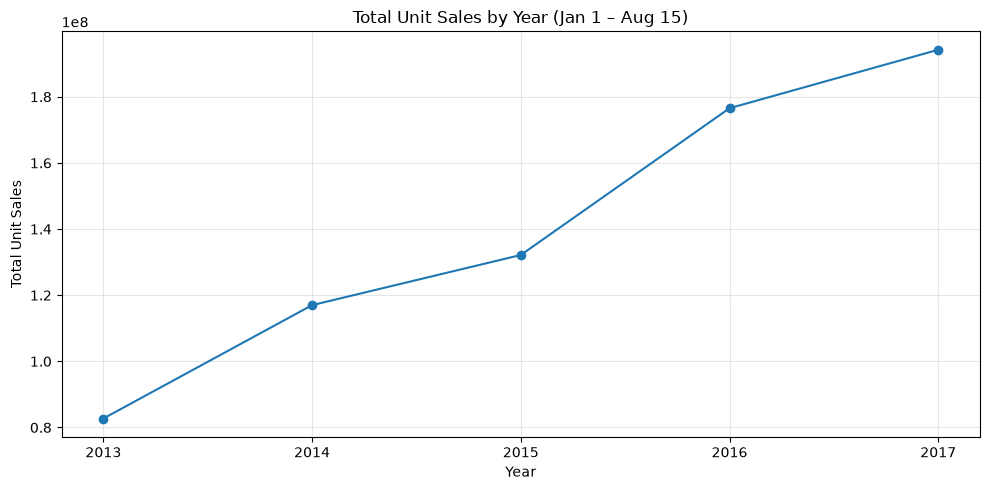

In [137]:
import matplotlib.pyplot as plt

yearly_sales = (
    comparison_period
    .group_by("year")
    .agg(
        pl.col("total_unit_sales").sum()
        .alias("total_unit_sales")
    )
    .sort("year")
)

years = yearly_sales["year"].to_list()
sales = yearly_sales["total_unit_sales"].to_list()

plt.figure(figsize=(10, 5))
plt.plot(years, sales, marker="o")
plt.title("Total Unit Sales by Year (Jan 1 – Aug 15)")
plt.xlabel("Year")
plt.ylabel("Total Unit Sales")
plt.xticks(years)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

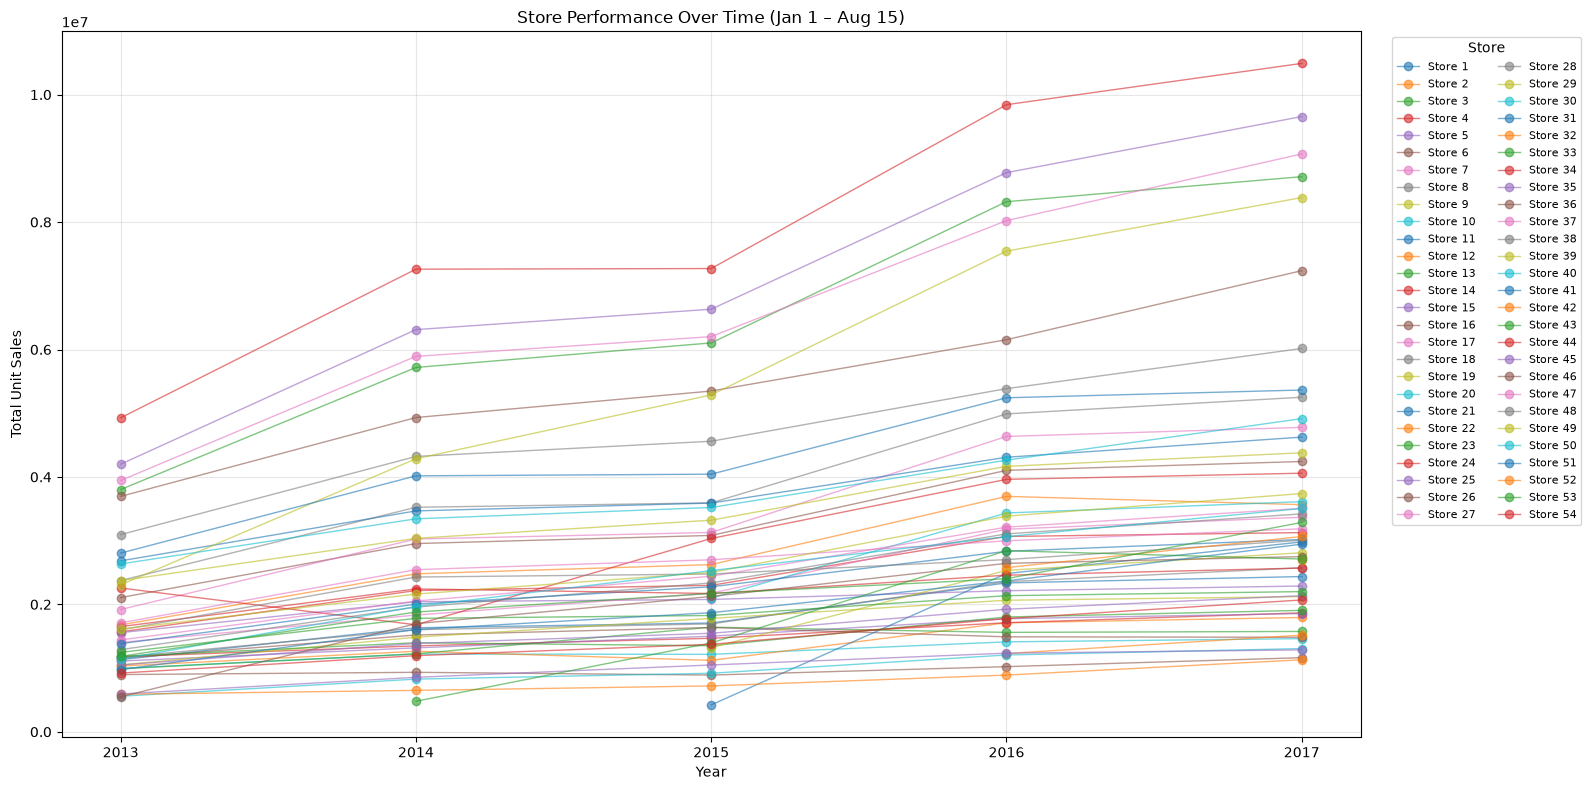

In [138]:
import matplotlib.pyplot as plt

sales_data = comparison_period.to_pandas()

plt.figure(figsize=(16, 8))

for store, group in sales_data.groupby("store_nbr"):
    plt.plot(
        group["year"],
        group["total_unit_sales"],
        marker="o",
        linewidth=1,
        alpha=0.6,
        label=f"Store {store}"
    )

plt.title("Store Performance Over Time (Jan 1 – Aug 15)")
plt.xlabel("Year")
plt.ylabel("Total Unit Sales")
plt.xticks(sorted(sales_data["year"].unique()))
plt.legend(
    title="Store",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=8
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

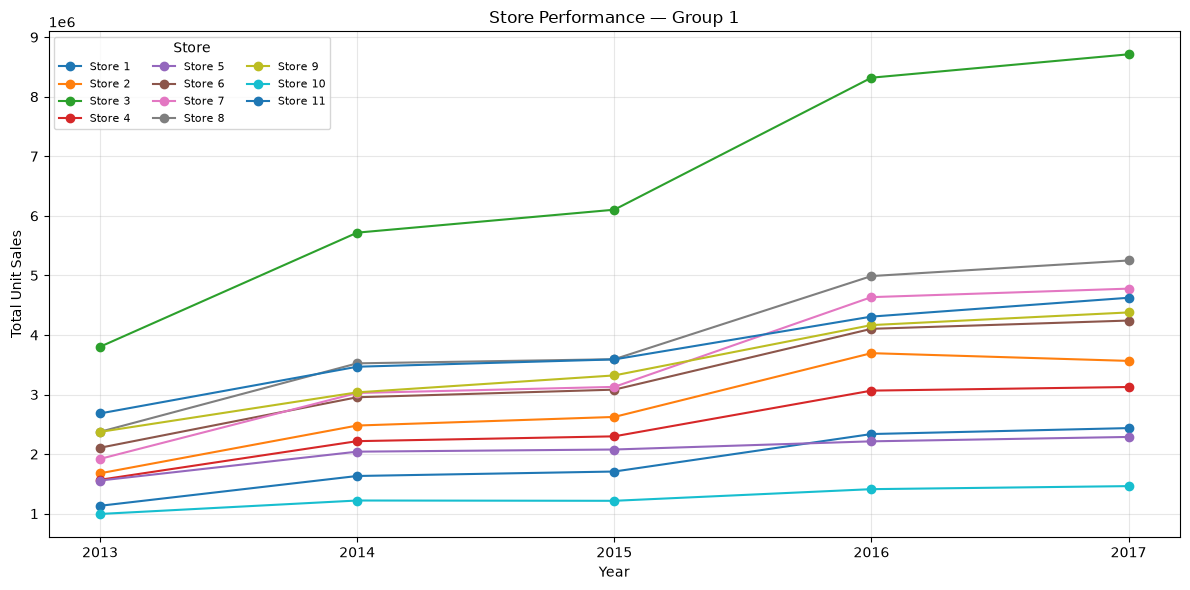

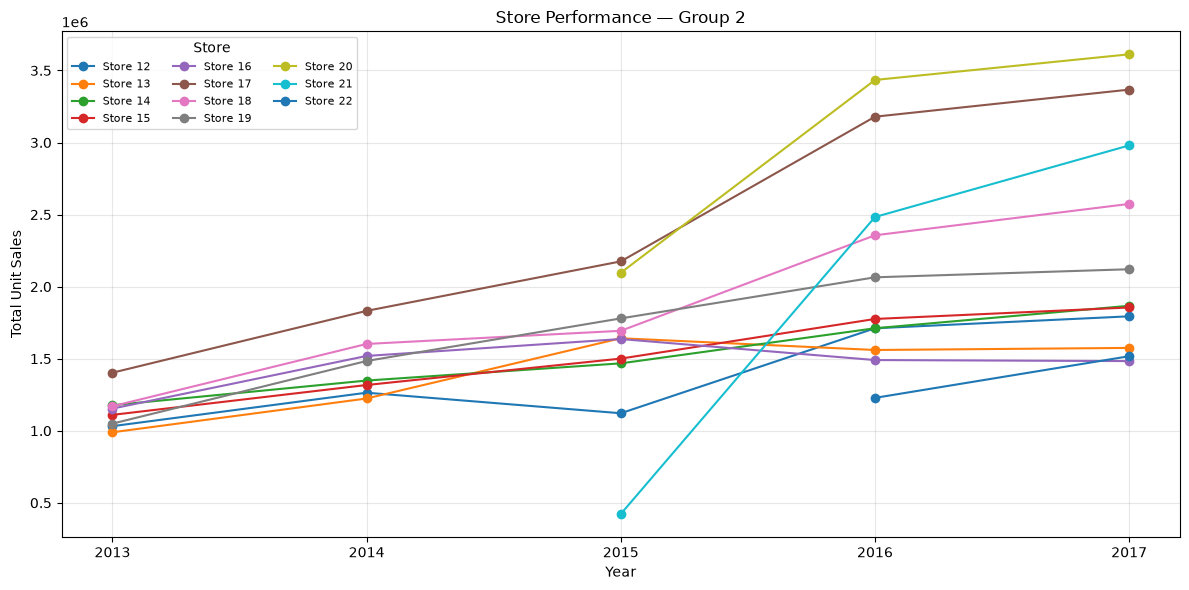

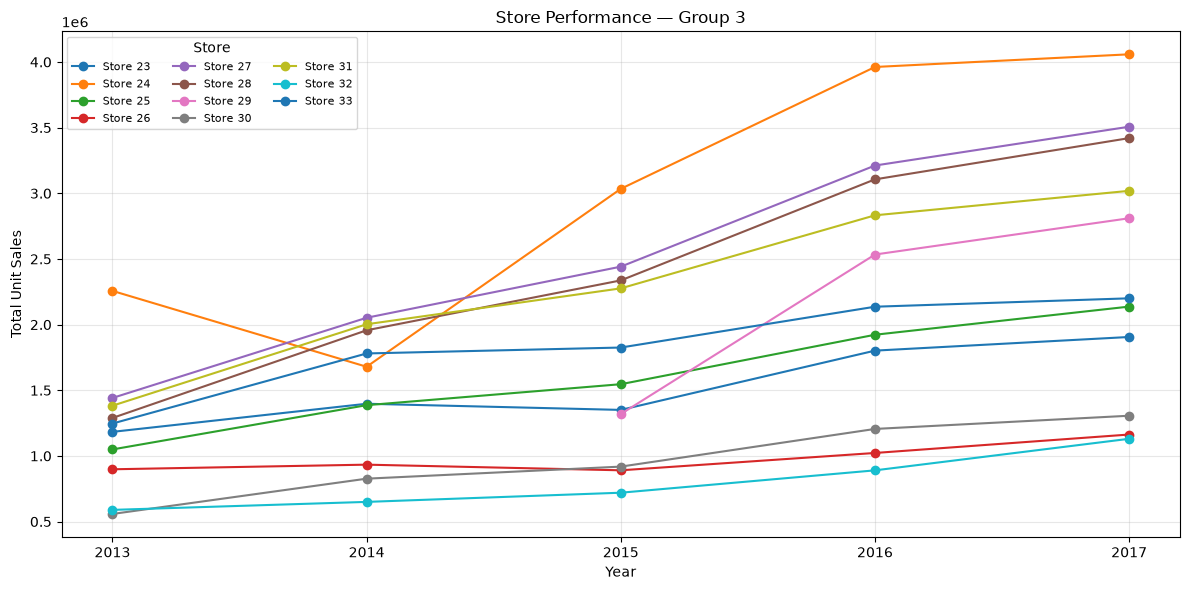

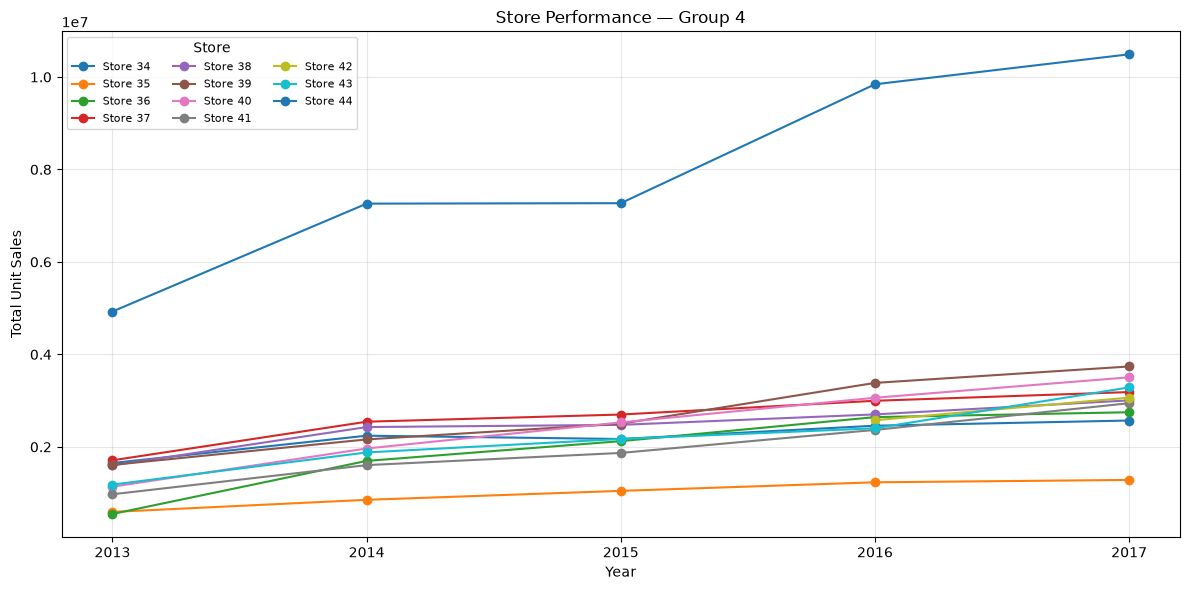

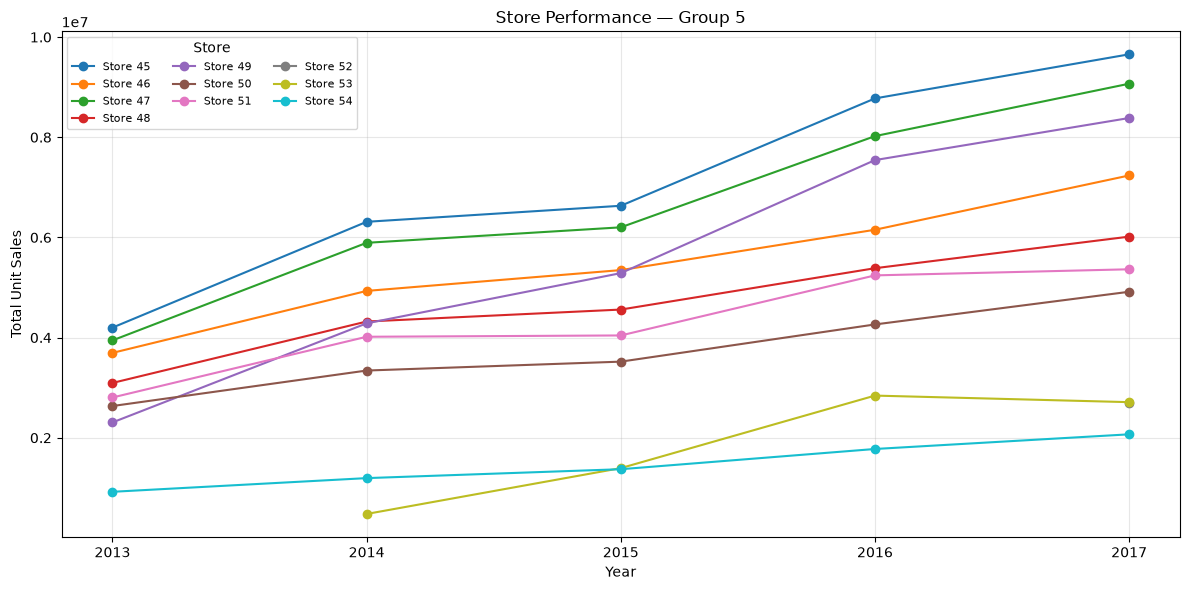

In [139]:
import matplotlib.pyplot as plt

sales_data = comparison_period.to_pandas()

stores = sorted(sales_data["store_nbr"].unique())
groups = [stores[i:i + 11] for i in range(0, len(stores), 11)]

for i, store_group in enumerate(groups, start=1):
    plt.figure(figsize=(12, 6))

    for store in store_group:
        group = (
            sales_data[sales_data["store_nbr"] == store]
            .sort_values("year")
        )

        plt.plot(
            group["year"],
            group["total_unit_sales"],
            marker="o",
            linewidth=1.5,
            label=f"Store {store}"
        )

    plt.title(f"Store Performance — Group {i}")
    plt.xlabel("Year")
    plt.ylabel("Total Unit Sales")
    plt.xticks(sorted(sales_data["year"].unique()))
    plt.legend(title="Store", ncol=3, fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [140]:
store_24 = (
    comparison_period
    .filter(pl.col("store_nbr") == 24)
    .sort("year")
)

print(store_24)

shape: (5, 3)
┌──────┬───────────┬──────────────────┐
│ year ┆ store_nbr ┆ total_unit_sales │
│ ---  ┆ ---       ┆ ---              │
│ i32  ┆ i64       ┆ f64              │
╞══════╪═══════════╪══════════════════╡
│ 2013 ┆ 24        ┆ 2.2570e6         │
│ 2014 ┆ 24        ┆ 1.6792e6         │
│ 2015 ┆ 24        ┆ 3.0342e6         │
│ 2016 ┆ 24        ┆ 3.9620e6         │
│ 2017 ┆ 24        ┆ 4.0585e6         │
└──────┴───────────┴──────────────────┘


In [141]:
store_change = (
    comparison_period
    .filter(pl.col("year").is_in([2013, 2014]))
    .pivot(
        on="year",
        index="store_nbr",
        values="total_unit_sales"
    )
    .rename({
        "2013": "sales_2013",
        "2014": "sales_2014"
    })
    .with_columns(
        (
            (pl.col("sales_2014") - pl.col("sales_2013"))
            / pl.col("sales_2013") * 100
        ).alias("change_pct")
    )
    .sort("change_pct")
)

print(store_change)

shape: (48, 4)
┌───────────┬────────────┬─────────────┬────────────┐
│ store_nbr ┆ sales_2013 ┆ sales_2014  ┆ change_pct │
│ ---       ┆ ---        ┆ ---         ┆ ---        │
│ i64       ┆ f64        ┆ f64         ┆ f64        │
╞═══════════╪════════════╪═════════════╪════════════╡
│ 53        ┆ null       ┆ 479335.1322 ┆ null       │
│ 24        ┆ 2.2570e6   ┆ 1.6792e6    ┆ -25.601455 │
│ 26        ┆ 898359.807 ┆ 933642.6287 ┆ 3.927471   │
│ 32        ┆ 589176.153 ┆ 650059.3894 ┆ 10.333622  │
│ 14        ┆ 1.1773e6   ┆ 1.3484e6    ┆ 14.527795  │
│ …         ┆ …          ┆ …           ┆ …          │
│ 43        ┆ 1.1840e6   ┆ 1.8796e6    ┆ 58.752086  │
│ 41        ┆ 975344.947 ┆ 1.6056e6    ┆ 64.613565  │
│ 40        ┆ 1.1395e6   ┆ 1.9649e6    ┆ 72.429357  │
│ 49        ┆ 2.3068e6   ┆ 4.2850e6    ┆ 85.755091  │
│ 36        ┆ 549366.629 ┆ 1.6966e6    ┆ 208.836057 │
└───────────┴────────────┴─────────────┴────────────┘


In [142]:
store_change_summary = (
    store_change
    .filter(pl.col("change_pct").is_not_null())
    .select([
        (pl.col("change_pct") > 0).sum().alias("stores_increased"),
        (pl.col("change_pct") < 0).sum().alias("stores_decreased"),
        (pl.col("change_pct") == 0).sum().alias("stores_unchanged"),
    ])
)

print(store_change_summary)

shape: (1, 3)
┌──────────────────┬──────────────────┬──────────────────┐
│ stores_increased ┆ stores_decreased ┆ stores_unchanged │
│ ---              ┆ ---              ┆ ---              │
│ u32              ┆ u32              ┆ u32              │
╞══════════════════╪══════════════════╪══════════════════╡
│ 46               ┆ 1                ┆ 0                │
└──────────────────┴──────────────────┴──────────────────┘


In [143]:
change_stats = (
    store_change
    .filter(pl.col("change_pct").is_not_null())
    .select([
        pl.col("change_pct").mean().alias("mean_change_pct"),
        pl.col("change_pct").median().alias("median_change_pct"),
        pl.col("change_pct").min().alias("min_change_pct"),
        pl.col("change_pct").max().alias("max_change_pct"),
    ])
)

print(change_stats)

shape: (1, 4)
┌─────────────────┬───────────────────┬────────────────┬────────────────┐
│ mean_change_pct ┆ median_change_pct ┆ min_change_pct ┆ max_change_pct │
│ ---             ┆ ---               ┆ ---            ┆ ---            │
│ f64             ┆ f64               ┆ f64            ┆ f64            │
╞═════════════════╪═══════════════════╪════════════════╪════════════════╡
│ 41.594687       ┆ 41.344036         ┆ -25.601455     ┆ 208.836057     │
└─────────────────┴───────────────────┴────────────────┴────────────────┘


In [144]:
q1, q3 = (
    store_change
    .filter(pl.col("change_pct").is_not_null())
    .select([
        pl.col("change_pct").quantile(0.25).alias("Q1"),
        pl.col("change_pct").quantile(0.75).alias("Q3")
    ])
    .row(0)
)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = (
    store_change
    .filter(
        pl.col("change_pct").is_not_null()
        & (
            (pl.col("change_pct") < lower_bound)
            | (pl.col("change_pct") > upper_bound)
        )
    )
    .sort("change_pct")
)

print(f"Q1: {q1:.2f}%")
print(f"Q3: {q3:.2f}%")
print(f"IQR: {iqr:.2f} percentage points")
print(f"Lower bound: {lower_bound:.2f}%")
print(f"Upper bound: {upper_bound:.2f}%")

print("\nPotential outliers:")
print(outliers)

Q1: 29.63%
Q3: 48.82%
IQR: 19.19 percentage points
Lower bound: 0.85%
Upper bound: 77.61%

Potential outliers:
shape: (3, 4)
┌───────────┬────────────┬────────────┬────────────┐
│ store_nbr ┆ sales_2013 ┆ sales_2014 ┆ change_pct │
│ ---       ┆ ---        ┆ ---        ┆ ---        │
│ i64       ┆ f64        ┆ f64        ┆ f64        │
╞═══════════╪════════════╪════════════╪════════════╡
│ 24        ┆ 2.2570e6   ┆ 1.6792e6   ┆ -25.601455 │
│ 49        ┆ 2.3068e6   ┆ 4.2850e6   ┆ 85.755091  │
│ 36        ┆ 549366.629 ┆ 1.6966e6   ┆ 208.836057 │
└───────────┴────────────┴────────────┴────────────┘


C:\Users\Mahmoud\AppData\Local\Temp\ipykernel_19172\78215663.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


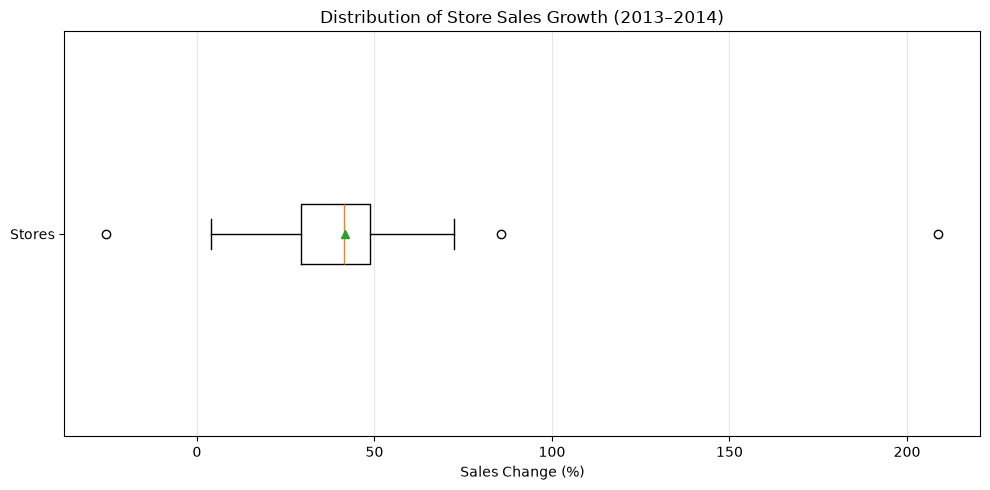

In [145]:
import matplotlib.pyplot as plt

change_pct = (
    store_change
    .filter(pl.col("change_pct").is_not_null())
    ["change_pct"]
    .to_list()
)

plt.figure(figsize=(10, 5))

plt.boxplot(
    change_pct,
    vert=False,
    showmeans=True
)

plt.title("Distribution of Store Sales Growth (2013–2014)")
plt.xlabel("Sales Change (%)")
plt.yticks([1], ["Stores"])
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

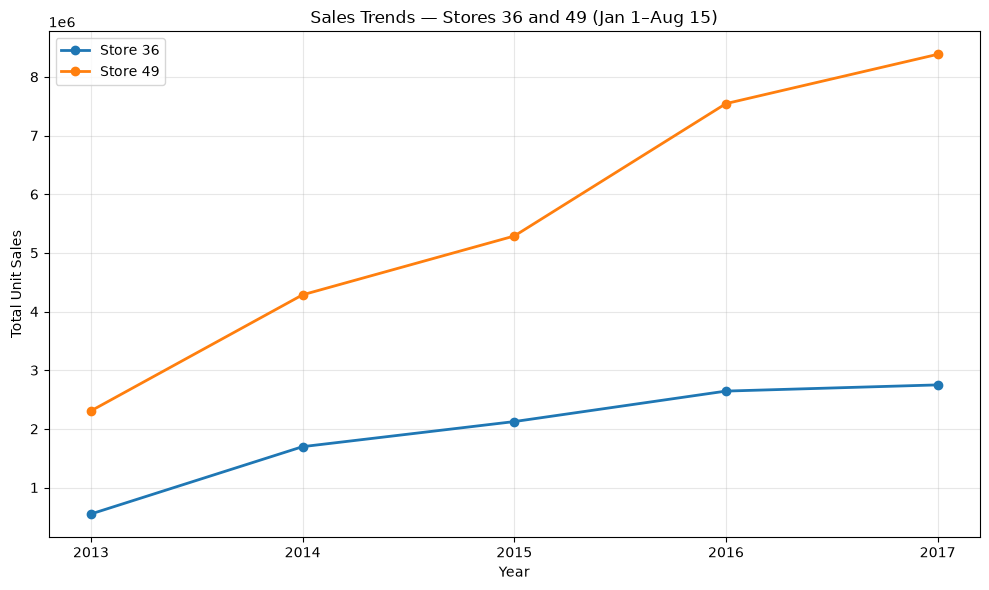

In [146]:
import matplotlib.pyplot as plt
import polars as pl

selected_stores = [36, 49]

store_trends = (
    comparison_period
    .filter(pl.col("store_nbr").is_in(selected_stores))
    .sort(["store_nbr", "year"])
)

fig, ax = plt.subplots(figsize=(10, 6))

for store in selected_stores:
    data = (
        store_trends
        .filter(pl.col("store_nbr") == store)
    )

    ax.plot(
        data["year"].to_list(),
        data["total_unit_sales"].to_list(),
        marker="o",
        linewidth=2,
        label=f"Store {store}"
    )

ax.set_title("Sales Trends — Stores 36 and 49 (Jan 1–Aug 15)")
ax.set_xlabel("Year")
ax.set_ylabel("Total Unit Sales")
ax.set_xticks([2013, 2014, 2015, 2016, 2017])
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [147]:
selected_stores = [24, 36, 49]

(
    comparison_period
    .filter(pl.col("store_nbr").is_in(selected_stores))
    .pivot(
        on="year",
        index="store_nbr",
        values="total_unit_sales"
    )
    .sort("store_nbr")
)

store_nbr,2013,2014,2015,2016,2017
i64,f64,f64,f64,f64,f64
24,2.2570e6,1.6792e6,3.0342e6,3.9620e6,4.0585e6
36,549366.629,1.6966e6,2.1242e6,2.6438e6,2.7494e6
49,2.3068e6,4.2850e6,5.2875e6,7.5442e6,8.3842e6


In [148]:
selected_stores = [24, 36, 49]

store_growth = (
    comparison_period
    .filter(pl.col("store_nbr").is_in(selected_stores))
    .pivot(
        on="year",
        index="store_nbr",
        values="total_unit_sales"
    )
    .sort("store_nbr")
)

years = ["2013", "2014", "2015", "2016", "2017"]

for i in range(len(years) - 1):
    previous_year = years[i]
    current_year = years[i + 1]

    store_growth = store_growth.with_columns(
        (
            (pl.col(current_year) - pl.col(previous_year))
            / pl.col(previous_year) * 100
        ).alias(f"growth_{previous_year}_{current_year}_pct")
    )

store_growth

store_nbr,2013,2014,2015,2016,2017,growth_2013_2014_pct,growth_2014_2015_pct,growth_2015_2016_pct,growth_2016_2017_pct
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
24,2.2570e6,1.6792e6,3.0342e6,3.9620e6,4.0585e6,-25.601455,80.695186,30.581371,2.433715
36,549366.629,1.6966e6,2.1242e6,2.6438e6,2.7494e6,208.836057,25.200671,24.460546,3.995397
49,2.3068e6,4.2850e6,5.2875e6,7.5442e6,8.3842e6,85.755091,23.394506,42.681412,11.134796


In [149]:
growth_2016_2017 = (
    comparison_period
    .filter(pl.col("year").is_in([2016, 2017]))
    .pivot(
        on="year",
        index="store_nbr",
        values="total_unit_sales"
    )
    .rename({
        "2016": "sales_2016",
        "2017": "sales_2017"
    })
    .with_columns(
        (
            (pl.col("sales_2017") - pl.col("sales_2016"))
            / pl.col("sales_2016") * 100
        ).alias("growth_pct")
    )
    .filter(pl.col("growth_pct").is_not_null())
)

growth_2016_2017.select([
    pl.col("growth_pct").median().alias("median_growth_pct"),
    pl.col("growth_pct").mean().alias("mean_growth_pct"),
    pl.col("growth_pct").min().alias("min_growth_pct"),
    pl.col("growth_pct").max().alias("max_growth_pct"),
])

median_growth_pct,mean_growth_pct,min_growth_pct,max_growth_pct
f64,f64,f64,f64
6.58194,8.81406,-4.604928,36.782031


C:\Users\Mahmoud\AppData\Local\Temp\ipykernel_19172\2320570592.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(growth_values, vert=False, showmeans=True)


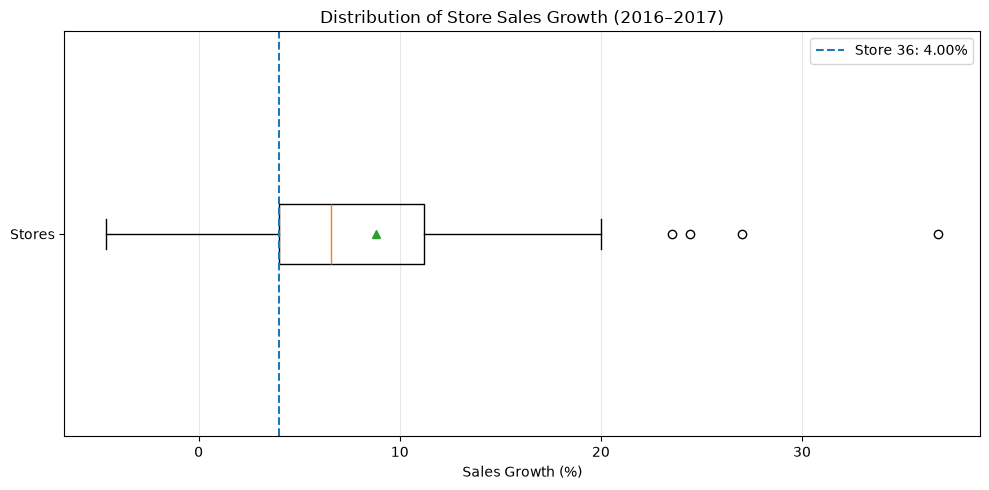

In [150]:
import matplotlib.pyplot as plt

growth_values = growth_2016_2017["growth_pct"].to_list()
store_36_growth = (
    growth_2016_2017
    .filter(pl.col("store_nbr") == 36)["growth_pct"]
    .item()
)

plt.figure(figsize=(10, 5))
plt.boxplot(growth_values, vert=False, showmeans=True)
plt.axvline(
    store_36_growth,
    linestyle="--",
    label=f"Store 36: {store_36_growth:.2f}%"
)
plt.title("Distribution of Store Sales Growth (2016–2017)")
plt.xlabel("Sales Growth (%)")
plt.yticks([1], ["Stores"])
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [151]:
growth_2016_2017.select([
    pl.col("growth_pct").quantile(0.25).alias("Q1"),
    pl.col("growth_pct").median().alias("Median"),
    pl.col("growth_pct").quantile(0.75).alias("Q3")
])

Q1,Median,Q3
f64,f64,f64
3.995397,6.58194,11.225125


In [152]:
store_total_sales = (
    train_df
    .group_by("store_nbr")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort("total_unit_sales", descending=True)
    .collect()
)

store_total_sales

store_nbr,total_unit_sales
i64,f64
44,6.2088e7
45,5.4498e7
47,5.0948e7
3,5.0482e7
49,4.3420e7
…,…
35,7.6767e6
30,7.3819e6
32,5.9518e6


In [153]:
store_total_sales = (
    store_total_sales
    .with_columns(
        (
            pl.col("total_unit_sales")
            / pl.col("total_unit_sales").sum()
            * 100
        ).alias("sales_contribution_pct")
    )
    .with_columns(
        pl.col("sales_contribution_pct")
        .cum_sum()
        .alias("cumulative_contribution_pct")
    )
)

store_total_sales

store_nbr,total_unit_sales,sales_contribution_pct,cumulative_contribution_pct
i64,f64,f64,f64
44,6.2088e7,5.783062,5.783062
45,5.4498e7,5.076145,10.859206
47,5.0948e7,4.745512,15.604719
3,5.0482e7,4.702069,20.306788
49,4.3420e7,4.044306,24.351095
…,…,…,…
35,7.6767e6,0.715034,98.125945
30,7.3819e6,0.687577,98.813521
32,5.9518e6,0.554371,99.367892


In [154]:
top_store_contribution = (
    store_total_sales
    .head(10)
    .select([
        pl.col("sales_contribution_pct").sum()
        .alias("top_10_contribution_pct")
    ])
)

top_store_contribution

top_10_contribution_pct
f64
40.174809


In [155]:
stores_pl = pl.from_pandas(stores_df)

store_type_performance = (
    store_total_sales
    .join(
        stores_pl.select(["store_nbr", "type"]),
        on="store_nbr",
        how="left"
    )
    .group_by("type")
    .agg([
        pl.col("total_unit_sales").sum().alias("total_unit_sales"),
        pl.col("store_nbr").n_unique().alias("number_of_stores"),
        pl.col("total_unit_sales").mean().alias("avg_sales_per_store")
    ])
    .sort("total_unit_sales", descending=True)
)

store_type_performance

type,total_unit_sales,number_of_stores,avg_sales_per_store
str,f64,u32,f64
"""A""",3.5304e8,9,3.9227e7
"""D""",3.5106e8,18,1.9504e7
"""C""",1.6443e8,15,1.0962e7
"""B""",1.4525e8,8,1.8156e7
"""E""",5.9820e7,4,1.4955e7


In [156]:
type_a_stores = (
    store_total_sales
    .join(
        stores_pl.select(["store_nbr", "type"]),
        on="store_nbr",
        how="left"
    )
    .filter(pl.col("type") == "A")
    .sort("total_unit_sales", descending=True)
)

type_a_stores

store_nbr,total_unit_sales,sales_contribution_pct,cumulative_contribution_pct,type
i64,f64,f64,f64,str
44,6.2088e7,5.783062,5.783062,"""A"""
45,5.4498e7,5.076145,10.859206,"""A"""
47,5.0948e7,4.745512,15.604719,"""A"""
49,4.3420e7,4.044306,24.351095,"""A"""
46,4.1896e7,3.902352,28.253446,"""A"""
48,3.5933e7,3.346944,31.60039,"""A"""
51,3.2911e7,3.065496,34.665887,"""A"""
50,2.8653e7,2.668847,40.174809,"""A"""
52,2.6962e6,0.251131,100.0,"""A"""


In [157]:
store_type_variability = (
    store_total_sales
    .join(
        stores_pl.select(["store_nbr", "type"]),
        on="store_nbr",
        how="left"
    )
    .group_by("type")
    .agg([
        pl.col("total_unit_sales").median().alias("median_sales"),
        pl.col("total_unit_sales").min().alias("min_sales"),
        pl.col("total_unit_sales").max().alias("max_sales"),
        pl.col("total_unit_sales").std().alias("std_sales")
    ])
    .sort("type")
)

store_type_variability

type,median_sales,min_sales,max_sales,std_sales
str,f64,f64,f64,f64
"""A""",4.1896e7,2.6962e6,6.2088e7,1.7374e7
"""B""",1.7419e7,9.2555e6,2.8326e7,6.6328e6
"""C""",1.0986e7,4.0902e6,1.8396e7,3.9497e6
"""D""",1.8884e7,7.7551e6,5.0482e7,1.0004e7
"""E""",1.5857e7,9.7232e6,1.8383e7,3.7114e6


In [158]:
store_type_cv = (
    store_total_sales
    .join(
        stores_pl.select(["store_nbr", "type"]),
        on="store_nbr",
        how="left"
    )
    .group_by("type")
    .agg([
        pl.col("total_unit_sales").mean().alias("mean_sales"),
        pl.col("total_unit_sales").std().alias("std_sales")
    ])
    .with_columns(
        (
            pl.col("std_sales")
            / pl.col("mean_sales")
            * 100
        ).alias("cv_pct")
    )
    .sort("cv_pct", descending=True)
)

store_type_cv

type,mean_sales,std_sales,cv_pct
str,f64,f64,f64
"""D""",1.9504e7,1.0004e7,51.292828
"""A""",3.9227e7,1.7374e7,44.291757
"""B""",1.8156e7,6.6328e6,36.532114
"""C""",1.0962e7,3.9497e6,36.02979
"""E""",1.4955e7,3.7114e6,24.816947


In [159]:
store_sales_sensitivity = (
    train_df
    .group_by("store_nbr")
    .agg([
        pl.col("unit_sales")
        .sum()
        .alias("net_unit_sales"),

        pl.col("unit_sales")
        .filter(pl.col("unit_sales") >= 0)
        .sum()
        .alias("non_negative_unit_sales"),

        pl.col("unit_sales")
        .filter(pl.col("unit_sales") < 0)
        .sum()
        .alias("negative_unit_sales_total")
    ])
    .with_columns([
        pl.col("net_unit_sales")
        .rank(method="ordinal", descending=True)
        .alias("net_sales_rank"),

        pl.col("non_negative_unit_sales")
        .rank(method="ordinal", descending=True)
        .alias("non_negative_sales_rank")
    ])
    .with_columns(
        (
            pl.col("non_negative_sales_rank")
            - pl.col("net_sales_rank")
        ).alias("rank_change")
    )
    .sort("rank_change", descending=True)
    .collect()
)

store_sales_sensitivity

store_nbr,net_unit_sales,non_negative_unit_sales,negative_unit_sales_total,net_sales_rank,non_negative_sales_rank,rank_change
i64,f64,f64,f64,u32,u32,u32
15,1.1451e7,1.1452e7,-822.129,37,37,0
39,2.0252e7,2.0257e7,-5026.698,17,17,0
43,1.6392e7,1.6392e7,-566.56,27,27,0
11,2.8326e7,2.8327e7,-1477.677,11,11,0
33,1.4178e7,1.4179e7,-832.467,31,31,0
…,…,…,…,…,…,…
18,1.3247e7,1.3266e7,-18463.369,33,33,0
28,1.8383e7,1.8384e7,-1097.871,23,23,0
41,1.4991e7,1.4992e7,-737.022,30,30,0


In [160]:
store_sales_sensitivity.select([
    (pl.col("rank_change") != 0)
    .sum()
    .alias("stores_with_rank_change"),

    pl.col("rank_change")
    .abs()
    .max()
    .alias("max_absolute_rank_change"),

    (
        pl.col("non_negative_unit_sales")
        - pl.col("net_unit_sales")
    )
    .sum()
    .alias("total_negative_sales_adjustment"),

    (
        (
            pl.col("non_negative_unit_sales")
            - pl.col("net_unit_sales")
        ).sum()
        / pl.col("net_unit_sales").sum()
        * 100
    )
    .alias("adjustment_pct_of_net_sales")
])

stores_with_rank_change,max_absolute_rank_change,total_negative_sales_adjustment,adjustment_pct_of_net_sales
u32,u32,f64,f64
0,0,143580.8275,0.013374


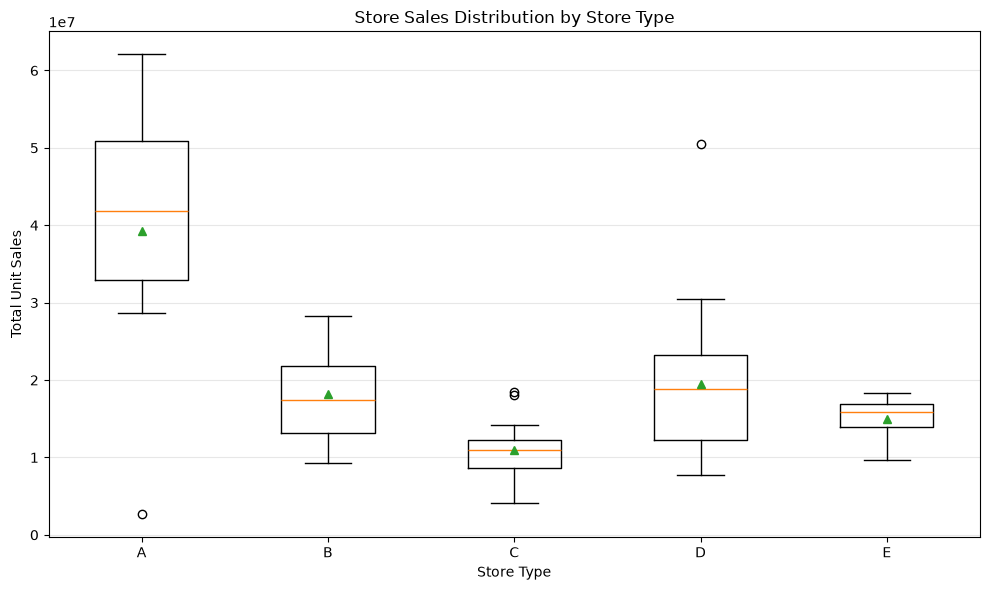

In [161]:
import matplotlib.pyplot as plt
import polars as pl

store_type_sales = (
    store_total_sales
    .join(
        stores_pl.select(["store_nbr", "type"]),
        on="store_nbr",
        how="left"
    )
)

types = ["A", "B", "C", "D", "E"]

sales_by_type = [
    store_type_sales
    .filter(pl.col("type") == store_type)
    .get_column("total_unit_sales")
    .to_list()
    for store_type in types
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    sales_by_type,
    tick_labels=types,
    showmeans=True
)

plt.title("Store Sales Distribution by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Total Unit Sales")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [162]:
store_type_box_stats = (
    store_type_sales
    .group_by("type")
    .agg([
        pl.col("total_unit_sales")
        .quantile(0.25)
        .alias("Q1"),

        pl.col("total_unit_sales")
        .median()
        .alias("Median"),

        pl.col("total_unit_sales")
        .quantile(0.75)
        .alias("Q3"),

        pl.col("total_unit_sales")
        .min()
        .alias("Min"),

        pl.col("total_unit_sales")
        .max()
        .alias("Max"),
    ])
    .with_columns(
        (pl.col("Q3") - pl.col("Q1")).alias("IQR")
    )
    .with_columns([
        (pl.col("Q1") - 1.5 * pl.col("IQR"))
        .alias("Lower_Bound"),

        (pl.col("Q3") + 1.5 * pl.col("IQR"))
        .alias("Upper_Bound"),
    ])
    .sort("type")
)

store_type_box_stats

type,Q1,Median,Q3,Min,Max,IQR,Lower_Bound,Upper_Bound
str,f64,f64,f64,f64,f64,f64,f64,f64
"""A""",3.2911e7,4.1896e7,5.0948e7,2.6962e6,6.2088e7,1.8037e7,5.8562e6,7.8004e7
"""B""",1.3247e7,1.7419e7,2.0252e7,9.2555e6,2.8326e7,7.0051e6,2.7395e6,3.0760e7
"""C""",9.6139e6,1.0986e7,1.3050e7,4.0902e6,1.8396e7,3.4356e6,4.4605e6,1.8203e7
"""D""",1.1651e7,1.8884e7,2.3768e7,7.7551e6,5.0482e7,1.2116e7,-6.5231e6,4.1942e7
"""E""",1.5322e7,1.5857e7,1.6392e7,9.7232e6,1.8383e7,1.0693e6,1.3719e7,1.7996e7


In [163]:
store_type_outliers = (
    store_type_sales
    .join(
        store_type_box_stats.select([
            "type",
            "Lower_Bound",
            "Upper_Bound",
        ]),
        on="type",
        how="left"
    )
    .filter(
        (pl.col("total_unit_sales") < pl.col("Lower_Bound"))
        | (pl.col("total_unit_sales") > pl.col("Upper_Bound"))
    )
    .select([
        "store_nbr",
        "type",
        "total_unit_sales",
        "Lower_Bound",
        "Upper_Bound",
    ])
    .sort("type", "total_unit_sales")
)

store_type_outliers

store_nbr,type,total_unit_sales,Lower_Bound,Upper_Bound
i64,str,f64,f64,f64
52,"""A""",2.6962e6,5.8562e6,7.8004e7
22,"""C""",4.0902e6,4.4605e6,1.8203e7
40,"""C""",1.8396e7,4.4605e6,1.8203e7
3,"""D""",5.0482e7,-6.5231e6,4.1942e7
29,"""E""",9.7232e6,1.3719e7,1.7996e7
28,"""E""",1.8383e7,1.3719e7,1.7996e7


# Store Performance Analysis

## 1. Analysis Objectives

The objective of this section is to investigate differences in sales volume across stores, evaluate year-over-year performance, measure each store's contribution to overall sales, and compare performance across store types.

The analysis focuses on:

- Total unit sales and store rankings.
- Year-over-year sales growth.
- Sales contribution and cumulative contribution.
- Store-type performance.
- Relative variation in sales across stores within each type.

**Important:** Sales are measured in units sold, not monetary revenue or profit.

---

## 2. Dataset Scope and Store Coverage

The cleaned sales dataset covers January 1, 2013, through August 15, 2017.

- Number of stores in the dataset: 54.
- Number of rows in the cleaned sales dataset: 125,497,040.
- Store-level sales were aggregated to investigate differences in performance.

### Annual Store Coverage

The number of stores with recorded sales varied by year:

| Year | Stores with recorded sales |
|---|---:|
| 2013 | 47 |
| 2014 | 48 |
| 2015 | 53 |
| 2016 | 53 |
| 2017 | 54 |

The annual counts indicate that not all stores have recorded sales in every year. Consequently, year-over-year comparisons must account for missing store-year combinations.

---

## 3. Annual Store Sales and Comparable-Period Analysis

Annual sales were calculated by grouping observations by year and store, then summing `unit_sales`.

However, 2017 contains data only through August 15. Comparing its total directly with full-year totals would produce an unfair comparison.

### Comparable Period

To make annual comparisons more consistent, the analysis was restricted to January 1 through August 15 for every year.

This approach compares the same calendar window across years, reducing the distortion caused by comparing a partial year with complete years.

Store-level trends were visualized using multiple line plots, divided into groups of approximately 11 stores per plot to improve readability.

### Selected Store Growth Results

| Store | 2013 | 2014 | 2015 | 2016 | 2017 |
|---|---:|---:|---:|---:|---:|
| 24 | 2.257M | 1.679M | 3.034M | 3.962M | 4.059M |
| 36 | 0.549M | 1.697M | 2.124M | 2.644M | 2.749M |
| 49 | 2.307M | 4.285M | 5.288M | 7.544M | 8.384M |

*Values represent unit sales from January 1 through August 15 of each year.*

### Year-over-Year Growth: 2013–2014

| Store | Growth rate |
|---|---:|
| 24 | -25.60% |
| 36 | +208.84% |
| 49 | +85.76% |

These stores illustrate substantially different growth patterns. Store 24 experienced a decline, whereas Stores 36 and 49 recorded strong increases.

Across 47 stores with valid comparisons:

- Mean growth: 41.59%.
- Median growth: 41.34%.
- Minimum growth: -25.60%.
- Maximum growth: +208.84%.
- 46 stores increased their sales.
- One store decreased its sales.
- No stores had unchanged sales.

One additional store had no valid 2013 baseline for this comparison.

### IQR-Based Outlier Investigation

The interquartile range (IQR) method was used to identify unusually high or low growth rates.

| Statistic | Growth rate |
|---|---:|
| First quartile (Q1) | 29.63% |
| Third quartile (Q3) | 48.82% |
| IQR | 19.19 percentage points |
| Lower bound | 0.85% |
| Upper bound | 77.61% |

Stores 24, 36, and 49 were identified as potential outliers in 2013–2014 growth.

These are statistical outliers, not necessarily data errors. Their growth patterns warrant further investigation before explanations can be established.

### Year-over-Year Growth: 2016–2017

The comparable-period analysis produced the following distribution:

| Statistic | Growth rate |
|---|---:|
| Mean | 8.81% |
| Median | 6.58% |
| Minimum | -4.60% |
| Maximum | +36.78% |
| Q1 | 4.00% |
| Q3 | 11.23% |

Store 36 grew by approximately 4.00%, close to the first quartile. Its sales continued to increase, but its growth was lower than the median store's growth.

This distinction matters: slower growth does not necessarily mean declining sales.

The comparison demonstrates that store growth rates varied substantially across years and that unusually high growth in one period should not be assumed to continue in subsequent periods.

---

## 4. Overall Store Ranking

Stores were ranked by total unit sales across the entire available dataset, from January 1, 2013, through August 15, 2017.

### Top Five Stores

| Rank | Store | Total unit sales |
|---:|---:|---:|
| 1 | 44 | 62.088M |
| 2 | 45 | 54.498M |
| 3 | 47 | 50.948M |
| 4 | 3 | 50.482M |
| 5 | 49 | 43.420M |

### Bottom Five Stores

| Rank | Store | Total unit sales |
|---:|---:|---:|
| 50 | 35 | 7.677M |
| 51 | 30 | 7.382M |
| 52 | 32 | 5.952M |
| 53 | 22 | 4.090M |
| 54 | 52 | 2.696M |

Store 44 recorded the highest total unit sales, while Store 52 recorded the lowest.

The difference between the highest and lowest stores indicates substantial variation in sales volume across the store network. However, total sales alone do not explain why this difference exists.

---

## 5. Store Sales Contribution

Each store's contribution was calculated as its total unit sales divided by total unit sales across all stores.

The cumulative contribution was then calculated after sorting stores in descending order of total sales.

### Selected Contribution Results

| Store | Contribution to total sales |
|---|---:|
| 44 | 5.78% |
| 45 | 5.08% |
| 47 | 4.75% |
| 3 | 4.70% |
| 49 | 4.04% |

- Top five stores: approximately 24.35% of total unit sales.
- Top ten stores: approximately 40.17% of total unit sales.
- Store 52: approximately 0.25% of total unit sales.

The top ten stores represent approximately 18.5% of the 54-store network but account for about 40.17% of total unit sales.

This indicates that sales volume is not distributed equally across stores, with a relatively small group contributing a substantial share of the total.

This finding describes sales concentration, not profit concentration, because product prices and store-level operating costs were not included in this calculation.

---

## 6. Store-Type Performance

Store-level totals were joined with the store metadata to compare sales across store types.

For each type, the analysis calculated:

- Total unit sales.
- Number of stores.
- Average unit sales per store.

### Store-Type Results

| Type | Total unit sales | Number of stores | Average sales per store |
|---|---:|---:|---:|
| A | 353.04M | 9 | 39.227M |
| D | 351.06M | 18 | 19.504M |
| C | 164.43M | 15 | 10.962M |
| B | 145.25M | 8 | 18.156M |
| E | 59.82M | 4 | 14.955M |

### Key Findings

**Type A**
- Recorded the highest total sales and the highest average sales per store.
- Achieved approximately the same total sales volume as Type D with half as many stores.

**Type D**
- Recorded total sales similar to Type A.
- Had a much lower average sales volume per store because its network contains more stores.

**Type C**
- Had the lowest average sales per store among the five types.

**Type B**
- Had lower total sales than Type D but a higher average sales volume per store.

**Type E**
- Had the lowest total sales overall, but it also had only four stores.

These results show why total sales and average sales per store should be considered together. A store type with more branches can generate high total sales without having the highest average sales per branch.

The results are descriptive and do not establish that store type itself causes differences in sales.

---

## 7. Variation Within Store Types

The analysis also examined how much store-level sales varied within each type.

The following statistics were calculated:

- Median sales.
- Minimum sales.
- Maximum sales.
- Standard deviation.

### Within-Type Variability

| Type | Median sales | Minimum sales | Maximum sales | Standard deviation |
|---|---:|---:|---:|---:|
| A | 41.896M | 2.696M | 62.088M | 17.374M |
| B | 17.419M | 9.256M | 28.326M | 6.633M |
| C | 10.986M | 4.090M | 18.396M | 3.950M |
| D | 18.884M | 7.755M | 50.482M | 10.004M |
| E | 15.857M | 9.723M | 18.383M | 3.711M |

### Interpretation

Type A had the largest standard deviation and a particularly wide range of sales. Its minimum was much lower than its median, reflecting the presence of at least one store with considerably lower total sales than the typical Type A store.

Type D also showed substantial dispersion, with its maximum considerably higher than its median.

Type E had the smallest absolute standard deviation. However, absolute dispersion alone is not sufficient to compare groups with different average sales levels.

The median complements the mean because it is less sensitive to extreme values and provides a useful measure of the typical store's sales volume.

---

## 8. Relative Variation: Coefficient of Variation

To compare dispersion relative to each store type's average sales, the coefficient of variation (CV) was calculated:

CV = (Standard deviation / Mean) × 100

### Results

| Type | Mean sales | Standard deviation | CV |
|---|---:|---:|---:|
| D | 19.504M | 10.004M | 51.29% |
| A | 39.227M | 17.374M | 44.29% |
| B | 18.156M | 6.633M | 36.53% |
| C | 10.962M | 3.950M | 36.03% |
| E | 14.955M | 3.711M | 24.82% |

### Interpretation

- Type D had the highest relative dispersion, with a CV of approximately 51.29%.
- Type A had the highest absolute standard deviation but the second-highest CV.
- Type E had the lowest CV, indicating the least relative dispersion among the five store types.
- Types B and C had similar CV values.

The comparison between Types A and D illustrates the distinction between absolute and relative variability. Type A has a larger standard deviation, but Type D's standard deviation is larger relative to its own mean.

A lower CV indicates greater relative similarity in sales volumes within a group; it does not automatically indicate better business performance or operational efficiency.

---

## 9. Data Quality and Interpretation Considerations

Several limitations must be considered when interpreting the findings:

1. **Unit sales are not revenue.** Product prices are not included in these calculations, so financial performance cannot be inferred directly.

2. **Negative unit sales were retained.** The cleaned dataset contains 7,795 negative `unit_sales` rows. These may represent returns or adjustments, but their exact meaning has not been established. The calculated totals therefore reflect net recorded unit sales, including negative values.

3. **Store coverage varies across years.** Some stores lack recorded sales for earlier years. Missing store-year combinations should not automatically be treated as zero sales.

4. **The final year is partial.** Year-over-year comparisons used January 1 through August 15 for every year, while overall store rankings and contributions used the entire available dataset.

5. **Store-type comparisons may be affected by other variables.** Location, opening date, customer demand, product assortment, and other factors may contribute to observed differences.

6. **Statistical outliers require investigation.** Unusual growth rates identify stores worth examining but do not, by themselves, establish errors or explain the underlying causes.

7. **Store rankings do not measure efficiency.** A high sales volume may reflect a larger store, more customers, a different product mix, or other factors rather than better operational performance.

---

## 10. Store Performance: Overall Conclusions

The analysis identified substantial differences in unit sales across stores, in their contributions to total sales, and in their year-over-year growth patterns.

Store 44 was the highest-selling store over the available period, while Store 52 was the lowest-selling. The top ten stores contributed approximately 40.17% of total unit sales.

Store-type comparisons showed that Type A had the highest total and average sales per store, whereas Type D had the greatest relative variation in store-level sales. Type E showed the lowest relative variation.

The year-over-year analysis also revealed that store growth rates can vary considerably across periods. The use of a consistent calendar window improved comparability, while the IQR method helped identify unusual growth rates for further investigation.

These findings establish a descriptive baseline for store performance. They do not yet explain the underlying drivers of sales differences.

The next stage will investigate product-level sales to determine how sales volume is distributed across individual products and product families.

### 11. Sensitivity Analysis: Negative Unit Sales

A sensitivity analysis was conducted to evaluate whether negative `unit_sales` values materially affected store-level sales totals and rankings.

Two scenarios were compared:

- **Scenario A:** Net unit sales, including negative values.
- **Scenario B:** Unit sales calculated using only observations with `unit_sales >= 0`.

#### Results

- Number of stores with a changed ranking: 0 out of 54.
- Maximum absolute ranking change: 0 positions.
- Total difference between the two scenarios: approximately 143,580.83 units.
- Difference as a percentage of net unit sales: approximately 0.0134%.

#### Conclusion

Store rankings remained unchanged after excluding negative unit sales, and the overall adjustment was very small relative to total net unit sales.

Negative observations were retained in the primary analysis because their business meaning has not yet been confirmed. Excluding them was used only as a sensitivity test, not as a data-cleaning decision.

The effect of negative unit sales should be reconsidered if subsequent analyses focus on product returns, transaction behavior, or other questions for which negative observations may have a distinct business meaning.

In [164]:
items_pl.select(
    pl.len().alias("total_rows"),
    pl.col("item_nbr").n_unique().alias("unique_items")
)

total_rows,unique_items
u32,u32
4100,4100


In [165]:
missing_items = (
    train_df
    .select("item_nbr")
    .unique()
    .join(
        items_pl.select("item_nbr").lazy(),
        on="item_nbr",
        how="anti"
    )
)

missing_items.collect()

item_nbr
i64


In [166]:
item_sales = (
    train_df
    .group_by("item_nbr")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
)

item_sales.collect()

item_nbr,total_unit_sales
i64,f64
809184,135087.0
1076335,215585.0
1053945,164605.0
833396,239539.0
461432,42030.0
…,…
2081050,30155.0
2081161,61686.0
2087543,29096.0


In [167]:
item_family_sales = (
    item_sales
    .join(
        items_pl.lazy().select(["item_nbr", "family"]),
        on="item_nbr",
        how="left"
    )
)

In [168]:
family_sales = (
    item_family_sales
    .group_by("family")
    .agg(
        pl.col("total_unit_sales").sum().alias("total_unit_sales")
    )
    .sort("total_unit_sales", descending=True)
    .collect()
)

family_sales

family,total_unit_sales
str,f64
"""grocery i""",3.4346e8
"""beverages""",2.16942246e8
"""produce""",1.2270e8
"""cleaning""",9.7518398e7
"""dairy""",6.4487256e7
…,…
"""magazines""",266356.0
"""hardware""",103441.0
"""home appliances""",41559.0


In [169]:
family_sales = (
    family_sales
    .with_columns(
        (
            pl.col("total_unit_sales")
            / pl.col("total_unit_sales").sum()
            * 100
        ).alias("sales_contribution_pct")
    )
    .with_columns(
        pl.col("sales_contribution_pct")
        .cum_sum()
        .alias("cumulative_contribution_pct")
    )
)
family_sales

family,total_unit_sales,sales_contribution_pct,cumulative_contribution_pct
str,f64,f64,f64
"""grocery i""",3.4346e8,31.991286,31.991286
"""beverages""",2.16942246e8,20.206797,52.198083
"""produce""",1.2270e8,11.429164,63.627247
"""cleaning""",9.7518398e7,9.083221,72.710468
"""dairy""",6.4487256e7,6.00658,78.717048
…,…,…,…
"""magazines""",266356.0,0.024809,99.984959
"""hardware""",103441.0,0.009635,99.994593
"""home appliances""",41559.0,0.003871,99.998464


In [170]:
family_sales.head(7)

family,total_unit_sales,sales_contribution_pct,cumulative_contribution_pct
str,f64,f64,f64
"""grocery i""",3.4346e8,31.991286,31.991286
"""beverages""",2.16942246e8,20.206797,52.198083
"""produce""",1.2270e8,11.429164,63.627247
"""cleaning""",9.7518398e7,9.083221,72.710468
"""dairy""",6.4487256e7,6.00658,78.717048
"""bread/bakery""",4.2134e7,3.92451,82.641558
"""poultry""",3.1876e7,2.969048,85.610606


In [171]:
family_product_counts = (
    items_pl
    .group_by("family")
    .agg(
        pl.col("item_nbr").n_unique().alias("number_of_products")
    )
)


In [172]:
family_sales = (
    family_sales
    .lazy()
    .join(
        family_product_counts.lazy(),
        on="family",
        how="left"
    )
    .with_columns(
        (
            pl.col("total_unit_sales")
            / pl.col("number_of_products")
        ).alias("avg_units_per_product")
    )
    .sort("total_unit_sales", descending=True)
    .collect()
)

In [173]:
family_sales

family,total_unit_sales,sales_contribution_pct,cumulative_contribution_pct,number_of_products,avg_units_per_product
str,f64,f64,f64,u32,f64
"""grocery i""",3.4346e8,31.991286,31.991286,1334,257467.562133
"""beverages""",2.16942246e8,20.206797,52.198083,613,353902.522023
"""produce""",1.2270e8,11.429164,63.627247,306,400995.681955
"""cleaning""",9.7518398e7,9.083221,72.710468,446,218651.116592
"""dairy""",6.4487256e7,6.00658,78.717048,242,266476.264463
…,…,…,…,…,…
"""magazines""",266356.0,0.024809,99.984959,6,44392.666667
"""hardware""",103441.0,0.009635,99.994593,4,25860.25
"""home appliances""",41559.0,0.003871,99.998464,1,41559.0


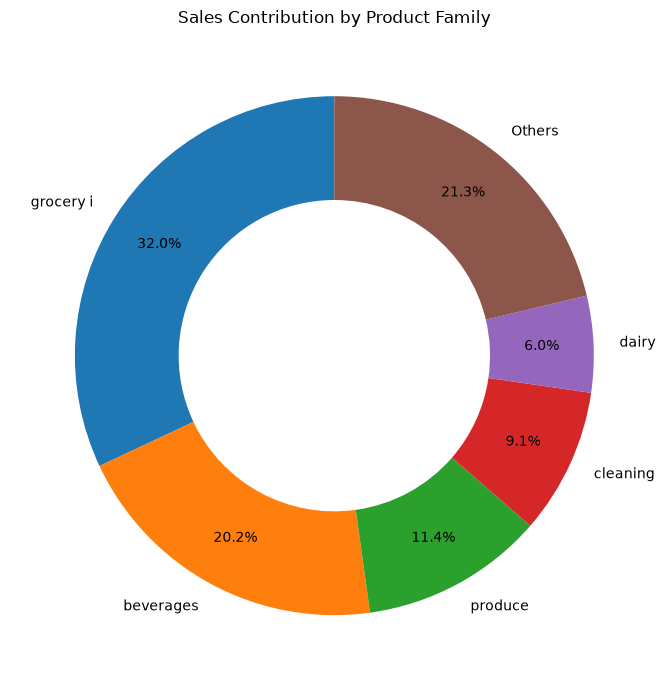

In [174]:
top_5 = family_sales.head(5)

others_sales = (
    family_sales
    .slice(5)
    .select(pl.col("total_unit_sales").sum())
    .item()
)

donut_data = pl.concat([
    top_5.select(["family", "total_unit_sales"]),
    pl.DataFrame({
        "family": ["Others"],
        "total_unit_sales": [others_sales]
    })
])

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.pie(
    donut_data["total_unit_sales"].to_list(),
    labels=donut_data["family"].to_list(),
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8,
    wedgeprops={"width": 0.4}
)

plt.title("Sales Contribution by Product Family")
plt.tight_layout()
plt.show()

In [175]:
item_family_sales = (
    item_sales
    .join(
        items_pl.lazy().select(["item_nbr", "family"]),
        on="item_nbr",
        how="left"
    )
    .collect()
)

In [176]:
item_family_sales

item_nbr,total_unit_sales,family
i64,f64,str
276560,32266.0,"""grocery i"""
302824,100322.0,"""cleaning"""
302997,284661.0,"""grocery i"""
302998,294332.0,"""grocery i"""
314393,892218.0,"""cleaning"""
…,…,…
2026683,93666.0,"""grocery i"""
2026858,93589.0,"""grocery i"""
2034212,30243.0,"""grocery i"""


In [177]:
family_distribution = (
    item_family_sales
    .group_by("family")
    .agg(
        pl.col("total_unit_sales").mean().alias("mean_sales"),
        pl.col("total_unit_sales").median().alias("median_sales"),
        pl.len().alias("number_of_sold_products")
    )
    .with_columns(
        (
            pl.col("mean_sales") / pl.col("median_sales")
        ).alias("mean_median_ratio")
    )
    .sort("mean_median_ratio", descending=True)
)

family_distribution

family,mean_sales,median_sales,number_of_sold_products,mean_median_ratio
str,f64,f64,u32,f64
"""liquor,wine,beer""",122926.746032,21548.0,63,5.704787
"""grocery ii""",150982.076923,43348.0,13,3.483023
"""personal care""",160659.75817,72446.0,153,2.217648
"""beverages""",359175.903974,177472.5,604,2.02384
"""beauty""",17783.736842,9213.0,19,1.930287
…,…,…,…,…
"""lingerie""",32585.5,31528.5,20,1.033525
"""baby care""",10051.0,10051.0,1,1.0
"""home appliances""",41559.0,41559.0,1,1.0


In [178]:
import math

top_products = (
    item_family_sales
    .sort(
        ["family", "total_unit_sales"],
        descending=[False, True]
    )
    .with_columns(
        pl.col("item_nbr")
        .count()
        .over("family")
        .alias("number_of_sold_products")
    )
    .with_columns(
        (pl.col("number_of_sold_products") * 0.10)
        .ceil()
        .cast(pl.UInt32)
        .alias("top_10_pct_count")
    )
    .with_columns(
        pl.col("total_unit_sales")
        .rank(method="ordinal", descending=True)
        .over("family")
        .alias("sales_rank")
    )
)

top_10_sales = (
    top_products
    .filter(pl.col("sales_rank") <= pl.col("top_10_pct_count"))
    .group_by("family")
    .agg(
        pl.col("total_unit_sales").sum().alias("top_10_pct_sales")
    )
)

In [179]:
top_products

item_nbr,total_unit_sales,family,number_of_sold_products,top_10_pct_count,sales_rank
i64,f64,str,u32,u32,u32
270522,57988.0,"""automotive""",20,2,1
172995,47568.0,"""automotive""",20,2,2
1147731,47567.0,"""automotive""",20,2,3
461432,42030.0,"""automotive""",20,2,4
121964,40718.0,"""automotive""",20,2,5
…,…,…,…,…,…
1110679,219680.0,"""seafood""",8,1,4
1247036,175974.0,"""seafood""",8,1,5
252698,172599.5356,"""seafood""",8,1,6


In [180]:
top_10_sales

family,top_10_pct_sales
str,f64
"""automotive""",105556.0
"""baby care""",10051.0
"""beauty""",146284.0
"""beverages""",1.04740238e8
"""books""",6435.0
…,…
"""poultry""",1.2530e7
"""prepared foods""",3.5414e6
"""produce""",5.1134e7


In [181]:
top_10_contribution = (
    top_10_sales
    .join(
        family_sales.select(["family", "total_unit_sales"]),
        on="family",
        how="left"
    )
    .with_columns(
        (
            pl.col("top_10_pct_sales")
            / pl.col("total_unit_sales")
            * 100
        ).alias("top_products_contribution_pct")
    )
    .sort("top_products_contribution_pct", descending=True)
)

top_10_contribution

family,top_10_pct_sales,total_unit_sales,top_products_contribution_pct
str,f64,f64,f64
"""baby care""",10051.0,10051.0,100.0
"""books""",6435.0,6435.0,100.0
"""home appliances""",41559.0,41559.0,100.0
"""grocery ii""",1.138656e6,1.962767e6,58.012795
"""liquor,wine,beer""",4.444525e6,7.744385e6,57.39029
…,…,…,…
"""celebration""",205324.0,761133.0,26.9761
"""players and electronics""",146996.0,562579.0,26.128953
"""seafood""",496705.0,2.0154e6,24.645527


In [182]:
top_10_items = (
    item_family_sales
    .sort("total_unit_sales", descending=True)
    .head(10)
)

bottom_10_items = (
    item_family_sales
    .sort("total_unit_sales")
    .head(10)
)

In [183]:
top_10_items

item_nbr,total_unit_sales,family
i64,f64,str
1503844,6.2642e6,"""produce"""
1047679,5.512875e6,"""beverages"""
1473474,4.9903e6,"""produce"""
364606,4.416426e6,"""grocery i"""
819932,4.410943e6,"""beverages"""
1463992,4.408545e6,"""beverages"""
807493,4.321424e6,"""beverages"""
265559,4.112827e6,"""grocery i"""
502331,3.70335e6,"""bread/bakery"""


In [184]:
bottom_10_items

item_nbr,total_unit_sales,family
i64,f64,str
2011451,1.0,"""grocery i"""
2015898,1.0,"""grocery i"""
2123747,3.0,"""grocery i"""
2122818,4.0,"""beverages"""
2122947,5.0,"""liquor,wine,beer"""
2126944,5.0,"""beverages"""
2123209,6.0,"""liquor,wine,beer"""
2123463,8.0,"""grocery i"""
2123790,9.0,"""liquor,wine,beer"""


In [185]:
top_10_items_details = (
    top_10_items
    .join(
        items_pl.select(["item_nbr", "class"]),
        on="item_nbr",
        how="left"
    )
)

bottom_10_items_details = (
    bottom_10_items
    .join(
        items_pl.select(["item_nbr", "class"]),
        on="item_nbr",
        how="left"
    )
)

In [186]:
top_10_items_details

item_nbr,total_unit_sales,family,class
i64,f64,str,i64
1503844,6.2642e6,"""produce""",2022
1047679,5.512875e6,"""beverages""",1120
1473474,4.9903e6,"""produce""",2014
364606,4.416426e6,"""grocery i""",1014
819932,4.410943e6,"""beverages""",1122
1463992,4.408545e6,"""beverages""",1144
807493,4.321424e6,"""beverages""",1124
265559,4.112827e6,"""grocery i""",1072
502331,3.70335e6,"""bread/bakery""",2702


In [187]:
bottom_10_items_details

item_nbr,total_unit_sales,family,class
i64,f64,str,i64
2011451,1.0,"""grocery i""",1063
2015898,1.0,"""grocery i""",1073
2123747,3.0,"""grocery i""",1022
2122818,4.0,"""beverages""",1154
2122947,5.0,"""liquor,wine,beer""",1370
2126944,5.0,"""beverages""",1142
2123209,6.0,"""liquor,wine,beer""",1306
2123463,8.0,"""grocery i""",1076
2123790,9.0,"""liquor,wine,beer""",1318


In [188]:
bottom_item_ids = bottom_10_items["item_nbr"].to_list()

bottom_item_coverage = (
    train_df
    .filter(pl.col("item_nbr").is_in(bottom_item_ids))
    .group_by("item_nbr")
    .agg(
        pl.col("store_nbr").n_unique().alias("number_of_stores"),
        pl.col("date").min().alias("first_sale_date"),
        pl.col("date").max().alias("last_sale_date"),
        pl.col("date").n_unique().alias("number_of_sale_dates")
    )
    .sort("item_nbr")
    .collect()
)

bottom_item_coverage

item_nbr,number_of_stores,first_sale_date,last_sale_date,number_of_sale_dates
i64,u32,date,date,u32
2011451,1,2017-08-14,2017-08-14,1
2015898,1,2017-08-04,2017-08-04,1
2116238,5,2017-08-06,2017-08-15,4
2122818,1,2017-08-12,2017-08-14,2
2122947,4,2017-08-05,2017-08-11,3
2123209,3,2017-08-07,2017-08-15,5
2123463,2,2017-08-11,2017-08-15,4
2123747,2,2017-08-11,2017-08-15,3
2123790,7,2017-08-11,2017-08-14,4


In [189]:
top_item_ids = top_10_items["item_nbr"].to_list()

top_items_by_store = (
    train_df
    .filter(pl.col("item_nbr").is_in(top_item_ids))
    .group_by(["item_nbr", "store_nbr"])
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort(
        ["item_nbr", "total_unit_sales"],
        descending=[False, True]
    )
    .collect()
)

top_items_by_store

item_nbr,store_nbr,total_unit_sales
i64,i64,f64
265559,46,222125.0
265559,45,221073.0
265559,48,217624.0
265559,47,194931.0
265559,9,161954.0
…,…,…
1503844,34,8.8395
1503844,15,6.368
1503844,22,5.938


In [190]:
stores_df.columns

Index(['store_nbr', 'city', 'state', 'type', 'cluster'], dtype='str')

In [191]:
top_items_store_details = (
    top_items_by_store
    .join(
        stores_pl.select([
            "store_nbr",
            "city",
            "state",
            "type",
            "cluster"
        ]),
        on="store_nbr",
        how="left"
    )
    .sort(
        ["item_nbr", "total_unit_sales"],
        descending=[False, True]
    )
)

In [192]:
top_items_store_details

item_nbr,store_nbr,total_unit_sales,city,state,type,cluster
i64,i64,f64,str,str,str,i64
265559,46,222125.0,"""Quito""","""Pichincha""","""A""",14
265559,45,221073.0,"""Quito""","""Pichincha""","""A""",11
265559,48,217624.0,"""Quito""","""Pichincha""","""A""",14
265559,47,194931.0,"""Quito""","""Pichincha""","""A""",14
265559,9,161954.0,"""Quito""","""Pichincha""","""B""",6
…,…,…,…,…,…,…
1503844,34,8.8395,"""Guayaquil""","""Guayas""","""B""",6
1503844,15,6.368,"""Ibarra""","""Imbabura""","""C""",15
1503844,22,5.938,"""Puyo""","""Pastaza""","""C""",7


In [193]:
product_store_type_analysis = (
    top_items_store_details
    .group_by(["item_nbr", "type"])
    .agg(
        pl.col("total_unit_sales").sum().alias("total_sales"),
        pl.col("total_unit_sales").mean().alias("avg_sales_per_store"),
        pl.col("store_nbr").n_unique().alias("number_of_stores")
    )
    .sort(["item_nbr", "total_sales"], descending=[False, True])
)

product_store_type_analysis

item_nbr,type,total_sales,avg_sales_per_store,number_of_stores
i64,str,f64,f64,u32
265559,"""A""",1.272652e6,141405.777778,9
265559,"""D""",1.181623e6,65645.722222,18
265559,"""B""",721938.0,90242.25,8
265559,"""C""",701164.0,46744.266667,15
265559,"""E""",235450.0,58862.5,4
…,…,…,…,…
1503844,"""D""",3.2896e6,182753.251217,18
1503844,"""A""",2.9671e6,329675.298633,9
1503844,"""B""",7024.7126,878.089075,8


In [194]:
monthly_sales = (
    train_df
    .with_columns(
        pl.col("date").dt.truncate("1mo").alias("month")
    )
    .group_by("month")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales"),
        pl.col("date").n_unique().alias("observed_days")
    )
    .with_columns(
        (pl.col("month").dt.month_end().dt.day())
        .alias("calendar_days")
    )
    .with_columns(
        (pl.col("total_unit_sales") / pl.col("observed_days"))
        .alias("avg_daily_unit_sales")
    )
    .sort("month")
    .collect()
)

In [195]:
monthly_sales

month,total_unit_sales,observed_days,calendar_days,avg_daily_unit_sales
date,f64,u32,i8,f64
2013-01-01,1.0327e7,31,31,333142.314065
2013-02-01,9.6590e6,28,28,344962.849179
2013-03-01,1.1428e7,31,31,368661.194742
2013-04-01,1.0993e7,30,30,366448.757967
2013-05-01,1.1598e7,31,31,374119.419581
…,…,…,…,…
2017-04-01,2.5895e7,30,30,863176.8497
2017-05-01,2.6912e7,31,31,868123.846774
2017-06-01,2.5683e7,30,30,856092.270867


In [196]:
monthly_seasonality = (
    monthly_sales
    .with_columns(
        pl.col("month").dt.month().alias("month_number")
    )
    .group_by("month_number")
    .agg(
        pl.col("avg_daily_unit_sales")
        .mean()
        .alias("avg_daily_unit_sales")
    )
    .sort("month_number")
)

In [197]:
monthly_seasonality

month_number,avg_daily_unit_sales
i8,f64
1,609302.427826
2,570574.337668
3,627280.426773
4,604434.377091
5,608923.18723
…,…
8,624093.935299
9,645613.966011
10,645808.922815


In [198]:
monthly_by_year = (
    monthly_sales
    .with_columns(
        pl.col("month").dt.year().alias("year"),
        pl.col("month").dt.month().alias("month_number")
    )
    .select([
        "year",
        "month_number",
        "avg_daily_unit_sales"
    ])
    .sort(["year", "month_number"])
)

In [199]:
monthly_by_year

year,month_number,avg_daily_unit_sales
i32,i8,f64
2013,1,333142.314065
2013,2,344962.849179
2013,3,368661.194742
2013,4,366448.757967
2013,5,374119.419581
…,…,…
2017,4,863176.8497
2017,5,868123.846774
2017,6,856092.270867


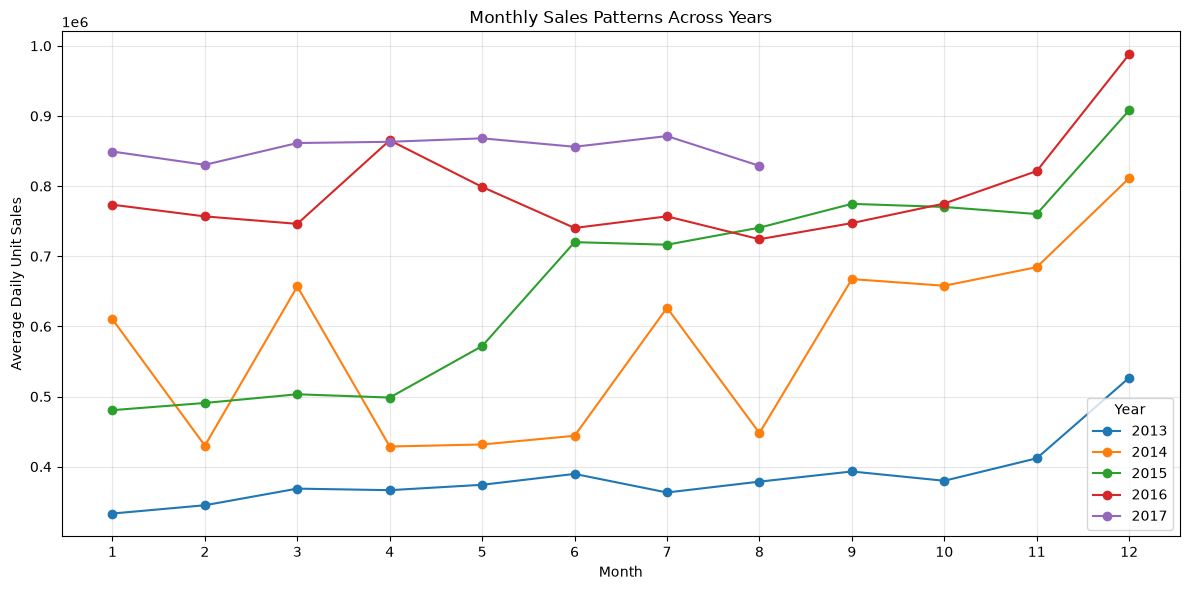

In [200]:
import matplotlib.pyplot as plt

plot_df = monthly_by_year.to_pandas()

plt.figure(figsize=(12, 6))

for year, group in plot_df.groupby("year"):
    plt.plot(
        group["month_number"],
        group["avg_daily_unit_sales"],
        marker="o",
        label=str(year)
    )

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Average Daily Unit Sales")
plt.title("Monthly Sales Patterns Across Years")
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [201]:
yearly_month_summary = (
    monthly_by_year
    .sort(["year", "avg_daily_unit_sales"], descending=[False, True])
    .group_by("year", maintain_order=True)
    .agg([
        pl.col("month_number").first().alias("highest_month"),
        pl.col("avg_daily_unit_sales").first().alias("highest_month_avg"),
        pl.col("month_number").last().alias("lowest_month"),
        pl.col("avg_daily_unit_sales").last().alias("lowest_month_avg"),
    ])
    .sort("year")
)

print(yearly_month_summary)

shape: (5, 5)
┌──────┬───────────────┬───────────────────┬──────────────┬──────────────────┐
│ year ┆ highest_month ┆ highest_month_avg ┆ lowest_month ┆ lowest_month_avg │
│ ---  ┆ ---           ┆ ---               ┆ ---          ┆ ---              │
│ i32  ┆ i8            ┆ f64               ┆ i8           ┆ f64              │
╞══════╪═══════════════╪═══════════════════╪══════════════╪══════════════════╡
│ 2013 ┆ 12            ┆ 526745.404967     ┆ 1            ┆ 333142.314065    │
│ 2014 ┆ 12            ┆ 811348.278857     ┆ 4            ┆ 428708.33522     │
│ 2015 ┆ 12            ┆ 908132.522533     ┆ 1            ┆ 480545.840548    │
│ 2016 ┆ 12            ┆ 987940.1294       ┆ 8            ┆ 724271.429613    │
│ 2017 ┆ 7             ┆ 871337.889226     ┆ 8            ┆ 828888.195933    │
└──────┴───────────────┴───────────────────┴──────────────┴──────────────────┘


In [202]:
december_avg = (
    monthly_by_year
    .filter(pl.col("month_number") == 12)
    .select([
        "year",
        pl.col("avg_daily_unit_sales").alias("december_avg")
    ])
)

december_comparison = (
    monthly_by_year
    .filter(pl.col("year") <= 2016)
    .join(december_avg, on="year", how="left")
    .with_columns(
        (
            pl.col("avg_daily_unit_sales")
            / pl.col("december_avg")
            * 100
        ).alias("pct_of_december")
    )
    .filter(pl.col("month_number") != 12)
    .sort(["year", "month_number"])
)



In [203]:
december_comparison

year,month_number,avg_daily_unit_sales,december_avg,pct_of_december
i32,i8,f64,f64,f64
2013,1,333142.314065,526745.404967,63.245414
2013,2,344962.849179,526745.404967,65.489484
2013,3,368661.194742,526745.404967,69.988498
2013,4,366448.757967,526745.404967,69.568477
2013,5,374119.419581,526745.404967,71.024714
…,…,…,…,…
2016,7,756860.368645,987940.1294,76.609943
2016,8,724271.429613,987940.1294,73.311267
2016,9,747248.236567,987940.1294,75.636996


In [204]:
december_comparison.filter(
    pl.col("month_number").is_in([1, 6, 9, 11])
)

year,month_number,avg_daily_unit_sales,december_avg,pct_of_december
i32,i8,f64,f64,f64
2013,1,333142.314065,526745.404967,63.245414
2013,6,389644.5354,526745.404967,73.972081
2013,9,393097.7411,526745.404967,74.627655
2013,11,411884.3434,526745.404967,78.194198
2014,1,610052.861326,811348.278857,75.190011
…,…,…,…,…
2015,11,760165.0789,908132.522533,83.706404
2016,1,773476.963968,987940.1294,78.291886
2016,6,740307.286,987940.1294,74.934428


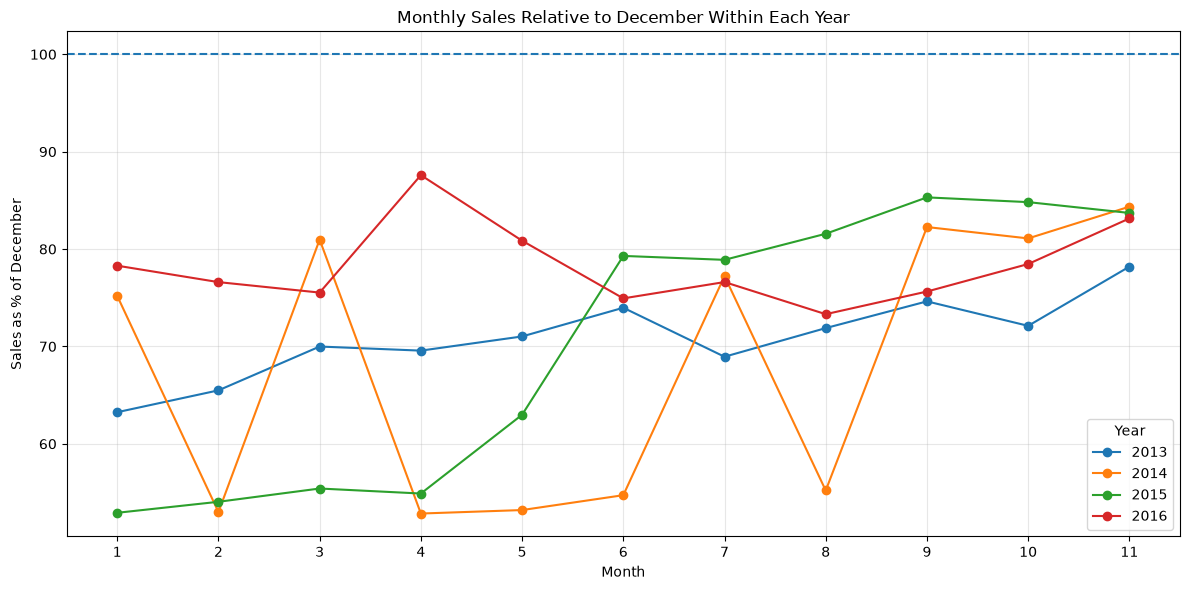

In [205]:
import matplotlib.pyplot as plt

plot_df = december_comparison.to_pandas()

plt.figure(figsize=(12, 6))

for year, group in plot_df.groupby("year"):
    plt.plot(
        group["month_number"],
        group["pct_of_december"],
        marker="o",
        label=str(year)
    )

plt.xticks(range(1, 12))
plt.xlabel("Month")
plt.ylabel("Sales as % of December")
plt.title("Monthly Sales Relative to December Within Each Year")
plt.axhline(100, linestyle="--")
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [206]:
monthly_normalized = (
    monthly_by_year
    .filter(pl.col("year") <= 2016)
    .with_columns(
        pl.col("avg_daily_unit_sales")
        .mean()
        .over("year")
        .alias("year_avg_daily_sales")
    )
    .with_columns(
        (
            pl.col("avg_daily_unit_sales")
            / pl.col("year_avg_daily_sales")
            * 100
        ).alias("sales_index")
    )
)

In [207]:
monthly_normalized

year,month_number,avg_daily_unit_sales,year_avg_daily_sales,sales_index
i32,i8,f64,f64,f64
2013,1,333142.314065,385862.121665,86.337138
2013,2,344962.849179,385862.121665,89.400547
2013,3,368661.194742,385862.121665,95.542209
2013,4,366448.757967,385862.121665,94.968834
2013,5,374119.419581,385862.121665,96.956762
…,…,…,…,…
2016,8,724271.429613,791153.872075,91.546216
2016,9,747248.236567,791153.872075,94.45043
2016,10,775173.800581,791153.872075,97.980156


In [208]:
monthly_normalized.group_by("month_number").agg(
    pl.col("sales_index").mean().alias("avg_sales_index"),
    pl.col("sales_index").std().alias("std_sales_index")
).sort("month_number")

month_number,avg_sales_index,std_sales_index
i8,f64,f64
1,90.729015,14.522464
2,83.521126,10.71395
3,95.063773,15.610524
4,88.580214,16.76422
5,89.877924,11.591359
…,…,…
8,94.906186,14.171824
9,107.400067,11.09645
10,106.845041,10.003612


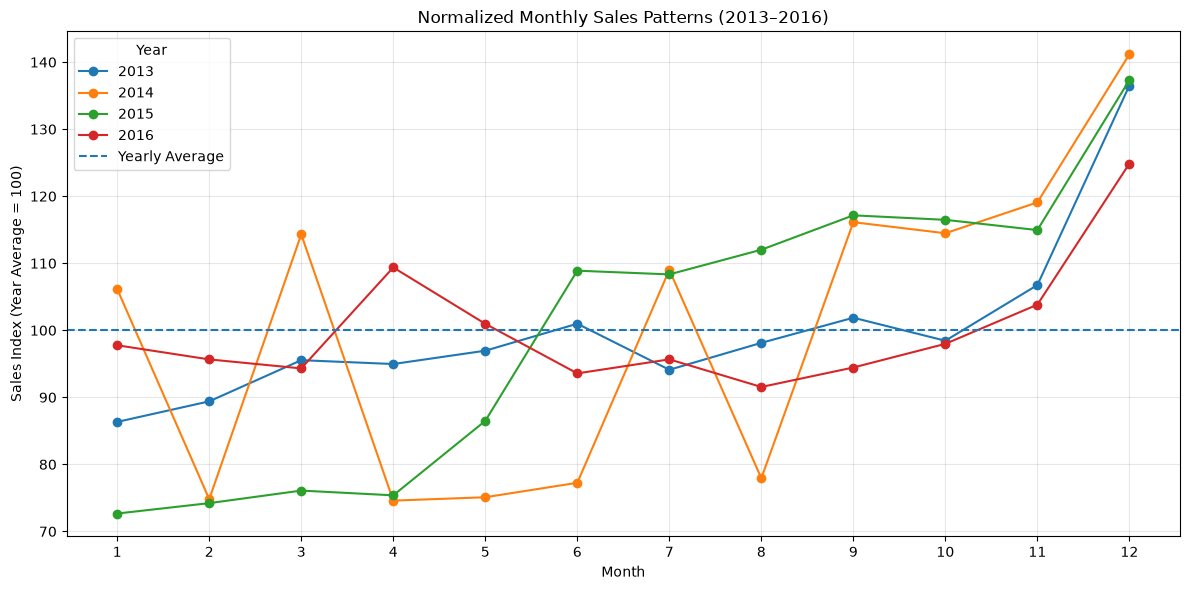

In [209]:
import matplotlib.pyplot as plt

plot_df = monthly_normalized.to_pandas()

plt.figure(figsize=(12, 6))

for year, group in plot_df.groupby("year"):
    plt.plot(
        group["month_number"],
        group["sales_index"],
        marker="o",
        label=str(year)
    )

plt.axhline(100, linestyle="--", label="Yearly Average")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Sales Index (Year Average = 100)")
plt.title("Normalized Monthly Sales Patterns (2013–2016)")
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [210]:
daily_sales = (
    train_df
    .group_by("date")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .with_columns(
        pl.col("date").dt.weekday().alias("weekday"),
        pl.col("date").dt.year().alias("year")
    )
    .sort("date")
    .collect()
)

In [211]:
daily_sales

date,total_unit_sales,weekday,year
date,f64,i8,i32
2013-01-01,2511.619,2,2013
2013-01-02,496092.418,3,2013
2013-01-03,361429.231,4,2013
2013-01-04,354459.677,5,2013
2013-01-05,477350.121,6,2013
…,…,…,…
2017-08-11,826373.722,5,2017
2017-08-12,792630.535,6,2017
2017-08-13,865639.677,7,2017


In [212]:
weekday_sales = (
    daily_sales
    .filter(pl.col("year") <= 2016)
    .group_by(["year", "weekday"])
    .agg(
        pl.col("total_unit_sales").mean().alias("avg_daily_sales"),
        pl.col("total_unit_sales").count().alias("number_of_days")
    )
    .sort(["year", "weekday"])
)

In [213]:
weekday_sales

year,weekday,avg_daily_sales,number_of_days
i32,i8,f64,u32
2013,1,376418.423115,52
2013,2,331870.66417,53
2013,3,342623.420098,51
2013,4,309326.613538,52
2013,5,347734.079788,52
…,…,…,…
2016,3,742916.980192,52
2016,4,626329.037288,52
2016,5,725051.017057,53


In [214]:
weekday_summary = (
    daily_sales
    .filter(pl.col("year") <= 2016)
    .group_by("weekday")
    .agg(
        pl.col("total_unit_sales").mean().alias("avg_daily_sales"),
        pl.col("total_unit_sales").std().alias("std_daily_sales"),
        pl.len().alias("number_of_days")
    )
    .with_columns(
        pl.col("weekday")
        .cast(pl.String)
        .replace({
            "1": "Monday",
            "2": "Tuesday",
            "3": "Wednesday",
            "4": "Thursday",
            "5": "Friday",
            "6": "Saturday",
            "7": "Sunday"
        })
        .alias("day_name")
    )
    .sort("weekday")
)

In [215]:
weekday_summary

weekday,avg_daily_sales,std_daily_sales,number_of_days,day_name
i8,f64,f64,u32,str
1,583905.985933,190409.563933,208,"""Monday"""
2,538138.975337,193314.325833,209,"""Tuesday"""
3,559825.0016,200252.058278,208,"""Wednesday"""
4,479572.94861,165484.847728,208,"""Thursday"""
5,545123.95437,181982.867564,208,"""Friday"""
6,731557.138895,205681.609781,209,"""Saturday"""
7,787409.846918,241878.673936,207,"""Sunday"""


In [216]:
print(weekday_sales)

shape: (28, 4)
┌──────┬─────────┬─────────────────┬────────────────┐
│ year ┆ weekday ┆ avg_daily_sales ┆ number_of_days │
│ ---  ┆ ---     ┆ ---             ┆ ---            │
│ i32  ┆ i8      ┆ f64             ┆ u32            │
╞══════╪═════════╪═════════════════╪════════════════╡
│ 2013 ┆ 1       ┆ 376418.423115   ┆ 52             │
│ 2013 ┆ 2       ┆ 331870.66417    ┆ 53             │
│ 2013 ┆ 3       ┆ 342623.420098   ┆ 51             │
│ 2013 ┆ 4       ┆ 309326.613538   ┆ 52             │
│ 2013 ┆ 5       ┆ 347734.079788   ┆ 52             │
│ …    ┆ …       ┆ …               ┆ …              │
│ 2016 ┆ 3       ┆ 742916.980192   ┆ 52             │
│ 2016 ┆ 4       ┆ 626329.037288   ┆ 52             │
│ 2016 ┆ 5       ┆ 725051.017057   ┆ 53             │
│ 2016 ┆ 6       ┆ 940646.898566   ┆ 53             │
│ 2016 ┆ 7       ┆ 1.0281e6        ┆ 51             │
└──────┴─────────┴─────────────────┴────────────────┘


In [217]:
weekday_normalized = (
    weekday_sales
    .with_columns(
        pl.col("avg_daily_sales")
        .mean()
        .over("year")
        .alias("year_avg_sales")
    )
    .with_columns(
        (
            pl.col("avg_daily_sales")
            / pl.col("year_avg_sales")
            * 100
        ).alias("sales_index")
    )
    .with_columns(
        pl.col("weekday")
        .cast(pl.String)
        .replace({
            "1": "Monday",
            "2": "Tuesday",
            "3": "Wednesday",
            "4": "Thursday",
            "5": "Friday",
            "6": "Saturday",
            "7": "Sunday"
        })
        .alias("day_name")
    )
        .sort(["year", "weekday"])
    .select([
        "year",
        "day_name",
        "avg_daily_sales",
        "sales_index"
    ])
)

print(weekday_normalized)

shape: (28, 4)
┌──────┬───────────┬─────────────────┬─────────────┐
│ year ┆ day_name  ┆ avg_daily_sales ┆ sales_index │
│ ---  ┆ ---       ┆ ---             ┆ ---         │
│ i32  ┆ str       ┆ f64             ┆ f64         │
╞══════╪═══════════╪═════════════════╪═════════════╡
│ 2013 ┆ Monday    ┆ 376418.423115   ┆ 97.56998    │
│ 2013 ┆ Tuesday   ┆ 331870.66417    ┆ 86.022926   │
│ 2013 ┆ Wednesday ┆ 342623.420098   ┆ 88.810107   │
│ 2013 ┆ Thursday  ┆ 309326.613538   ┆ 80.179369   │
│ 2013 ┆ Friday    ┆ 347734.079788   ┆ 90.134821   │
│ …    ┆ …         ┆ …               ┆ …           │
│ 2016 ┆ Wednesday ┆ 742916.980192   ┆ 93.897828   │
│ 2016 ┆ Thursday  ┆ 626329.037288   ┆ 79.162192   │
│ 2016 ┆ Friday    ┆ 725051.017057   ┆ 91.639736   │
│ 2016 ┆ Saturday  ┆ 940646.898566   ┆ 118.88906   │
│ 2016 ┆ Sunday    ┆ 1.0281e6        ┆ 129.942282  │
└──────┴───────────┴─────────────────┴─────────────┘


In [218]:
weekday_pattern_summary = (
    weekday_normalized
    .group_by("day_name")
    .agg(
        pl.col("sales_index").mean().alias("avg_sales_index"),
        pl.col("sales_index").std().alias("std_sales_index")
    )
    .sort("avg_sales_index", descending=True)
)

print(weekday_pattern_summary)

shape: (7, 3)
┌───────────┬─────────────────┬─────────────────┐
│ day_name  ┆ avg_sales_index ┆ std_sales_index │
│ ---       ┆ ---             ┆ ---             │
│ str       ┆ f64             ┆ f64             │
╞═══════════╪═════════════════╪═════════════════╡
│ Sunday    ┆ 130.827017      ┆ 0.812022        │
│ Saturday  ┆ 121.623917      ┆ 2.768207        │
│ Monday    ┆ 96.868045       ┆ 0.889446        │
│ Wednesday ┆ 92.130093       ┆ 2.364119        │
│ Friday    ┆ 90.077401       ┆ 1.368908        │
│ Tuesday   ┆ 88.98143        ┆ 1.976852        │
│ Thursday  ┆ 79.492096       ┆ 0.46517         │
└───────────┴─────────────────┴─────────────────┘


In [219]:
monthly_store_count = (
    train_df
    .with_columns(
        pl.col("date").dt.truncate("1mo").alias("month")
    )
    .group_by("month")
    .agg(
        pl.col("store_nbr").n_unique().alias("number_of_stores")
    )
    .sort("month")
    .collect()
)

print(monthly_store_count)

shape: (56, 2)
┌────────────┬──────────────────┐
│ month      ┆ number_of_stores │
│ ---        ┆ ---              │
│ date       ┆ u32              │
╞════════════╪══════════════════╡
│ 2013-01-01 ┆ 46               │
│ 2013-02-01 ┆ 46               │
│ 2013-03-01 ┆ 46               │
│ 2013-04-01 ┆ 46               │
│ 2013-05-01 ┆ 47               │
│ …          ┆ …                │
│ 2017-04-01 ┆ 54               │
│ 2017-05-01 ┆ 54               │
│ 2017-06-01 ┆ 54               │
│ 2017-07-01 ┆ 54               │
│ 2017-08-01 ┆ 54               │
└────────────┴──────────────────┘


In [220]:
monthly_store_sales = (
    monthly_sales
    .join(
        monthly_store_count,
        on="month",
        how="inner"
    )
    .with_columns(
        (
            pl.col("avg_daily_unit_sales")
            / pl.col("number_of_stores")
        ).alias("avg_daily_sales_per_store")
    )
    .sort("month")
)

print(monthly_store_sales)

shape: (56, 7)
┌────────────┬──────────────┬──────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ month      ┆ total_unit_s ┆ observed_day ┆ calendar_da ┆ avg_daily_u ┆ number_of_s ┆ avg_daily_s │
│ ---        ┆ ales         ┆ s            ┆ ys          ┆ nit_sales   ┆ tores       ┆ ales_per_st │
│ date       ┆ ---          ┆ ---          ┆ ---         ┆ ---         ┆ ---         ┆ ore         │
│            ┆ f64          ┆ u32          ┆ i8          ┆ f64         ┆ u32         ┆ ---         │
│            ┆              ┆              ┆             ┆             ┆             ┆ f64         │
╞════════════╪══════════════╪══════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 2013-01-01 ┆ 1.0327e7     ┆ 31           ┆ 31          ┆ 333142.3140 ┆ 46          ┆ 7242.224219 │
│            ┆              ┆              ┆             ┆ 65          ┆             ┆             │
│ 2013-02-01 ┆ 9.6590e6     ┆ 28           ┆ 28          ┆ 344962.8491 ┆ 46 

In [221]:
from datetime import date

In [222]:
comparison_months = (
    monthly_store_sales
    .filter(
        (
            (pl.col("month") == date(2013, 1, 1))
            | (pl.col("month") == date(2017, 7, 1))
        )
    )
    .select([
        "month",
        "avg_daily_unit_sales",
        "number_of_stores",
        "avg_daily_sales_per_store"
    ])
    .sort("month")
)

print(comparison_months)

shape: (2, 4)
┌────────────┬──────────────────────┬──────────────────┬───────────────────────────┐
│ month      ┆ avg_daily_unit_sales ┆ number_of_stores ┆ avg_daily_sales_per_store │
│ ---        ┆ ---                  ┆ ---              ┆ ---                       │
│ date       ┆ f64                  ┆ u32              ┆ f64                       │
╞════════════╪══════════════════════╪══════════════════╪═══════════════════════════╡
│ 2013-01-01 ┆ 333142.314065        ┆ 46               ┆ 7242.224219               │
│ 2017-07-01 ┆ 871337.889226        ┆ 54               ┆ 16135.886838              │
└────────────┴──────────────────────┴──────────────────┴───────────────────────────┘


In [223]:
store_monthly_sales = (
    train_df
    .with_columns(
        pl.col("date").dt.truncate("1mo").alias("month")
    )
    .filter(
        pl.col("month").is_in([
            date(2013, 1, 1),
            date(2017, 7, 1)
        ])
    )
    .group_by(["month", "store_nbr"])
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort(["month", "store_nbr"])
    .collect()
)

print(store_monthly_sales)

shape: (100, 3)
┌────────────┬───────────┬──────────────────┐
│ month      ┆ store_nbr ┆ total_unit_sales │
│ ---        ┆ ---       ┆ ---              │
│ date       ┆ i64       ┆ f64              │
╞════════════╪═══════════╪══════════════════╡
│ 2013-01-01 ┆ 1         ┆ 156864.199       │
│ 2013-01-01 ┆ 2         ┆ 218534.833       │
│ 2013-01-01 ┆ 3         ┆ 496574.281       │
│ 2013-01-01 ┆ 4         ┆ 209295.86        │
│ 2013-01-01 ┆ 5         ┆ 206884.828       │
│ …          ┆ …         ┆ …                │
│ 2017-07-01 ┆ 50        ┆ 697939.893       │
│ 2017-07-01 ┆ 51        ┆ 758039.999       │
│ 2017-07-01 ┆ 52        ┆ 719688.962       │
│ 2017-07-01 ┆ 53        ┆ 378203.027       │
│ 2017-07-01 ┆ 54        ┆ 317741.915       │
└────────────┴───────────┴──────────────────┘


In [224]:
common_stores = (
    store_monthly_sales
    .group_by("store_nbr")
    .agg(
        pl.col("month").n_unique().alias("number_of_months")
    )
    .filter(pl.col("number_of_months") == 2)
    .select("store_nbr")
)

common_store_comparison = (
    store_monthly_sales
    .join(common_stores, on="store_nbr", how="inner")
    .group_by("month")
    .agg(
        pl.col("total_unit_sales").sum().alias("total_unit_sales"),
        pl.col("store_nbr").n_unique().alias("number_of_stores")
    )
    .sort("month")
)

print(common_store_comparison)

shape: (2, 3)
┌────────────┬──────────────────┬──────────────────┐
│ month      ┆ total_unit_sales ┆ number_of_stores │
│ ---        ┆ ---              ┆ ---              │
│ date       ┆ f64              ┆ u32              │
╞════════════╪══════════════════╪══════════════════╡
│ 2013-01-01 ┆ 1.0327e7         ┆ 46               │
│ 2017-07-01 ┆ 2.3568e7         ┆ 46               │
└────────────┴──────────────────┴──────────────────┘


In [225]:
common_stores = (
    store_monthly_sales
    .group_by("store_nbr")
    .agg(
        pl.col("month").n_unique().alias("number_of_months")
    )
    .filter(pl.col("number_of_months") == 2)
    .select("store_nbr")
)

common_store_count = common_stores.height

print("Number of common stores:", common_store_count)
print(common_stores.sort("store_nbr"))

Number of common stores: 46
shape: (46, 1)
┌───────────┐
│ store_nbr │
│ ---       │
│ i64       │
╞═══════════╡
│ 1         │
│ 2         │
│ 3         │
│ 4         │
│ 5         │
│ …         │
│ 48        │
│ 49        │
│ 50        │
│ 51        │
│ 54        │
└───────────┘


In [226]:
common_store_sales = (
    store_monthly_sales
    .join(common_stores, on="store_nbr", how="inner")
    .group_by("month")
    .agg(
        pl.col("total_unit_sales").sum().alias("total_unit_sales"),
        pl.col("store_nbr").n_unique().alias("number_of_stores")
    )
    .sort("month")
    .with_columns(
        (
            pl.col("total_unit_sales")
            / pl.col("number_of_stores")
        ).alias("avg_monthly_sales_per_store")
    )
)

print(common_store_sales)

shape: (2, 4)
┌────────────┬──────────────────┬──────────────────┬─────────────────────────────┐
│ month      ┆ total_unit_sales ┆ number_of_stores ┆ avg_monthly_sales_per_store │
│ ---        ┆ ---              ┆ ---              ┆ ---                         │
│ date       ┆ f64              ┆ u32              ┆ f64                         │
╞════════════╪══════════════════╪══════════════════╪═════════════════════════════╡
│ 2013-01-01 ┆ 1.0327e7         ┆ 46               ┆ 224508.950783               │
│ 2017-07-01 ┆ 2.3568e7         ┆ 46               ┆ 512348.876261               │
└────────────┴──────────────────┴──────────────────┴─────────────────────────────┘


In [227]:

promotion_quality = (
    train_df
    .group_by("onpromotion")
    .agg(
        pl.len().alias("row_count")
    )
    .with_columns(
        (pl.col("row_count") / pl.col("row_count").sum() * 100)
        .round(2)
        .alias("percentage")
    )
    .sort("row_count", descending=True)
    .collect()
)

print(promotion_quality)
print(train_df.collect_schema())


shape: (3, 3)
┌─────────────┬───────────┬────────────┐
│ onpromotion ┆ row_count ┆ percentage │
│ ---         ┆ ---       ┆ ---        │
│ bool        ┆ u32       ┆ f64        │
╞═════════════╪═══════════╪════════════╡
│ false       ┆ 96028767  ┆ 76.52      │
│ null        ┆ 21657651  ┆ 17.26      │
│ true        ┆ 7810622   ┆ 6.22       │
└─────────────┴───────────┴────────────┘
Schema({'id': Int64, 'date': Date, 'store_nbr': Int64, 'item_nbr': Int64, 'unit_sales': Float64, 'onpromotion': Boolean, 'year': Int32, 'month': Int8, 'month_name': String, 'day': Int8, 'weekday': Int8, 'day_name': String})


In [228]:

promotion_by_year = (
    train_df
    .group_by("year")
    .agg(
        pl.len().alias("total_rows"),
        pl.col("onpromotion").is_null().sum().alias("null_rows"),
        (pl.col("onpromotion") == True).sum().alias("promotion_rows"),
        (pl.col("onpromotion") == False).sum().alias("non_promotion_rows")
    )
    .with_columns(
        (pl.col("null_rows") / pl.col("total_rows") * 100)
        .round(2)
        .alias("null_percentage"),
        (pl.col("promotion_rows") / pl.col("total_rows") * 100)
        .round(2)
        .alias("promotion_percentage")
    )
    .sort("year")
    .collect()
)

print(promotion_by_year)


shape: (5, 7)
┌──────┬────────────┬───────────┬────────────────┬────────────────┬────────────────┬───────────────┐
│ year ┆ total_rows ┆ null_rows ┆ promotion_rows ┆ non_promotion_ ┆ null_percentag ┆ promotion_per │
│ ---  ┆ ---        ┆ ---       ┆ ---            ┆ rows           ┆ e              ┆ centage       │
│ i32  ┆ u32        ┆ u32       ┆ u32            ┆ ---            ┆ ---            ┆ ---           │
│      ┆            ┆           ┆                ┆ u32            ┆ f64            ┆ f64           │
╞══════╪════════════╪═══════════╪════════════════╪════════════════╪════════════════╪═══════════════╡
│ 2013 ┆ 16322662   ┆ 16322662  ┆ 0              ┆ 0              ┆ 100.0          ┆ 0.0           │
│ 2014 ┆ 22271602   ┆ 5334989   ┆ 459114         ┆ 16477499       ┆ 23.95          ┆ 2.06          │
│ 2015 ┆ 27864644   ┆ 0         ┆ 1087275        ┆ 26777369       ┆ 0.0            ┆ 3.9           │
│ 2016 ┆ 35229871   ┆ 0         ┆ 3514584        ┆ 31715287       ┆ 0.0      

In [229]:

promotion_sales = (
    train_df
    .filter(
        (pl.col("year") >= 2015) &
        pl.col("onpromotion").is_not_null()
    )
    .group_by(["year", "onpromotion"])
    .agg(
        pl.len().alias("row_count"),
        pl.col("unit_sales").mean().alias("avg_unit_sales_per_row"),
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .sort(["year", "onpromotion"])
    .collect()
)

print(promotion_sales)


shape: (6, 5)
┌──────┬─────────────┬───────────┬────────────────────────┬──────────────────┐
│ year ┆ onpromotion ┆ row_count ┆ avg_unit_sales_per_row ┆ total_unit_sales │
│ ---  ┆ ---         ┆ ---       ┆ ---                    ┆ ---              │
│ i32  ┆ bool        ┆ u32       ┆ f64                    ┆ f64              │
╞══════╪═════════════╪═══════════╪════════════════════════╪══════════════════╡
│ 2015 ┆ false       ┆ 26777369  ┆ 8.398661               ┆ 2.2489e8         │
│ 2015 ┆ true        ┆ 1087275   ┆ 14.691576              ┆ 1.5974e7         │
│ 2016 ┆ false       ┆ 31715287  ┆ 7.723647               ┆ 2.4496e8         │
│ 2016 ┆ true        ┆ 3514584   ┆ 12.426989              ┆ 4.3676e7         │
│ 2017 ┆ false       ┆ 21058612  ┆ 7.431413               ┆ 1.5650e8         │
│ 2017 ┆ true        ┆ 2749649   ┆ 13.718735              ┆ 3.7722e7         │
└──────┴─────────────┴───────────┴────────────────────────┴──────────────────┘


In [230]:
product_promotion_comparison = (
    train_df
    .filter(
        (pl.col("year") >= 2015) &
        pl.col("onpromotion").is_not_null()
    )
    .group_by("item_nbr")
    .agg(
        pl.col("unit_sales")
        .filter(pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_promo"),

        pl.col("unit_sales")
        .filter(~pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_no_promo"),

        pl.col("onpromotion")
        .sum()
        .alias("promo_rows"),

        (~pl.col("onpromotion"))
        .sum()
        .alias("no_promo_rows")
    )
    .filter(
        pl.col("avg_sales_promo").is_not_null() &
        pl.col("avg_sales_no_promo").is_not_null()
    )
    .with_columns(
        (
            (pl.col("avg_sales_promo") /
             pl.col("avg_sales_no_promo") - 1) * 100
        )
        .alias("sales_difference_pct")
    )
    .sort("sales_difference_pct", descending=True)
    .collect()
)

print(product_promotion_comparison.shape)
print(product_promotion_comparison.head())

(3937, 6)
shape: (5, 6)
┌──────────┬─────────────────┬────────────────────┬────────────┬───────────────┬───────────────────┐
│ item_nbr ┆ avg_sales_promo ┆ avg_sales_no_promo ┆ promo_rows ┆ no_promo_rows ┆ sales_difference_ │
│ ---      ┆ ---             ┆ ---                ┆ ---        ┆ ---           ┆ pct               │
│ i64      ┆ f64             ┆ f64                ┆ u32        ┆ u32           ┆ ---               │
│          ┆                 ┆                    ┆            ┆               ┆ f64               │
╞══════════╪═════════════════╪════════════════════╪════════════╪═══════════════╪═══════════════════╡
│ 1993625  ┆ 110.175         ┆ 3.5                ┆ 80         ┆ 254           ┆ 3047.857143       │
│ 2008567  ┆ 33.212766       ┆ 1.166667           ┆ 235        ┆ 6             ┆ 2746.808511       │
│ 2058764  ┆ 152.914815      ┆ 5.837152           ┆ 270        ┆ 1222          ┆ 2519.681813       │
│ 2084557  ┆ 119.161616      ┆ 5.300577           ┆ 198        ┆ 38

In [231]:

reliable_product_comparison = product_promotion_comparison.filter(
    (pl.col("promo_rows") >= 30) &
    (pl.col("no_promo_rows") >= 30)
)

comparison_summary = reliable_product_comparison.select(
    pl.len().alias("number_of_products"),
    (pl.col("sales_difference_pct") > 0)
    .sum()
    .alias("products_with_higher_promo_avg"),
    (pl.col("sales_difference_pct") < 0)
    .sum()
    .alias("products_with_lower_promo_avg"),
    (pl.col("sales_difference_pct") == 0)
    .sum()
    .alias("products_with_equal_avg"),
    pl.col("sales_difference_pct")
    .median()
    .alias("median_difference_pct"),
    pl.col("sales_difference_pct")
    .quantile(0.25)
    .alias("q1_difference_pct"),
    pl.col("sales_difference_pct")
    .quantile(0.75)
    .alias("q3_difference_pct")
)

print(comparison_summary)


shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ number_of_pr ┆ products_wi ┆ products_wi ┆ products_wi ┆ median_diff ┆ q1_differen ┆ q3_differen │
│ oducts       ┆ th_higher_p ┆ th_lower_pr ┆ th_equal_av ┆ erence_pct  ┆ ce_pct      ┆ ce_pct      │
│ ---          ┆ romo_avg    ┆ omo_avg     ┆ g           ┆ ---         ┆ ---         ┆ ---         │
│ u32          ┆ ---         ┆ ---         ┆ ---         ┆ f64         ┆ f64         ┆ f64         │
│              ┆ u32         ┆ u32         ┆ u32         ┆             ┆             ┆             │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 3610         ┆ 2900        ┆ 710         ┆ 0           ┆ 29.195589   ┆ 5.99343     ┆ 66.536521   │
└──────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┴─────────────┘


In [232]:
yearly_product_promotion = (
    train_df
    .filter(pl.col("year").is_in([2015, 2016, 2017]))
    .group_by(["year", "item_nbr", "onpromotion"])
    .agg(
        pl.len().alias("row_count"),
        pl.col("unit_sales").mean().alias("avg_unit_sales")
    )
    .collect()
    .pivot(
        on="onpromotion",
        index=["year", "item_nbr"],
        values=["row_count", "avg_unit_sales"]
    )
)

In [233]:
yearly_product_promotion = yearly_product_promotion.with_columns(
    (
        (
            pl.col("avg_unit_sales_true")
            - pl.col("avg_unit_sales_false")
        )
        / pl.col("avg_unit_sales_false")
        * 100
    ).alias("sales_difference_pct")
)

In [234]:
yearly_promotion_summary = (
    yearly_product_promotion
    .group_by("year")
    .agg(
        pl.len().alias("number_of_products"),
        (pl.col("sales_difference_pct") > 0)
        .sum().alias("products_with_higher_promo_avg"),
        (pl.col("sales_difference_pct") < 0)
        .sum().alias("products_with_lower_promo_avg"),
        pl.col("sales_difference_pct")
        .median().alias("median_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.25).alias("q1_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.75).alias("q3_difference_pct")
    )
    .sort("year")
)

print(yearly_promotion_summary)

shape: (3, 7)
┌──────┬───────────────┬───────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ year ┆ number_of_pro ┆ products_with ┆ products_wit ┆ median_diffe ┆ q1_differenc ┆ q3_differenc │
│ ---  ┆ ducts         ┆ _higher_promo ┆ h_lower_prom ┆ rence_pct    ┆ e_pct        ┆ e_pct        │
│ i32  ┆ ---           ┆ _avg          ┆ o_avg        ┆ ---          ┆ ---          ┆ ---          │
│      ┆ u32           ┆ ---           ┆ ---          ┆ f64          ┆ f64          ┆ f64          │
│      ┆               ┆ u32           ┆ u32          ┆              ┆              ┆              │
╞══════╪═══════════════╪═══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ 2015 ┆ 3445          ┆ 1535          ┆ 1725         ┆ -3.884795    ┆ -46.345447   ┆ 33.670408    │
│ 2016 ┆ 3886          ┆ 2639          ┆ 1103         ┆ 21.633295    ┆ -4.888863    ┆ 53.845914    │
│ 2017 ┆ 4018          ┆ 2532          ┆ 1192         ┆ 23.07759     ┆ -15.71

In [235]:
print("yearly_product_promotion" in globals())

True


In [236]:
print("train_df" in globals())
print("product_promotion_comparison" in globals())
print("yearly_product_promotion" in globals())

True
True
True


In [237]:

store_product_promotion = (
    train_df
    .filter(
        (pl.col("year") >= 2015) &
        pl.col("onpromotion").is_not_null()
    )
    .group_by(["year", "store_nbr", "item_nbr"])
    .agg(
        pl.col("unit_sales")
        .filter(pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_promo"),

        pl.col("unit_sales")
        .filter(~pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_no_promo"),

        pl.col("onpromotion")
        .sum()
        .alias("promo_rows"),

        (~pl.col("onpromotion"))
        .sum()
        .alias("no_promo_rows")
    )
    .filter(
        (pl.col("promo_rows") >= 30) &
        (pl.col("no_promo_rows") >= 30) &
        (pl.col("avg_sales_no_promo") > 0)
    )
    .with_columns(
        (
            (
                pl.col("avg_sales_promo") /
                pl.col("avg_sales_no_promo")
                - 1
            ) * 100
        ).alias("sales_difference_pct")
    )
)

store_product_promotion_summary = (
    store_product_promotion
    .group_by("year")
    .agg(
        pl.len().alias("store_product_pairs"),
        (pl.col("sales_difference_pct") > 0)
        .sum().alias("pairs_with_higher_promo_avg"),
        (pl.col("sales_difference_pct") < 0)
        .sum().alias("pairs_with_lower_promo_avg"),
        pl.col("sales_difference_pct")
        .median().alias("median_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.25).alias("q1_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.75).alias("q3_difference_pct")
    )
    .sort("year")
    .collect()
)

print(store_product_promotion_summary)


shape: (3, 7)
┌──────┬───────────────┬───────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ year ┆ store_product ┆ pairs_with_hi ┆ pairs_with_l ┆ median_diffe ┆ q1_differenc ┆ q3_differenc │
│ ---  ┆ _pairs        ┆ gher_promo_av ┆ ower_promo_a ┆ rence_pct    ┆ e_pct        ┆ e_pct        │
│ i32  ┆ ---           ┆ g             ┆ vg           ┆ ---          ┆ ---          ┆ ---          │
│      ┆ u32           ┆ ---           ┆ ---          ┆ f64          ┆ f64          ┆ f64          │
│      ┆               ┆ u32           ┆ u32          ┆              ┆              ┆              │
╞══════╪═══════════════╪═══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ 2015 ┆ 15242         ┆ 11236         ┆ 4003         ┆ 20.567943    ┆ -0.895072    ┆ 50.440734    │
│ 2016 ┆ 48260         ┆ 40397         ┆ 7856         ┆ 28.621952    ┆ 7.648587     ┆ 60.231405    │
│ 2017 ┆ 38962         ┆ 35149         ┆ 3809         ┆ 42.959729    ┆ 16.420

In [238]:

store_product_weekday_promotion = (
    train_df
    .filter(
        (pl.col("year") >= 2015) &
        pl.col("onpromotion").is_not_null()
    )
    .group_by(["year", "store_nbr", "item_nbr", "weekday"])
    .agg(
        pl.col("unit_sales")
        .filter(pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_promo"),

        pl.col("unit_sales")
        .filter(~pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_no_promo"),

        pl.col("onpromotion")
        .sum()
        .alias("promo_rows"),

        (~pl.col("onpromotion"))
        .sum()
        .alias("no_promo_rows")
    )
    .filter(
        (pl.col("promo_rows") >= 30) &
        (pl.col("no_promo_rows") >= 30) &
        (pl.col("avg_sales_no_promo") > 0)
    )
    .with_columns(
        (
            (
                pl.col("avg_sales_promo") /
                pl.col("avg_sales_no_promo") - 1
            ) * 100
        ).alias("sales_difference_pct")
    )
)

weekday_promotion_summary = (
    store_product_weekday_promotion
    .group_by("year")
    .agg(
        pl.len().alias("comparison_groups"),
        (pl.col("sales_difference_pct") > 0)
        .sum().alias("groups_with_higher_promo_avg"),
        (pl.col("sales_difference_pct") < 0)
        .sum().alias("groups_with_lower_promo_avg"),
        pl.col("sales_difference_pct")
        .median().alias("median_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.25).alias("q1_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.75).alias("q3_difference_pct")
    )
    .sort("year")
    .collect()
)

print(weekday_promotion_summary)


shape: (0, 7)
┌──────┬───────────────┬───────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ year ┆ comparison_gr ┆ groups_with_h ┆ groups_with_ ┆ median_diffe ┆ q1_differenc ┆ q3_differenc │
│ ---  ┆ oups          ┆ igher_promo_a ┆ lower_promo_ ┆ rence_pct    ┆ e_pct        ┆ e_pct        │
│ i32  ┆ ---           ┆ vg            ┆ avg          ┆ ---          ┆ ---          ┆ ---          │
│      ┆ u32           ┆ ---           ┆ ---          ┆ f64          ┆ f64          ┆ f64          │
│      ┆               ┆ u32           ┆ u32          ┆              ┆              ┆              │
╞══════╪═══════════════╪═══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
└──────┴───────────────┴───────────────┴──────────────┴──────────────┴──────────────┴──────────────┘


In [239]:

weekday_group_diagnostics = (
    store_product_weekday_promotion
    .select(
        pl.len().alias("remaining_groups"),
        pl.col("promo_rows").min().alias("min_promo_rows"),
        pl.col("promo_rows").median().alias("median_promo_rows"),
        pl.col("no_promo_rows").min().alias("min_no_promo_rows"),
        pl.col("no_promo_rows").median().alias("median_no_promo_rows")
    )
    .collect()
)

print(weekday_group_diagnostics)



shape: (1, 5)
┌──────────────────┬────────────────┬───────────────────┬───────────────────┬──────────────────────┐
│ remaining_groups ┆ min_promo_rows ┆ median_promo_rows ┆ min_no_promo_rows ┆ median_no_promo_rows │
│ ---              ┆ ---            ┆ ---               ┆ ---               ┆ ---                  │
│ u32              ┆ u32            ┆ f64               ┆ u32               ┆ f64                  │
╞══════════════════╪════════════════╪═══════════════════╪═══════════════════╪══════════════════════╡
│ 0                ┆ null           ┆ null              ┆ null              ┆ null                 │
└──────────────────┴────────────────┴───────────────────┴───────────────────┴──────────────────────┘


In [240]:

weekday_promotion_raw = (
    train_df
    .filter(
        (pl.col("year") >= 2015) &
        pl.col("onpromotion").is_not_null()
    )
    .group_by(["year", "store_nbr", "item_nbr", "weekday"])
    .agg(
        pl.col("unit_sales")
        .filter(pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_promo"),

        pl.col("unit_sales")
        .filter(~pl.col("onpromotion"))
        .mean()
        .alias("avg_sales_no_promo"),

        pl.col("onpromotion")
        .sum()
        .alias("promo_rows"),

        (~pl.col("onpromotion"))
        .sum()
        .alias("no_promo_rows")
    )
    .collect()
)

print("Raw groups:", weekday_promotion_raw.height)

print(
    weekday_promotion_raw.select(
        (pl.col("promo_rows") > 0).sum().alias("groups_with_promo"),
        (pl.col("no_promo_rows") > 0).sum().alias("groups_without_promo"),
        (pl.col("promo_rows") > 0).and_(
            pl.col("no_promo_rows") > 0
        ).sum().alias("groups_with_both")
    )
)


Raw groups: 3193779
shape: (1, 3)
┌───────────────────┬──────────────────────┬──────────────────┐
│ groups_with_promo ┆ groups_without_promo ┆ groups_with_both │
│ ---               ┆ ---                  ┆ ---              │
│ u32               ┆ u32                  ┆ u32              │
╞═══════════════════╪══════════════════════╪══════════════════╡
│ 1251249           ┆ 3116242              ┆ 1173712          │
└───────────────────┴──────────────────────┴──────────────────┘


In [241]:

weekday_groups_both = weekday_promotion_raw.filter(
    (pl.col("promo_rows") > 0) &
    (pl.col("no_promo_rows") > 0)
)

print(
    weekday_groups_both.select(
        pl.len().alias("groups_with_both"),
        (pl.col("promo_rows") >= 5).sum().alias("promo_rows_ge_5"),
        (pl.col("no_promo_rows") >= 5).sum().alias("no_promo_rows_ge_5"),
        (
            (pl.col("promo_rows") >= 5) &
            (pl.col("no_promo_rows") >= 5)
        ).sum().alias("both_ge_5"),
        (
            (pl.col("promo_rows") >= 10) &
            (pl.col("no_promo_rows") >= 10)
        ).sum().alias("both_ge_10"),
        (
            (pl.col("promo_rows") >= 30) &
            (pl.col("no_promo_rows") >= 30)
        ).sum().alias("both_ge_30")
    )
)


shape: (1, 6)
┌──────────────────┬─────────────────┬────────────────────┬───────────┬────────────┬────────────┐
│ groups_with_both ┆ promo_rows_ge_5 ┆ no_promo_rows_ge_5 ┆ both_ge_5 ┆ both_ge_10 ┆ both_ge_30 │
│ ---              ┆ ---             ┆ ---                ┆ ---       ┆ ---        ┆ ---        │
│ u32              ┆ u32             ┆ u32                ┆ u32       ┆ u32        ┆ u32        │
╞══════════════════╪═════════════════╪════════════════════╪═══════════╪════════════╪════════════╡
│ 1173712          ┆ 416066          ┆ 1115118            ┆ 399245    ┆ 96751      ┆ 0          │
└──────────────────┴─────────────────┴────────────────────┴───────────┴────────────┴────────────┘


In [242]:

weekday_promotion_summary = (
    weekday_groups_both
    .filter(
        (pl.col("promo_rows") >= 10) &
        (pl.col("no_promo_rows") >= 10) &
        (pl.col("avg_sales_no_promo") > 0)
    )
    .with_columns(
        (
            (
                pl.col("avg_sales_promo") /
                pl.col("avg_sales_no_promo") - 1
            ) * 100
        ).alias("sales_difference_pct")
    )
    .group_by("year")
    .agg(
        pl.len().alias("comparison_groups"),
        (pl.col("sales_difference_pct") > 0)
        .sum().alias("groups_with_higher_promo_avg"),
        (pl.col("sales_difference_pct") < 0)
        .sum().alias("groups_with_lower_promo_avg"),
        pl.col("sales_difference_pct")
        .median().alias("median_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.25).alias("q1_difference_pct"),
        pl.col("sales_difference_pct")
        .quantile(0.75).alias("q3_difference_pct")
    )
    .sort("year")
   )

print(weekday_promotion_summary)


shape: (3, 7)
┌──────┬───────────────┬───────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ year ┆ comparison_gr ┆ groups_with_h ┆ groups_with_ ┆ median_diffe ┆ q1_differenc ┆ q3_differenc │
│ ---  ┆ oups          ┆ igher_promo_a ┆ lower_promo_ ┆ rence_pct    ┆ e_pct        ┆ e_pct        │
│ i32  ┆ ---           ┆ vg            ┆ avg          ┆ ---          ┆ ---          ┆ ---          │
│      ┆ u32           ┆ ---           ┆ ---          ┆ f64          ┆ f64          ┆ f64          │
│      ┆               ┆ u32           ┆ u32          ┆              ┆              ┆              │
╞══════╪═══════════════╪═══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ 2015 ┆ 10161         ┆ 5978          ┆ 4152         ┆ 6.349206     ┆ -11.816578   ┆ 28.64184     │
│ 2016 ┆ 55998         ┆ 46767         ┆ 9160         ┆ 34.512072    ┆ 9.36228      ┆ 70.629371    │
│ 2017 ┆ 30588         ┆ 28190         ┆ 2346         ┆ 69.281046    ┆ 28.960

In [243]:
holidays_df = pl.read_csv(
    r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\holidays_events.csv\holidays_events.csv",
    try_parse_dates=True
)

print(holidays_df.shape)
print(holidays_df.schema)
print(holidays_df.head(10))

(350, 6)
Schema({'date': Date, 'type': String, 'locale': String, 'locale_name': String, 'description': String, 'transferred': Boolean})
shape: (10, 6)
┌────────────┬─────────┬──────────┬─────────────┬───────────────────────────────┬─────────────┐
│ date       ┆ type    ┆ locale   ┆ locale_name ┆ description                   ┆ transferred │
│ ---        ┆ ---     ┆ ---      ┆ ---         ┆ ---                           ┆ ---         │
│ date       ┆ str     ┆ str      ┆ str         ┆ str                           ┆ bool        │
╞════════════╪═════════╪══════════╪═════════════╪═══════════════════════════════╪═════════════╡
│ 2012-03-02 ┆ Holiday ┆ Local    ┆ Manta       ┆ Fundacion de Manta            ┆ false       │
│ 2012-04-01 ┆ Holiday ┆ Regional ┆ Cotopaxi    ┆ Provincializacion de Cotopaxi ┆ false       │
│ 2012-04-12 ┆ Holiday ┆ Local    ┆ Cuenca      ┆ Fundacion de Cuenca           ┆ false       │
│ 2012-04-14 ┆ Holiday ┆ Local    ┆ Libertad    ┆ Cantonizacion de Libertad     ┆

In [244]:
holiday_quality = holidays_df.select(
    pl.len().alias("total_rows"),
    pl.col("date").n_unique().alias("unique_dates"),
    pl.col("date").null_count().alias("null_dates"),
    pl.struct(["date", "locale", "locale_name", "description"])
    .n_unique()
    .alias("unique_event_records")
)

print(holiday_quality)

print(
    holidays_df.group_by("type")
    .len()
    .sort("len", descending=True)
)

print(
    holidays_df.group_by("locale")
    .len()
    .sort("len", descending=True)
)

shape: (1, 4)
┌────────────┬──────────────┬────────────┬──────────────────────┐
│ total_rows ┆ unique_dates ┆ null_dates ┆ unique_event_records │
│ ---        ┆ ---          ┆ ---        ┆ ---                  │
│ u32        ┆ u32          ┆ u32        ┆ u32                  │
╞════════════╪══════════════╪════════════╪══════════════════════╡
│ 350        ┆ 312          ┆ 0          ┆ 350                  │
└────────────┴──────────────┴────────────┴──────────────────────┘
shape: (6, 2)
┌────────────┬─────┐
│ type       ┆ len │
│ ---        ┆ --- │
│ str        ┆ u32 │
╞════════════╪═════╡
│ Holiday    ┆ 221 │
│ Event      ┆ 56  │
│ Additional ┆ 51  │
│ Transfer   ┆ 12  │
│ Work Day   ┆ 5   │
│ Bridge     ┆ 5   │
└────────────┴─────┘
shape: (3, 2)
┌──────────┬─────┐
│ locale   ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ National ┆ 174 │
│ Local    ┆ 152 │
│ Regional ┆ 24  │
└──────────┴─────┘


In [245]:
print(
    holidays_df
    .group_by(["locale", "locale_name"])
    .len()
    .sort(["locale", "len"], descending=[False, True])
    .head(30)
)

print(
    stores_df[["store_nbr", "city", "state"]]
    .sort_values("store_nbr")
)

shape: (24, 3)
┌──────────┬────────────────────────────────┬─────┐
│ locale   ┆ locale_name                    ┆ len │
│ ---      ┆ ---                            ┆ --- │
│ str      ┆ str                            ┆ u32 │
╞══════════╪════════════════════════════════╪═════╡
│ Local    ┆ Quito                          ┆ 13  │
│ Local    ┆ Riobamba                       ┆ 12  │
│ Local    ┆ Ambato                         ┆ 12  │
│ Local    ┆ Latacunga                      ┆ 12  │
│ Local    ┆ Guaranda                       ┆ 12  │
│ …        ┆ …                              ┆ …   │
│ National ┆ Ecuador                        ┆ 174 │
│ Regional ┆ Cotopaxi                       ┆ 6   │
│ Regional ┆ Santo Domingo de los Tsachilas ┆ 6   │
│ Regional ┆ Imbabura                       ┆ 6   │
│ Regional ┆ Santa Elena                    ┆ 6   │
└──────────┴────────────────────────────────┴─────┘
    store_nbr           city                           state
0           1          Quito            

In [246]:
regional_names = (
    holidays_df
    .filter(pl.col("locale") == "Regional")
    .select("locale_name")
    .unique()
    .sort("locale_name")
)

local_names = (
    holidays_df
    .filter(pl.col("locale") == "Local")
    .select("locale_name")
    .unique()
    .sort("locale_name")
)

print("Regional event locations:")
print(regional_names)

print("\nLocal event locations:")
print(local_names)

print("\nStore cities:")
print(sorted(stores_df["city"].dropna().unique()))

print("\nStore states:")
print(sorted(stores_df["state"].dropna().unique()))

Regional event locations:
shape: (4, 1)
┌────────────────────────────────┐
│ locale_name                    │
│ ---                            │
│ str                            │
╞════════════════════════════════╡
│ Cotopaxi                       │
│ Imbabura                       │
│ Santa Elena                    │
│ Santo Domingo de los Tsachilas │
└────────────────────────────────┘

Local event locations:
shape: (19, 1)
┌───────────────┐
│ locale_name   │
│ ---           │
│ str           │
╞═══════════════╡
│ Ambato        │
│ Cayambe       │
│ Cuenca        │
│ El Carmen     │
│ Esmeraldas    │
│ …             │
│ Quevedo       │
│ Quito         │
│ Riobamba      │
│ Salinas       │
│ Santo Domingo │
└───────────────┘

Store cities:
['Ambato', 'Babahoyo', 'Cayambe', 'Cuenca', 'Daule', 'El Carmen', 'Esmeraldas', 'Guaranda', 'Guayaquil', 'Ibarra', 'Latacunga', 'Libertad', 'Loja', 'Machala', 'Manta', 'Playas', 'Puyo', 'Quevedo', 'Quito', 'Riobamba', 'Salinas', 'Santo Domingo']

Sto

In [247]:
store_cities = set(stores_df["city"].dropna().unique())
store_states = set(stores_df["state"].dropna().unique())

local_event_names = set(
    holidays_df
    .filter(pl.col("locale") == "Local")
    .get_column("locale_name")
    .unique()
    .to_list()
)

regional_event_names = set(
    holidays_df
    .filter(pl.col("locale") == "Regional")
    .get_column("locale_name")
    .unique()
    .to_list()
)

print("Local event locations without matching stores:")
print(sorted(local_event_names - store_cities))

print("\nRegional event locations without matching stores:")
print(sorted(regional_event_names - store_states))

print("\nMatched local event locations:", len(local_event_names & store_cities), "of", len(local_event_names))
print("Matched regional event locations:", len(regional_event_names & store_states), "of", len(regional_event_names))

Local event locations without matching stores:
[]

Regional event locations without matching stores:
[]

Matched local event locations: 19 of 19
Matched regional event locations: 4 of 4


In [248]:
daily_store_sales = (
    train_df
    .group_by(["date", "store_nbr"])
    .agg(
        pl.col("unit_sales").sum().alias("daily_unit_sales")
    )
    .sort(["date", "store_nbr"])
    .collect()
)

print("Shape:", daily_store_sales.shape)
print(daily_store_sales.head())

Shape: (83606, 3)
shape: (5, 3)
┌────────────┬───────────┬──────────────────┐
│ date       ┆ store_nbr ┆ daily_unit_sales │
│ ---        ┆ ---       ┆ ---              │
│ date       ┆ i64       ┆ f64              │
╞════════════╪═══════════╪══════════════════╡
│ 2013-01-01 ┆ 25        ┆ 2511.619         │
│ 2013-01-02 ┆ 1         ┆ 7417.148         │
│ 2013-01-02 ┆ 2         ┆ 10266.719        │
│ 2013-01-02 ┆ 3         ┆ 24060.348        │
│ 2013-01-02 ┆ 4         ┆ 10200.084        │
└────────────┴───────────┴──────────────────┘


In [249]:
stores_pl = pl.from_pandas(
    stores_df[["store_nbr", "city", "state"]]
)

print(stores_pl.schema)
print(stores_pl.head())

Schema({'store_nbr': Int64, 'city': String, 'state': String})
shape: (5, 3)
┌───────────┬───────────────┬────────────────────────────────┐
│ store_nbr ┆ city          ┆ state                          │
│ ---       ┆ ---           ┆ ---                            │
│ i64       ┆ str           ┆ str                            │
╞═══════════╪═══════════════╪════════════════════════════════╡
│ 1         ┆ Quito         ┆ Pichincha                      │
│ 2         ┆ Quito         ┆ Pichincha                      │
│ 3         ┆ Quito         ┆ Pichincha                      │
│ 4         ┆ Quito         ┆ Pichincha                      │
│ 5         ┆ Santo Domingo ┆ Santo Domingo de los Tsachilas │
└───────────┴───────────────┴────────────────────────────────┘


In [250]:
national_store_events = (
    national_events
    .join(stores_pl.select("store_nbr"), how="cross")
    .with_columns(pl.lit("National").alias("locale"))
    .select([
        "date",
        "store_nbr",
        "type",
        "description",
        "transferred",
        "locale"
    ])
)

store_events = pl.concat([
    national_store_events,
    regional_events.select([
        "date", "store_nbr", "type",
        "description", "transferred", "locale"
    ]),
    local_events.select([
        "date", "store_nbr", "type",
        "description", "transferred", "locale"
    ])
]).sort(["date", "store_nbr"])

print("Shape:", store_events.shape)
print(store_events.head(10))

Shape: (507938, 6)
shape: (10, 6)
┌────────────┬───────────┬─────────┬───────────────────────────────┬─────────────┬──────────┐
│ date       ┆ store_nbr ┆ type    ┆ description                   ┆ transferred ┆ locale   │
│ ---        ┆ ---       ┆ ---     ┆ ---                           ┆ ---         ┆ ---      │
│ date       ┆ i64       ┆ str     ┆ str                           ┆ bool        ┆ str      │
╞════════════╪═══════════╪═════════╪═══════════════════════════════╪═════════════╪══════════╡
│ 2012-03-02 ┆ 52        ┆ holiday ┆ fundacion de manta            ┆ false       ┆ local    │
│ 2012-03-02 ┆ 53        ┆ holiday ┆ fundacion de manta            ┆ false       ┆ local    │
│ 2012-04-01 ┆ 12        ┆ holiday ┆ provincializacion de cotopaxi ┆ false       ┆ regional │
│ 2012-04-01 ┆ 13        ┆ holiday ┆ provincializacion de cotopaxi ┆ false       ┆ regional │
│ 2012-04-12 ┆ 37        ┆ holiday ┆ fundacion de cuenca           ┆ false       ┆ local    │
│ 2012-04-12 ┆ 39        ┆

In [251]:
store_events_project = store_events.filter(
    pl.col("date").is_between(
        daily_store_sales["date"].min(),
        daily_store_sales["date"].max(),
        closed="both"
    )
)

event_multiplicity = (
    store_events_project
    .group_by(["date", "store_nbr"])
    .agg(
        pl.len().alias("event_records"),
        pl.col("type").n_unique().alias("distinct_event_types"),
        pl.col("description").n_unique().alias("distinct_descriptions")
    )
)

print("Events within project period:", store_events_project.shape)

print(
    event_multiplicity
    .select([
        pl.len().alias("store_date_combinations"),
        (pl.col("event_records") > 1).sum().alias("combinations_with_multiple_events"),
        pl.col("event_records").max().alias("max_events_per_store_date")
    ])
)

print(
    event_multiplicity
    .filter(pl.col("event_records") > 1)
    .sort("event_records", descending=True)
    .head(10)
)

Events within project period: (440726, 6)
shape: (1, 3)
┌─────────────────────────┬─────────────────────────────────┬───────────────────────────┐
│ store_date_combinations ┆ combinations_with_multiple_eve… ┆ max_events_per_store_date │
│ ---                     ┆ ---                             ┆ ---                       │
│ u32                     ┆ u32                             ┆ u32                       │
╞═════════════════════════╪═════════════════════════════════╪═══════════════════════════╡
│ 8325                    ┆ 7946                            ┆ 108                       │
└─────────────────────────┴─────────────────────────────────┴───────────────────────────┘
shape: (10, 5)
┌────────────┬───────────┬───────────────┬──────────────────────┬───────────────────────┐
│ date       ┆ store_nbr ┆ event_records ┆ distinct_event_types ┆ distinct_descriptions │
│ ---        ┆ ---       ┆ ---           ┆ ---                  ┆ ---                   │
│ date       ┆ i64       ┆ u3

In [263]:
event_flags = (
    store_events_project
    .group_by(["date", "store_nbr"])
    .agg(
        pl.len().alias("event_count"),
        pl.col("type").filter(pl.col("type") == "holiday")
          .len().alias("holiday_count"),
        pl.col("type").filter(pl.col("type") == "event")
          .len().alias("event_type_count"),
        pl.col("type").filter(pl.col("type") == "additional")
          .len().alias("additional_count"),
        pl.col("type").filter(pl.col("type") == "transfer")
          .len().alias("transfer_count"),
        pl.col("type").filter(pl.col("type") == "bridge")
          .len().alias("bridge_count"),
        pl.col("type").filter(pl.col("type") == "work day")
          .len().alias("work_day_count"),
        pl.col("transferred").sum().alias("transferred_count")
    )
    .with_columns(
        (pl.col("holiday_count") > 0).alias("has_holiday"),
        (pl.col("event_type_count") > 0).alias("has_event"),
        (pl.col("additional_count") > 0).alias("has_additional"),
        (pl.col("transfer_count") > 0).alias("has_transfer"),
        (pl.col("bridge_count") > 0).alias("has_bridge"),
        (pl.col("work_day_count") > 0).alias("has_work_day"),
        (pl.col("transferred_count") > 0).alias("has_transferred")
    )
    .sort(["date", "store_nbr"])
)

In [266]:
print(
    event_flags.select([
        pl.col("holiday_count").sum().alias("total_holidays"),
        pl.col("event_count").sum().alias("total_events"),
        pl.col("has_holiday").sum().alias("store_dates_with_holiday"),
        pl.col("has_event").sum().alias("store_dates_with_event")
    ])
)

shape: (1, 4)
┌────────────────┬──────────────┬──────────────────────────┬────────────────────────┐
│ total_holidays ┆ total_events ┆ store_dates_with_holiday ┆ store_dates_with_event │
│ ---            ┆ ---          ┆ ---                      ┆ ---                    │
│ u32            ┆ u32          ┆ u32                      ┆ u32                    │
╞════════════════╪══════════════╪══════════════════════════╪════════════════════════╡
│ 149003         ┆ 440726       ┆ 3040                     ┆ 2970                   │
└────────────────┴──────────────┴──────────────────────────┴────────────────────────┘


In [267]:
print("Shape:", store_events_project.shape)
print("Columns:", store_events_project.columns)

print(
    store_events_project
    .group_by("type")
    .agg(pl.len().alias("rows"))
    .sort("rows", descending=True)
)

Shape: (440726, 6)
Columns: ['date', 'store_nbr', 'type', 'description', 'transferred', 'locale']
shape: (6, 2)
┌────────────┬────────┐
│ type       ┆ rows   │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ event      ┆ 163296 │
│ holiday    ┆ 149003 │
│ additional ┆ 84676  │
│ transfer   ┆ 20423  │
│ work day   ┆ 14580  │
│ bridge     ┆ 8748   │
└────────────┴────────┘


In [268]:
event_columns = [
    "event_count",
    "holiday_count",
    "event_type_count",
    "additional_count",
    "transfer_count",
    "bridge_count",
    "work_day_count",
    "transferred_count",
    "has_holiday",
    "has_event",
    "has_additional",
    "has_transfer",
    "has_bridge",
    "has_work_day",
    "has_transferred"
]

sales_with_events = (
    daily_store_sales
    .join(
        event_flags,
        on=["date", "store_nbr"],
        how="left"
    )
    .with_columns([
    pl.col([
        "event_count",
        "holiday_count",
        "event_type_count",
        "additional_count",
        "transfer_count",
        "bridge_count",
        "work_day_count",
        "transferred_count"
    ]).fill_null(0),

    pl.col([
        "has_holiday",
        "has_event",
        "has_additional",
        "has_transfer",
        "has_bridge",
        "has_work_day",
        "has_transferred"
    ]).fill_null(False)
])
)

print("Original daily sales:", daily_store_sales.shape)
print("Sales with events:", sales_with_events.shape)

print(
    sales_with_events
    .group_by("has_holiday")
    .agg(
        pl.len().alias("store_days"),
        pl.col("daily_unit_sales").mean().alias("avg_daily_unit_sales"),
        pl.col("daily_unit_sales").median().alias("median_daily_unit_sales")
    )
    .sort("has_holiday", descending=True)
)

Original daily sales: (83606, 3)
Sales with events: (83606, 18)
shape: (2, 4)
┌─────────────┬────────────┬──────────────────────┬─────────────────────────┐
│ has_holiday ┆ store_days ┆ avg_daily_unit_sales ┆ median_daily_unit_sales │
│ ---         ┆ ---        ┆ ---                  ┆ ---                     │
│ bool        ┆ u32        ┆ f64                  ┆ f64                     │
╞═════════════╪════════════╪══════════════════════╪═════════════════════════╡
│ true        ┆ 2357       ┆ 13442.132975         ┆ 9848.415                │
│ false       ┆ 81249      ┆ 12823.876741         ┆ 10026.313               │
└─────────────┴────────────┴──────────────────────┴─────────────────────────┘


In [269]:
count_columns = [
    "event_count",
    "holiday_count",
    "event_type_count",
    "additional_count",
    "transfer_count",
    "bridge_count",
    "work_day_count",
    "transferred_count"
]

flag_columns = [
    "has_holiday",
    "has_event",
    "has_additional",
    "has_transfer",
    "has_bridge",
    "has_work_day",
    "has_transferred"
]

sales_with_events = (
    daily_store_sales
    .join(
        event_flags,
        on=["date", "store_nbr"],
        how="left"
    )
    .with_columns(
        pl.col(count_columns).fill_null(0)
    )
    .with_columns(
        pl.col(flag_columns).fill_null(False)
    )
)

print("Original daily sales:", daily_store_sales.shape)
print("Sales with events:", sales_with_events.shape)

print(
    sales_with_events
    .group_by("has_holiday")
    .agg(
        pl.len().alias("store_days"),
        pl.col("daily_unit_sales").mean().alias("avg_daily_unit_sales"),
        pl.col("daily_unit_sales").median().alias("median_daily_unit_sales")
    )
    .sort("has_holiday", descending=True)
)


Original daily sales: (83606, 3)
Sales with events: (83606, 18)
shape: (2, 4)
┌─────────────┬────────────┬──────────────────────┬─────────────────────────┐
│ has_holiday ┆ store_days ┆ avg_daily_unit_sales ┆ median_daily_unit_sales │
│ ---         ┆ ---        ┆ ---                  ┆ ---                     │
│ bool        ┆ u32        ┆ f64                  ┆ f64                     │
╞═════════════╪════════════╪══════════════════════╪═════════════════════════╡
│ true        ┆ 2357       ┆ 13442.132975         ┆ 9848.415                │
│ false       ┆ 81249      ┆ 12823.876741         ┆ 10026.313               │
└─────────────┴────────────┴──────────────────────┴─────────────────────────┘


In [270]:
holiday_weekday_comparison = (
    sales_with_events
    .with_columns(
        pl.col("date").dt.weekday().alias("weekday")
    )
    .group_by(["store_nbr", "weekday", "has_holiday"])
    .agg(
        pl.col("daily_unit_sales").mean().alias("avg_daily_sales"),
        pl.len().alias("days_count")
    )
    .pivot(
        on="has_holiday",
        index=["store_nbr", "weekday"],
        values=["avg_daily_sales", "days_count"]
    )
)

print("Shape:", holiday_weekday_comparison.shape)
print(holiday_weekday_comparison.head())

Shape: (378, 6)
shape: (5, 6)
┌───────────┬─────────┬───────────────────┬───────────────────┬──────────────────┬─────────────────┐
│ store_nbr ┆ weekday ┆ avg_daily_sales_f ┆ avg_daily_sales_t ┆ days_count_false ┆ days_count_true │
│ ---       ┆ ---     ┆ alse              ┆ rue               ┆ ---              ┆ ---             │
│ i64       ┆ i8      ┆ ---               ┆ ---               ┆ u32              ┆ u32             │
│           ┆         ┆ f64               ┆ f64               ┆                  ┆                 │
╞═══════════╪═════════╪═══════════════════╪═══════════════════╪══════════════════╪═════════════════╡
│ 42        ┆ 5       ┆ 11248.325192      ┆ 10442.556667      ┆ 99               ┆ 3               │
│ 30        ┆ 4       ┆ 4221.746435       ┆ 4407.05715        ┆ 232              ┆ 4               │
│ 50        ┆ 3       ┆ 15046.341603      ┆ 17522.986429      ┆ 232              ┆ 7               │
│ 45        ┆ 3       ┆ 28919.856099      ┆ 32073.6234       

In [271]:
print(
    sales_with_events
    .group_by("has_holiday")
    .agg(
        pl.len().alias("days_count"),
        pl.col("daily_unit_sales").mean().alias("avg_daily_sales")
    )
    .sort("has_holiday")
)

shape: (2, 3)
┌─────────────┬────────────┬─────────────────┐
│ has_holiday ┆ days_count ┆ avg_daily_sales │
│ ---         ┆ ---        ┆ ---             │
│ bool        ┆ u32        ┆ f64             │
╞═════════════╪════════════╪═════════════════╡
│ false       ┆ 81249      ┆ 12823.876741    │
│ true        ┆ 2357       ┆ 13442.132975    │
└─────────────┴────────────┴─────────────────┘


In [272]:
print(event_flags.shape)
print(event_flags.columns)

print(
    event_flags
    .group_by("has_holiday")
    .agg(pl.len().alias("rows"))
)

(8325, 17)
['date', 'store_nbr', 'event_count', 'holiday_count', 'event_type_count', 'additional_count', 'transfer_count', 'bridge_count', 'work_day_count', 'transferred_count', 'has_holiday', 'has_event', 'has_additional', 'has_transfer', 'has_bridge', 'has_work_day', 'has_transferred']
shape: (2, 2)
┌─────────────┬──────┐
│ has_holiday ┆ rows │
│ ---         ┆ ---  │
│ bool        ┆ u32  │
╞═════════════╪══════╡
│ true        ┆ 3040 │
│ false       ┆ 5285 │
└─────────────┴──────┘


In [273]:
print(
    event_flags.select([
        pl.col("holiday_count").sum().alias("total_holidays"),
        pl.col("event_count").sum().alias("total_events"),
        pl.col("has_holiday").sum().alias("has_holiday_true"),
        pl.col("has_event").sum().alias("has_event_true")
    ])
)

shape: (1, 4)
┌────────────────┬──────────────┬──────────────────┬────────────────┐
│ total_holidays ┆ total_events ┆ has_holiday_true ┆ has_event_true │
│ ---            ┆ ---          ┆ ---              ┆ ---            │
│ u32            ┆ u32          ┆ u32              ┆ u32            │
╞════════════════╪══════════════╪══════════════════╪════════════════╡
│ 149003         ┆ 440726       ┆ 3040             ┆ 2970           │
└────────────────┴──────────────┴──────────────────┴────────────────┘


In [274]:
holiday_weekday_effect = (
    holiday_weekday_comparison
    .filter(
        (pl.col("days_count_true") >= 5) &
        (pl.col("days_count_false") >= 5) &
        (pl.col("avg_daily_sales_true").is_not_null()) &
        (pl.col("avg_daily_sales_false").is_not_null()) &
        (pl.col("avg_daily_sales_false") > 0)
    )
    .with_columns(
        (
            (pl.col("avg_daily_sales_true") -
             pl.col("avg_daily_sales_false")) /
            pl.col("avg_daily_sales_false") * 100
        ).alias("holiday_sales_difference_pct")
    )
)

print("Eligible store-weekday groups:", holiday_weekday_effect.height)

print(
    holiday_weekday_effect
    .select([
        pl.len().alias("groups"),
        (pl.col("holiday_sales_difference_pct") > 0)
            .sum().alias("groups_with_higher_holiday_sales"),
        (pl.col("holiday_sales_difference_pct") < 0)
            .sum().alias("groups_with_lower_holiday_sales"),
        pl.col("holiday_sales_difference_pct").median()
            .alias("median_difference_pct"),
        pl.col("holiday_sales_difference_pct").quantile(0.25)
            .alias("q1_difference_pct"),
        pl.col("holiday_sales_difference_pct").quantile(0.75)
            .alias("q3_difference_pct")
    ])
)

Eligible store-weekday groups: 271
shape: (1, 6)
┌────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┐
│ groups ┆ groups_with_hig ┆ groups_with_low ┆ median_differen ┆ q1_difference_p ┆ q3_difference_p │
│ ---    ┆ her_holiday_sal ┆ er_holiday_sale ┆ ce_pct          ┆ ct              ┆ ct              │
│ u32    ┆ …               ┆ …               ┆ ---             ┆ ---             ┆ ---             │
│        ┆ ---             ┆ ---             ┆ f64             ┆ f64             ┆ f64             │
│        ┆ u32             ┆ u32             ┆                 ┆                 ┆                 │
╞════════╪═════════════════╪═════════════════╪═════════════════╪═════════════════╪═════════════════╡
│ 271    ┆ 169             ┆ 102             ┆ 3.463708        ┆ -4.140564       ┆ 14.315572       │
└────────┴─────────────────┴─────────────────┴─────────────────┴─────────────────┴─────────────────┘


In [275]:
print(holiday_weekday_comparison.columns)
print(holiday_weekday_comparison.head(10))

['store_nbr', 'weekday', 'avg_daily_sales_false', 'avg_daily_sales_true', 'days_count_false', 'days_count_true']
shape: (10, 6)
┌───────────┬─────────┬───────────────────┬───────────────────┬──────────────────┬─────────────────┐
│ store_nbr ┆ weekday ┆ avg_daily_sales_f ┆ avg_daily_sales_t ┆ days_count_false ┆ days_count_true │
│ ---       ┆ ---     ┆ alse              ┆ rue               ┆ ---              ┆ ---             │
│ i64       ┆ i8      ┆ ---               ┆ ---               ┆ u32              ┆ u32             │
│           ┆         ┆ f64               ┆ f64               ┆                  ┆                 │
╞═══════════╪═════════╪═══════════════════╪═══════════════════╪══════════════════╪═════════════════╡
│ 42        ┆ 5       ┆ 11248.325192      ┆ 10442.556667      ┆ 99               ┆ 3               │
│ 30        ┆ 4       ┆ 4221.746435       ┆ 4407.05715        ┆ 232              ┆ 4               │
│ 50        ┆ 3       ┆ 15046.341603      ┆ 17522.986429      ┆ 

In [276]:
event_type_results = pl.concat([
    sales_with_events.select([
        pl.lit("Holiday").alias("event_type"),
        pl.col("has_holiday").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Event").alias("event_type"),
        pl.col("has_event").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Additional").alias("event_type"),
        pl.col("has_additional").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Transfer").alias("event_type"),
        pl.col("has_transfer").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Bridge").alias("event_type"),
        pl.col("has_bridge").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Work Day").alias("event_type"),
        pl.col("has_work_day").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ]),
    sales_with_events.select([
        pl.lit("Transferred").alias("event_type"),
        pl.col("has_transferred").alias("has_event_flag"),
        pl.col("daily_unit_sales")
    ])
]).group_by(["event_type", "has_event_flag"]).agg(
    pl.len().alias("store_days"),
    pl.col("daily_unit_sales").mean().alias("avg_daily_unit_sales"),
    pl.col("daily_unit_sales").median().alias("median_daily_unit_sales")
).sort(["event_type", "has_event_flag"], descending=[False, True])

print(event_type_results)

shape: (14, 5)
┌─────────────┬────────────────┬────────────┬──────────────────────┬─────────────────────────┐
│ event_type  ┆ has_event_flag ┆ store_days ┆ avg_daily_unit_sales ┆ median_daily_unit_sales │
│ ---         ┆ ---            ┆ ---        ┆ ---                  ┆ ---                     │
│ str         ┆ bool           ┆ u32        ┆ f64                  ┆ f64                     │
╞═════════════╪════════════════╪════════════╪══════════════════════╪═════════════════════════╡
│ Additional  ┆ true           ┆ 1562       ┆ 18416.436347         ┆ 15508.195               │
│ Additional  ┆ false          ┆ 82044      ┆ 12735.164            ┆ 9939.6755               │
│ Bridge      ┆ true           ┆ 148        ┆ 16137.365304         ┆ 12463.2485              │
│ Bridge      ┆ false          ┆ 83458      ┆ 12835.461414         ┆ 10016.4755              │
│ Event       ┆ true           ┆ 2803       ┆ 14854.681624         ┆ 11485.316               │
│ …           ┆ …              ┆ … 

In [277]:
def compare_event_within_store_weekday(flag_column, event_name):
    comparison = (
        sales_with_events
        .with_columns(
            pl.col("date").dt.weekday().alias("weekday")
        )
        .group_by(["store_nbr", "weekday", flag_column])
        .agg(
            pl.col("daily_unit_sales").mean().alias("avg_sales"),
            pl.len().alias("days_count")
        )
        .pivot(
            on=flag_column,
            index=["store_nbr", "weekday"],
            values=["avg_sales", "days_count"]
        )
    )

    effect = (
        comparison
        .filter(
            (pl.col("days_count_true") >= 5) &
            (pl.col("days_count_false") >= 5) &
            (pl.col("avg_sales_false") > 0)
        )
        .with_columns(
            (
                (pl.col("avg_sales_true") - pl.col("avg_sales_false"))
                / pl.col("avg_sales_false") * 100
            ).alias("difference_pct")
        )
    )

    summary = effect.select(
        pl.len().alias("eligible_groups"),
        (pl.col("difference_pct") > 0).sum().alias("higher_groups"),
        (pl.col("difference_pct") < 0).sum().alias("lower_groups"),
        pl.col("difference_pct").median().alias("median_difference_pct"),
        pl.col("difference_pct").quantile(0.25).alias("q1_pct"),
        pl.col("difference_pct").quantile(0.75).alias("q3_pct")
    ).with_columns(
        pl.lit(event_name).alias("event_type")
    )

    return summary.select([
        "event_type",
        "eligible_groups",
        "higher_groups",
        "lower_groups",
        "median_difference_pct",
        "q1_pct",
        "q3_pct"
    ])


additional_comparison = compare_event_within_store_weekday(
    "has_additional", "Additional"
)

event_comparison = compare_event_within_store_weekday(
    "has_event", "Event"
)

print(pl.concat([
    additional_comparison,
    event_comparison
]))

shape: (2, 7)
┌────────────┬───────────────┬───────────────┬──────────────┬──────────────┬───────────┬───────────┐
│ event_type ┆ eligible_grou ┆ higher_groups ┆ lower_groups ┆ median_diffe ┆ q1_pct    ┆ q3_pct    │
│ ---        ┆ ps            ┆ ---           ┆ ---          ┆ rence_pct    ┆ ---       ┆ ---       │
│ str        ┆ ---           ┆ u32           ┆ u32          ┆ ---          ┆ f64       ┆ f64       │
│            ┆ u32           ┆               ┆              ┆ f64          ┆           ┆           │
╞════════════╪═══════════════╪═══════════════╪══════════════╪══════════════╪═══════════╪═══════════╡
│ Additional ┆ 114           ┆ 114           ┆ 0            ┆ 33.660139    ┆ 14.381367 ┆ 55.721159 │
│ Event      ┆ 353           ┆ 292           ┆ 61           ┆ 14.210828    ┆ 4.6617    ┆ 24.077653 │
└────────────┴───────────────┴───────────────┴──────────────┴──────────────┴───────────┴───────────┘


In [278]:
oil_df

,date,dcoilwtico,Day Name,Day Number,Year,Month
0,2013-01-01,93.14,Tuesday,1,2013,January
1,2013-01-02,93.14,Wednesday,2,2013,January
2,2013-01-03,92.97,Thursday,3,2013,January
3,2013-01-04,93.12,Friday,4,2013,January
4,2013-01-07,93.20,Monday,7,2013,January
...,...,...,...,...,...,...
1213,2017-08-25,47.65,Friday,25,2017,August
1214,2017-08-28,46.40,Monday,28,2017,August
1215,2017-08-29,46.46,Tuesday,29,2017,August
1216,2017-08-30,45.96,Wednesday,30,2017,August


In [279]:
oil_df = pl.read_csv(
    r"D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Datasets\oil.csv\oil.csv",
    try_parse_dates=True
)

monthly_oil = (
    oil_df
    .group_by_dynamic(
        "date",
        every="1mo",
        closed="left",
        label="left"
    )
    .agg(
        pl.col("dcoilwtico").mean().alias("avg_oil_price"),
        pl.col("dcoilwtico").count().alias("observations")
    )
    .sort("date")
)

print(monthly_oil.shape)
print(monthly_oil.head())
print(monthly_oil.tail())

(56, 3)
shape: (5, 3)
┌────────────┬───────────────┬──────────────┐
│ date       ┆ avg_oil_price ┆ observations │
│ ---        ┆ ---           ┆ ---          │
│ date       ┆ f64           ┆ u32          │
╞════════════╪═══════════════╪══════════════╡
│ 2013-01-01 ┆ 94.756667     ┆ 21           │
│ 2013-02-01 ┆ 95.308947     ┆ 19           │
│ 2013-03-01 ┆ 92.9385       ┆ 20           │
│ 2013-04-01 ┆ 92.021364     ┆ 22           │
│ 2013-05-01 ┆ 94.509545     ┆ 22           │
└────────────┴───────────────┴──────────────┘
shape: (5, 3)
┌────────────┬───────────────┬──────────────┐
│ date       ┆ avg_oil_price ┆ observations │
│ ---        ┆ ---           ┆ ---          │
│ date       ┆ f64           ┆ u32          │
╞════════════╪═══════════════╪══════════════╡
│ 2017-04-01 ┆ 51.060526     ┆ 19           │
│ 2017-05-01 ┆ 48.476364     ┆ 22           │
│ 2017-06-01 ┆ 45.177727     ┆ 22           │
│ 2017-07-01 ┆ 46.630526     ┆ 19           │
│ 2017-08-01 ┆ 48.036957     ┆ 23           

In [280]:
print("Monthly sales:")
print(monthly_sales.select(
    pl.len().alias("rows"),
    pl.col("month").n_unique().alias("unique_months"),
    pl.col("month").min().alias("first_month"),
    pl.col("month").max().alias("last_month")
))

print("Monthly oil:")
print(monthly_oil.select(
    pl.len().alias("rows"),
    pl.col("date").n_unique().alias("unique_months"),
    pl.col("date").min().alias("first_month"),
    pl.col("date").max().alias("last_month")
))

Monthly sales:
shape: (1, 4)
┌──────┬───────────────┬─────────────┬────────────┐
│ rows ┆ unique_months ┆ first_month ┆ last_month │
│ ---  ┆ ---           ┆ ---         ┆ ---        │
│ u32  ┆ u32           ┆ date        ┆ date       │
╞══════╪═══════════════╪═════════════╪════════════╡
│ 56   ┆ 56            ┆ 2013-01-01  ┆ 2017-08-01 │
└──────┴───────────────┴─────────────┴────────────┘
Monthly oil:
shape: (1, 4)
┌──────┬───────────────┬─────────────┬────────────┐
│ rows ┆ unique_months ┆ first_month ┆ last_month │
│ ---  ┆ ---           ┆ ---         ┆ ---        │
│ u32  ┆ u32           ┆ date        ┆ date       │
╞══════╪═══════════════╪═════════════╪════════════╡
│ 56   ┆ 56            ┆ 2013-01-01  ┆ 2017-08-01 │
└──────┴───────────────┴─────────────┴────────────┘


In [281]:
oil_sales_analysis = (
    monthly_sales
    .join(
        monthly_oil.rename({"date": "month"}),
        on="month",
        how="inner"
    )
    .sort("month")
)

print(oil_sales_analysis.shape)
print(
    oil_sales_analysis.select(
        "month",
        "avg_daily_unit_sales",
        "avg_oil_price",
        "observations"
    ).head(10)
)

(56, 7)
shape: (10, 4)
┌────────────┬──────────────────────┬───────────────┬──────────────┐
│ month      ┆ avg_daily_unit_sales ┆ avg_oil_price ┆ observations │
│ ---        ┆ ---                  ┆ ---           ┆ ---          │
│ date       ┆ f64                  ┆ f64           ┆ u32          │
╞════════════╪══════════════════════╪═══════════════╪══════════════╡
│ 2013-01-01 ┆ 333142.314065        ┆ 94.756667     ┆ 21           │
│ 2013-02-01 ┆ 344962.849179        ┆ 95.308947     ┆ 19           │
│ 2013-03-01 ┆ 368661.194742        ┆ 92.9385       ┆ 20           │
│ 2013-04-01 ┆ 366448.757967        ┆ 92.021364     ┆ 22           │
│ 2013-05-01 ┆ 374119.419581        ┆ 94.509545     ┆ 22           │
│ 2013-06-01 ┆ 389644.5354          ┆ 95.7725       ┆ 20           │
│ 2013-07-01 ┆ 363141.890548        ┆ 104.670909    ┆ 22           │
│ 2013-08-01 ┆ 378638.32            ┆ 106.572727    ┆ 22           │
│ 2013-09-01 ┆ 393097.7411          ┆ 106.2895      ┆ 20           │
│ 2013-10-0

In [282]:
correlation_results = oil_sales_analysis.select(
    pl.corr(
        "avg_oil_price",
        "avg_daily_unit_sales",
        method="pearson"
    ).alias("pearson_correlation"),
    pl.corr(
        "avg_oil_price",
        "avg_daily_unit_sales",
        method="spearman"
    ).alias("spearman_correlation")
)

print(correlation_results)

shape: (1, 2)
┌─────────────────────┬──────────────────────┐
│ pearson_correlation ┆ spearman_correlation │
│ ---                 ┆ ---                  │
│ f64                 ┆ f64                  │
╞═════════════════════╪══════════════════════╡
│ -0.78776            ┆ -0.709569            │
└─────────────────────┴──────────────────────┘


In [283]:
monthly_changes = (
    oil_sales_analysis
    .sort("month")
    .with_columns(
        (
            (pl.col("avg_oil_price") / pl.col("avg_oil_price").shift(1) - 1)
            * 100
        ).alias("oil_change_pct"),
        (
            (
                pl.col("avg_daily_unit_sales")
                / pl.col("avg_daily_unit_sales").shift(1)
                - 1
            )
            * 100
        ).alias("sales_change_pct")
    )
    .filter(
        pl.col("month") < pl.date(2017, 8, 1)
    )
    .drop_nulls(["oil_change_pct", "sales_change_pct"])
)

change_correlations = monthly_changes.select(
    pl.len().alias("months_compared"),
    pl.corr(
        "oil_change_pct",
        "sales_change_pct",
        method="pearson"
    ).alias("pearson_correlation"),
    pl.corr(
        "oil_change_pct",
        "sales_change_pct",
        method="spearman"
    ).alias("spearman_correlation")
)

print(change_correlations)

shape: (1, 3)
┌─────────────────┬─────────────────────┬──────────────────────┐
│ months_compared ┆ pearson_correlation ┆ spearman_correlation │
│ ---             ┆ ---                 ┆ ---                  │
│ u32             ┆ f64                 ┆ f64                  │
╞═════════════════╪═════════════════════╪══════════════════════╡
│ 54              ┆ 0.067145            ┆ -0.02794             │
└─────────────────┴─────────────────────┴──────────────────────┘


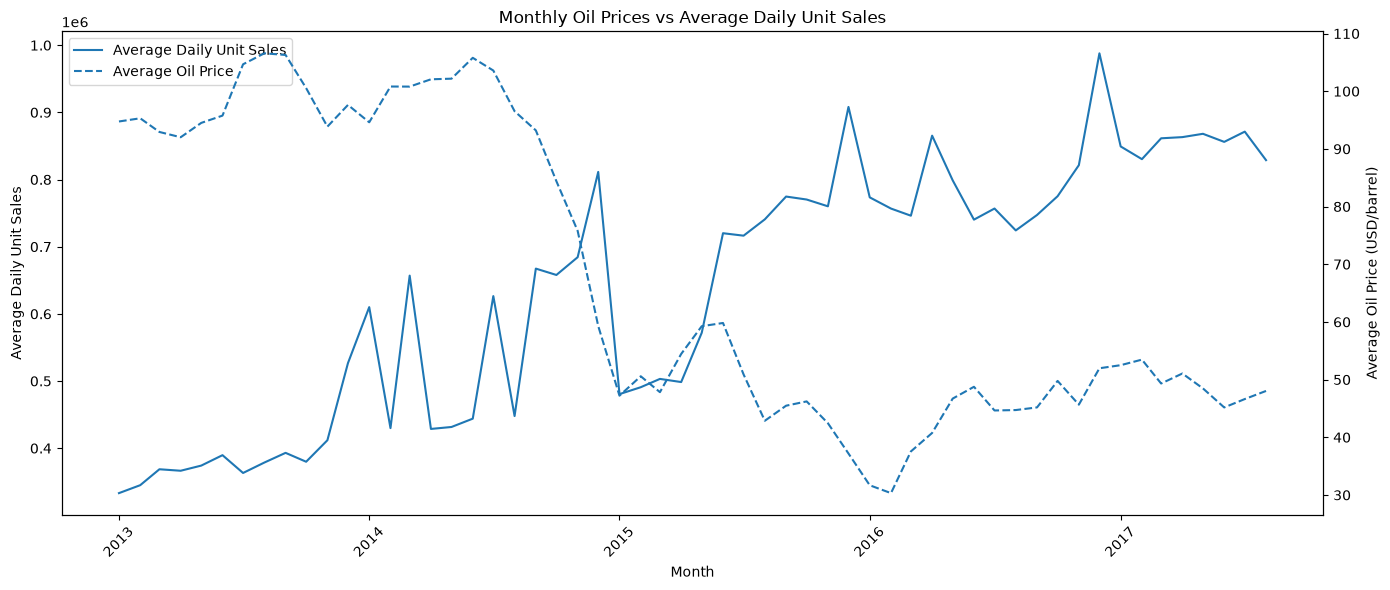

In [284]:

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    oil_sales_analysis["month"],
    oil_sales_analysis["avg_daily_unit_sales"],
    label="Average Daily Unit Sales"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Daily Unit Sales")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    oil_sales_analysis["month"],
    oil_sales_analysis["avg_oil_price"],
    label="Average Oil Price",
    linestyle="--"
)
ax2.set_ylabel("Average Oil Price (USD/barrel)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Monthly Oil Prices vs Average Daily Unit Sales")
plt.tight_layout()
plt.show()

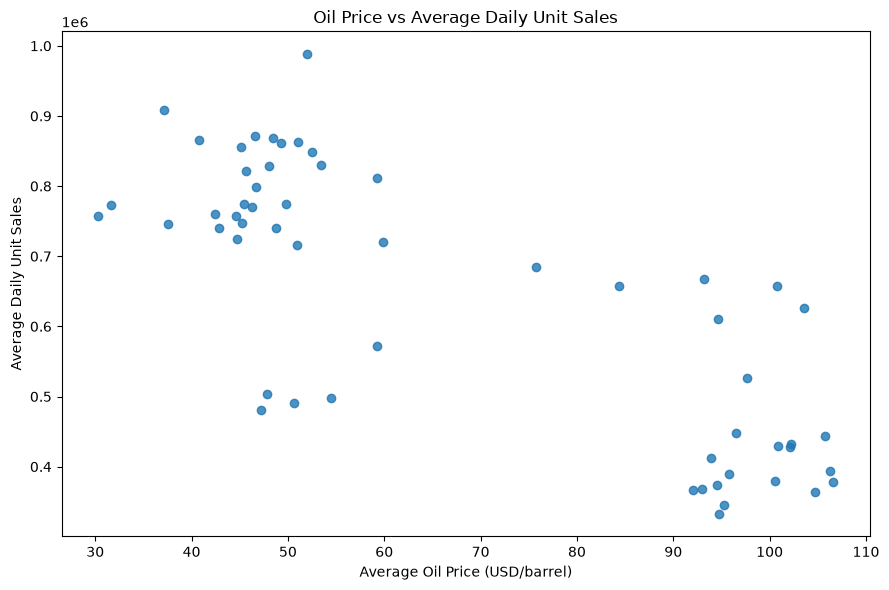

In [285]:
plt.figure(figsize=(9, 6))

plt.scatter(
    oil_sales_analysis["avg_oil_price"],
    oil_sales_analysis["avg_daily_unit_sales"],
    alpha=0.8
)

plt.xlabel("Average Oil Price (USD/barrel)")
plt.ylabel("Average Daily Unit Sales")
plt.title("Oil Price vs Average Daily Unit Sales")
plt.tight_layout()
plt.show()

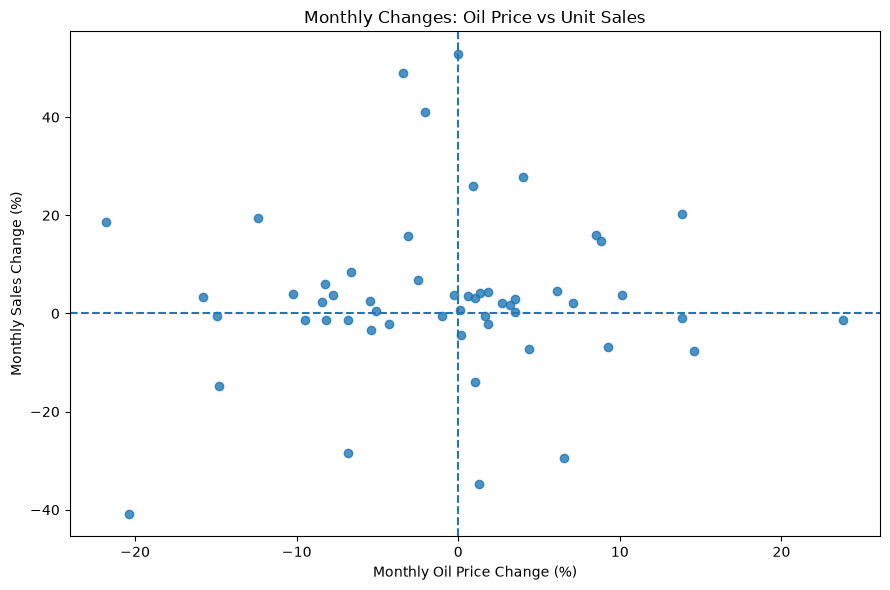

In [286]:
plt.figure(figsize=(9, 6))

plt.scatter(
    monthly_changes["oil_change_pct"],
    monthly_changes["sales_change_pct"],
    alpha=0.8
)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("Monthly Oil Price Change (%)")
plt.ylabel("Monthly Sales Change (%)")
plt.title("Monthly Changes: Oil Price vs Unit Sales")
plt.tight_layout()
plt.show()

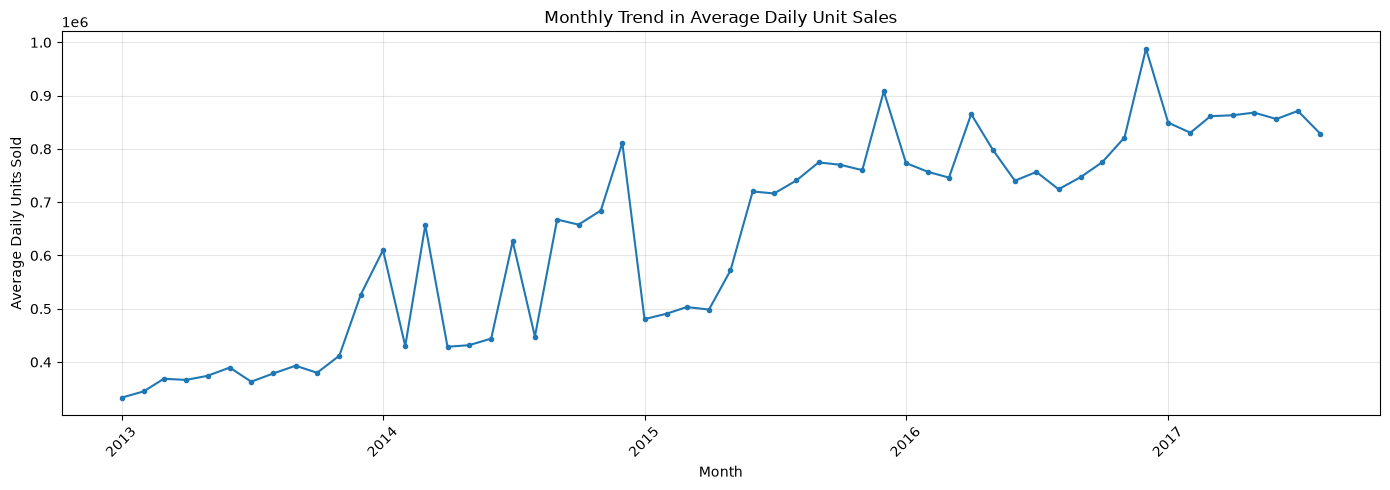

In [287]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_sales["month"],
    monthly_sales["avg_daily_unit_sales"],
    marker="o",
    markersize=3
)

ax.set_title("Monthly Trend in Average Daily Unit Sales")
ax.set_xlabel("Month")
ax.set_ylabel("Average Daily Units Sold")
ax.grid(alpha=0.3)
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

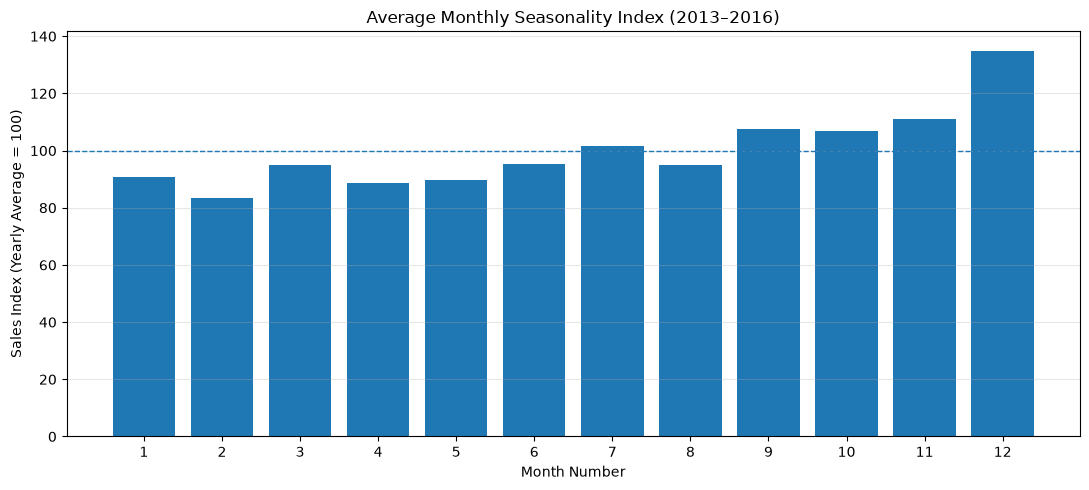

In [288]:
fig, ax = plt.subplots(figsize=(11, 5))

seasonality_plot = (
    monthly_normalized
    .group_by("month_number")
    .agg(
        pl.col("sales_index").mean().alias("avg_sales_index"),
        pl.col("sales_index").std().alias("std_sales_index")
    )
    .sort("month_number")
)

ax.bar(
    seasonality_plot["month_number"].to_list(),
    seasonality_plot["avg_sales_index"].to_list()
)

ax.axhline(100, linestyle="--", linewidth=1)
ax.set_title("Average Monthly Seasonality Index (2013–2016)")
ax.set_xlabel("Month Number")
ax.set_ylabel("Sales Index (Yearly Average = 100)")
ax.set_xticks(range(1, 13))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [289]:
stores_pl = pl.from_pandas(
    stores_df[["store_nbr", "city", "state", "type"]]
)

In [290]:
store_type_plot = (
    train_df
    .group_by("store_nbr")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .join(
        stores_pl.lazy().select("store_nbr", "type"),
        on="store_nbr",
        how="left"
    )
    .group_by("type")
    .agg(
        pl.col("total_unit_sales").mean().alias("avg_sales_per_store")
    )
    .sort("type")
    .collect()
)

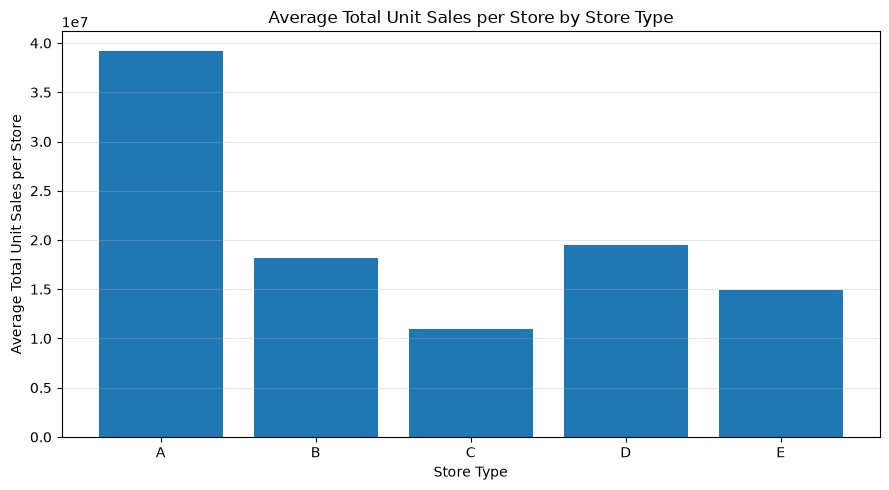

In [291]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    store_type_plot["type"].to_list(),
    store_type_plot["avg_sales_per_store"].to_list()
)

plt.title("Average Total Unit Sales per Store by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Total Unit Sales per Store")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [292]:
family_plot = (
    train_df
    .group_by("item_nbr")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales")
    )
    .join(
        items_pl.lazy().select("item_nbr", "family"),
        on="item_nbr",
        how="left"
    )
    .group_by("family")
    .agg(
        pl.col("total_unit_sales").sum().alias("total_unit_sales")
    )
    .sort("total_unit_sales", descending=True)
    .collect()
)

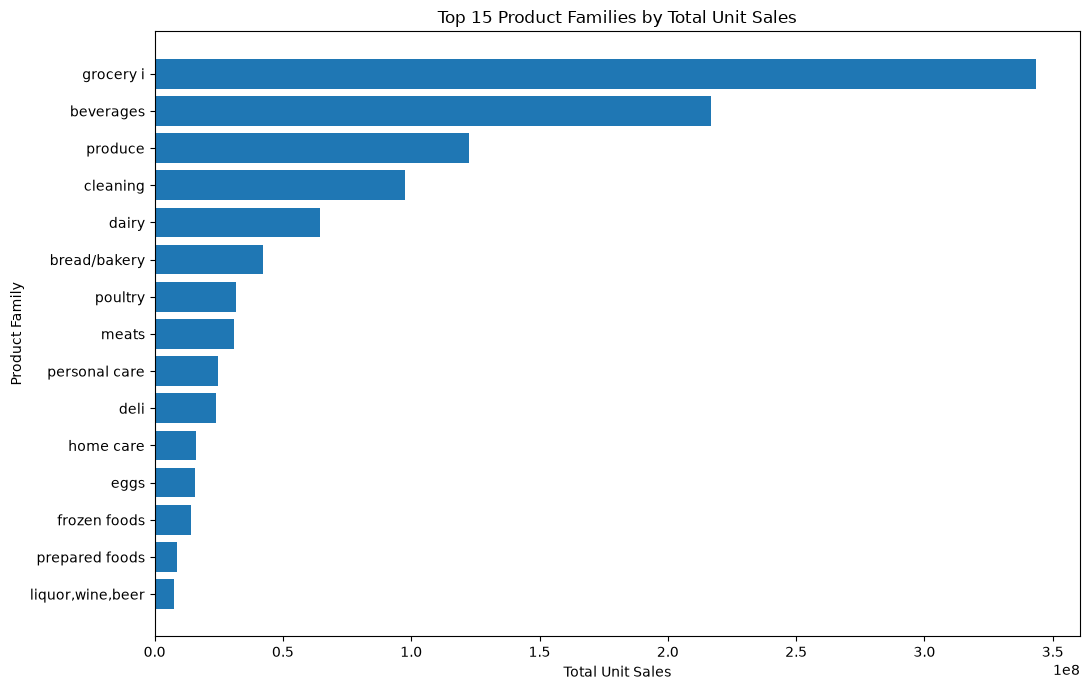

In [293]:
plot_data = family_plot.head(15).sort("total_unit_sales")

plt.figure(figsize=(11, 7))
plt.barh(
    plot_data["family"].to_list(),
    plot_data["total_unit_sales"].to_list()
)
plt.title("Top 15 Product Families by Total Unit Sales")
plt.xlabel("Total Unit Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()

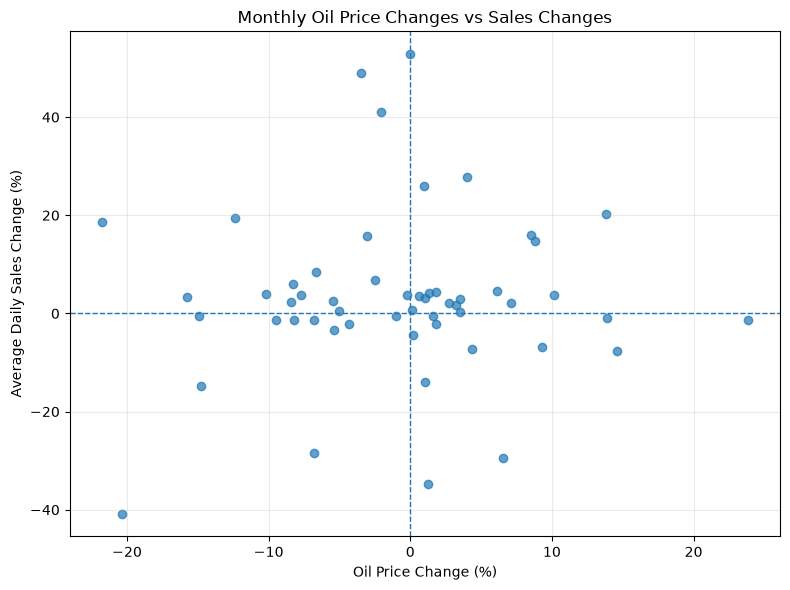

In [294]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    monthly_changes["oil_change_pct"],
    monthly_changes["sales_change_pct"],
    alpha=0.7
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_title("Monthly Oil Price Changes vs Sales Changes")
ax.set_xlabel("Oil Price Change (%)")
ax.set_ylabel("Average Daily Sales Change (%)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [295]:
for name, obj in list(globals().items()):
    if (
        isinstance(obj, (pl.DataFrame, pl.LazyFrame))
        and any(key in name.lower() for key in [
            "monthly", "weekday", "store", "family", "oil", "event"
        ])
    ):
        if isinstance(obj, pl.DataFrame):
            print(name, "shape:", obj.shape)
        else:
            print(name, "type: LazyFrame | columns:", obj.collect_schema().names())

oil_df shape: (1218, 2)
stores_pl shape: (54, 4)
train_stores shape: (54, 1)
train_only_stores shape: (0, 1)
oil_pl shape: (1218, 6)
train_store_dates shape: (83606, 2)
stores_match shape: (54, 7)
national_events shape: (9396, 11)
local_events shape: (512, 16)
regional_events shape: (42, 16)
holiday_store_events shape: (9950, 6)
duplicate_store_dates shape: (349, 3)
events_in_sales_period shape: (8348, 6)
sales_stores shape: (54, 1)
unknown_event_stores shape: (0, 1)
holiday_store_summary shape: (8109, 5)
store_yearly_sales shape: (255, 3)
store_year_counts shape: (5, 2)
store_24 shape: (5, 3)
store_change shape: (48, 4)
store_change_summary shape: (1, 3)
store_trends shape: (10, 3)
store_growth shape: (3, 10)
store_total_sales shape: (54, 4)
top_store_contribution shape: (1, 1)
store_type_performance shape: (5, 4)
type_a_stores shape: (9, 5)
store_type_variability shape: (5, 5)
store_type_cv shape: (5, 4)
store_sales_sensitivity shape: (54, 7)
store_type_sales shape: (54, 5)
store_typ

In [296]:
tables_to_check = [
    "monthly_sales",
    "store_total_sales",
    "store_type_plot",
    "family_plot",
    "oil_sales_analysis",
    "sales_with_events",
]

for name in tables_to_check:
    obj = globals().get(name)

    if obj is None:
        print(f"\n{name}: NOT FOUND")
        continue

    print(f"\n--- {name} ---")

    if isinstance(obj, pl.LazyFrame):
        print(obj.collect_schema())
    elif isinstance(obj, pl.DataFrame):
        print(obj.schema)
        print("Shape:", obj.shape)


--- monthly_sales ---
Schema({'month': Date, 'total_unit_sales': Float64, 'observed_days': UInt32, 'calendar_days': Int8, 'avg_daily_unit_sales': Float64})
Shape: (56, 5)

--- store_total_sales ---
Schema({'store_nbr': Int64, 'total_unit_sales': Float64, 'sales_contribution_pct': Float64, 'cumulative_contribution_pct': Float64})
Shape: (54, 4)

--- store_type_plot ---
Schema({'type': String, 'avg_sales_per_store': Float64})
Shape: (5, 2)

--- family_plot ---
Schema({'family': String, 'total_unit_sales': Float64})
Shape: (33, 2)

--- oil_sales_analysis ---
Schema({'month': Date, 'total_unit_sales': Float64, 'observed_days': UInt32, 'calendar_days': Int8, 'avg_daily_unit_sales': Float64, 'avg_oil_price': Float64, 'observations': UInt32})
Shape: (56, 7)

--- sales_with_events ---
Schema({'date': Date, 'store_nbr': Int64, 'daily_unit_sales': Float64, 'event_count': UInt32, 'holiday_count': UInt32, 'event_type_count': UInt32, 'additional_count': UInt32, 'transfer_count': UInt32, 'bridge_co

In [297]:
overview_kpis = {
    "total_unit_sales": train_df.select(
        pl.col("unit_sales").sum()
    ).collect().item(),

    "avg_daily_unit_sales": monthly_sales.select(
        pl.col("avg_daily_unit_sales").mean()
    ).item(),

    "number_of_stores": stores_pl["store_nbr"].n_unique(),

    "number_of_product_families": family_plot["family"].n_unique(),

    "first_date": monthly_sales["month"].min(),

    "last_date": monthly_sales["month"].max(),
}

print(overview_kpis)

{'total_unit_sales': 1073610268.7878002, 'avg_daily_unit_sales': 639021.3622231663, 'number_of_stores': 54, 'number_of_product_families': 33, 'first_date': datetime.date(2013, 1, 1), 'last_date': datetime.date(2017, 8, 1)}


In [298]:
overview_kpis = {
    "total_unit_sales": train_df.select(
        pl.col("unit_sales").sum()
    ).collect().item(),

    "number_of_stores": stores_pl["store_nbr"].n_unique(),

    "number_of_product_families": family_plot["family"].n_unique(),

    "first_month": monthly_sales["month"].min(),

    "last_month": monthly_sales["month"].max(),
}

print(overview_kpis)

{'total_unit_sales': 1073610268.7878002, 'number_of_stores': 54, 'number_of_product_families': 33, 'first_month': datetime.date(2013, 1, 1), 'last_month': datetime.date(2017, 8, 1)}


In [299]:
daily_sales_kpis = monthly_sales.select(
    pl.col("total_unit_sales").sum().alias("total_unit_sales"),
    pl.col("observed_days").sum().alias("total_observed_days"),
).with_columns(
    (
        pl.col("total_unit_sales") /
        pl.col("total_observed_days")
    ).alias("avg_daily_unit_sales")
)

print(daily_sales_kpis)

shape: (1, 3)
┌──────────────────┬─────────────────────┬──────────────────────┐
│ total_unit_sales ┆ total_observed_days ┆ avg_daily_unit_sales │
│ ---              ┆ ---                 ┆ ---                  │
│ f64              ┆ u32                 ┆ f64                  │
╞══════════════════╪═════════════════════╪══════════════════════╡
│ 1.0736e9         ┆ 1684                ┆ 637535.789066        │
└──────────────────┴─────────────────────┴──────────────────────┘


In [300]:
top_10_stores_contribution = (
    store_total_sales
    .filter(pl.col("store_nbr").is_in(
        store_total_sales.sort(
            "total_unit_sales",
            descending=True
        ).head(10)["store_nbr"]
    ))
    .select(pl.col("sales_contribution_pct").sum())
)

top_3_families_contribution = (
    family_plot
    .sort("total_unit_sales", descending=True)
    .head(3)
    .select(
        (
            pl.col("total_unit_sales").sum()
            / overview_kpis["total_unit_sales"]
            * 100
        ).alias("top_3_families_contribution_pct")
    )
)

print("Top 10 stores contribution (%):")
print(top_10_stores_contribution)

print("Top 3 families contribution (%):")
print(top_3_families_contribution)

Top 10 stores contribution (%):
shape: (1, 1)
┌────────────────────────┐
│ sales_contribution_pct │
│ ---                    │
│ f64                    │
╞════════════════════════╡
│ 40.174809              │
└────────────────────────┘
Top 3 families contribution (%):
shape: (1, 1)
┌─────────────────────────────────┐
│ top_3_families_contribution_pc… │
│ ---                             │
│ f64                             │
╞═════════════════════════════════╡
│ 63.627247                       │
└─────────────────────────────────┘


C:\Users\Mahmoud\AppData\Local\Temp\ipykernel_19172\146667674.py:3: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("store_nbr").is_in(


In [301]:
from datetime import date

growth_kpi = (
    monthly_sales
    .filter(
        pl.col("month").is_in([
            date(2013, 1, 1),
            date(2017, 7, 1)
        ])
    )
    .select("month", "avg_daily_unit_sales")
    .sort("month")
)

print(growth_kpi)

shape: (2, 2)
┌────────────┬──────────────────────┐
│ month      ┆ avg_daily_unit_sales │
│ ---        ┆ ---                  │
│ date       ┆ f64                  │
╞════════════╪══════════════════════╡
│ 2013-01-01 ┆ 333142.314065        │
│ 2017-07-01 ┆ 871337.889226        │
└────────────┴──────────────────────┘


In [302]:
start_sales = growth_kpi["avg_daily_unit_sales"][0]
end_sales = growth_kpi["avg_daily_unit_sales"][1]

growth_pct = (end_sales - start_sales) / start_sales * 100

print(f"Change in average daily unit sales: {growth_pct:.2f}%")

Change in average daily unit sales: 161.55%


In [303]:
yearly_sales_kpi = (
    train_df
    .filter(pl.col("year").is_in([2013, 2014, 2015, 2016]))
    .group_by("year")
    .agg(
        pl.col("unit_sales").sum().alias("total_unit_sales"),
        pl.col("date").n_unique().alias("observed_days")
    )
    .sort("year")
)

print(yearly_sales_kpi.collect())

shape: (4, 3)
┌──────┬──────────────────┬───────────────┐
│ year ┆ total_unit_sales ┆ observed_days │
│ ---  ┆ ---              ┆ ---           │
│ i32  ┆ f64              ┆ u32           │
╞══════╪══════════════════╪═══════════════╡
│ 2013 ┆ 1.4042e8         ┆ 364           │
│ 2014 ┆ 2.0947e8         ┆ 364           │
│ 2015 ┆ 2.4087e8         ┆ 364           │
│ 2016 ┆ 2.8863e8         ┆ 365           │
└──────┴──────────────────┴───────────────┘


In [304]:
yearly_sales_kpi = (
    yearly_sales_kpi
    .with_columns(
        (
            pl.col("total_unit_sales") / pl.col("observed_days")
        ).alias("avg_daily_unit_sales")
    )
    .with_columns(
        (
            (pl.col("avg_daily_unit_sales") /
             pl.col("avg_daily_unit_sales").shift(1) - 1) * 100
        ).alias("yoy_change_pct")
    )
)

print(yearly_sales_kpi.collect())

shape: (4, 5)
┌──────┬──────────────────┬───────────────┬──────────────────────┬────────────────┐
│ year ┆ total_unit_sales ┆ observed_days ┆ avg_daily_unit_sales ┆ yoy_change_pct │
│ ---  ┆ ---              ┆ ---           ┆ ---                  ┆ ---            │
│ i32  ┆ f64              ┆ u32           ┆ f64                  ┆ f64            │
╞══════╪══════════════════╪═══════════════╪══════════════════════╪════════════════╡
│ 2013 ┆ 1.4042e8         ┆ 364           ┆ 385763.736069        ┆ null           │
│ 2014 ┆ 2.0947e8         ┆ 364           ┆ 575478.355994        ┆ 49.178967      │
│ 2015 ┆ 2.4087e8         ┆ 364           ┆ 661724.809478        ┆ 14.986915      │
│ 2016 ┆ 2.8863e8         ┆ 365           ┆ 790776.370553        ┆ 19.502301      │
└──────┴──────────────────┴───────────────┴──────────────────────┴────────────────┘


# Favorita Grocery Sales Analysis
## Analytical Progress & Findings

**Project status:** Exploratory Data Analysis — In Progress  
**Primary tool:** Python with Polars  
**Dataset:** Favorita grocery store sales data  
**Analysis scope:** Store performance, product performance, and time-based sales patterns

---

## 1. Project Overview

This project explores grocery sales data to identify patterns in store performance, product contribution, and sales behavior over time.

The analysis focuses on descriptive insights supported by the available data. It distinguishes observed sales patterns from causal explanations that cannot be established from the current analysis alone.

### Key Data Characteristics

- The cleaned training dataset contains approximately **125.5 million rows**.
- The observed date range is **January 1, 2013, to August 15, 2017**.
- The store dimension contains **54 stores**.
- The product catalog contains **4,100 products**.
- Product sales are measured using `unit_sales`, representing units sold rather than monetary revenue or profit.
- August 2017 is a partial month, with observations ending on August 15.

---

## 2. Store Performance Analysis

### 2.1 Store Ranking

Stores were aggregated by total unit sales and ranked to identify the highest-volume locations.

| Store | Total units sold |
|---:|---:|
| 44 | 62.09 million |
| 45 | 54.50 million |
| 47 | 50.95 million |
| 3 | 50.48 million |
| 49 | 43.42 million |

The ten highest-volume stores accounted for approximately **40.17% of total unit sales**.

**Finding:** Sales volume is concentrated among a subset of stores. This concentration is descriptive and does not establish why those stores perform better.

### 2.2 Performance by Store Type

| Store type | Number of stores | Total units sold | Average units per store |
|---|---:|---:|---:|
| A | 9 | 353.04 million | 39.23 million |
| B | 8 | 145.25 million | 18.16 million |
| C | 15 | 164.43 million | 10.96 million |
| D | 18 | 351.06 million | 19.50 million |
| E | 4 | 59.82 million | 14.96 million |

**Findings:**

- Type A has the highest average cumulative unit sales per store.
- Type D has the highest aggregate unit sales among the store types, narrowly ahead of Type A.
- Type E has only four stores, so its average should be interpreted cautiously.
- Aggregate sales and average sales per store answer different business questions and should not be treated as interchangeable.

### 2.3 Variation Within Store Types

Store-level distributions were examined using measures including the median, standard deviation, coefficient of variation, and interquartile-range-based outlier checks.

These measures help distinguish store types with relatively consistent performance from types with greater variation between individual stores.

The analysis is descriptive; differences between store types do not establish that store type itself causes higher sales.

### 2.4 Year-over-Year Comparisons

Because the dataset ends on August 15, 2017, comparisons involving 2017 were aligned to the same January 1–August 15 period in the comparison years.

This avoids comparing a partial year against a complete year.

---

## 3. Product Performance Analysis

### 3.1 Catalog Validation

The product catalog contains **4,100 rows and 4,100 unique product IDs**.

All item IDs observed in the sales data mapped to a product in the catalog.

Product sales were aggregated by `item_nbr`, then joined with product metadata to analyze product and family performance.

### 3.2 Sales Contribution by Product Family

The dataset contains **33 product families**.

| Product family | Total units sold | Contribution to total units |
|---|---:|---:|
| Grocery I | 343.46 million | 31.99% |
| Beverages | 216.94 million | 20.21% |
| Produce | 122.70 million | 11.43% |
| Cleaning | 97.52 million | 9.08% |
| Dairy | 64.49 million | 6.01% |
| Bread/Bakery | 42.13 million | 3.92% |
| Poultry | 31.88 million | 2.97% |

**Findings:**

- Grocery I is the largest family by unit volume.
- Grocery I and Beverages together account for approximately **52.20% of total unit sales**.
- The seven largest families listed above account for approximately **85.61% of total unit sales**.

These percentages describe unit-volume contribution, not revenue or profit contribution. Products may differ substantially in price, cost, and margin.

### 3.3 Product Counts and Average Sales

Product counts and average units sold per catalog product were calculated by family.

These averages provide a broad comparison of family scale, but they do not account for differences in product availability, launch dates, active selling days, or product lifecycle.

Consequently, a family with a high average does not necessarily have higher demand for every product in that family.

### 3.4 Sales Distribution Within Product Families

Mean-to-median ratios were calculated to identify families where the distribution of product sales may be strongly right-skewed.

For example:

- Liquor, Wine, Beer: mean-to-median ratio of approximately **5.70**.
- Grocery II: approximately **3.48**.
- Personal Care: approximately **2.22**.
- Beverages: approximately **2.02**.

A high ratio suggests that some products may sell substantially more units than a typical product in the same family. This ratio is a descriptive skew indicator, not a formal outlier test.

### 3.5 Top-Product Concentration

The top 10% of products within each family were used to examine concentration of unit sales.

Examples include:

- Grocery II: approximately **58.01%** of family unit sales.
- Liquor, Wine, Beer: approximately **57.39%**.

Families with very few products require special care. For a family containing only one product, a 100% concentration result is mechanically expected and does not imply unusual concentration.

### 3.6 Top and Bottom Products

The ten highest- and lowest-volume products were identified.

The lowest-volume products often had first or last observed sale dates close to the end of the dataset. Some appeared in only a handful of observed sale dates.

**Important limitation:** Low cumulative sales do not necessarily indicate weak demand. Products introduced late in the observation period, discontinued products, limited availability, or incomplete observation windows can produce low totals.

The catalog's `class` field is numeric and does not provide human-readable product names in the metadata used so far.

### 3.7 Product Performance Across Stores

Product-store sales were aggregated and joined with store attributes, including:

- `city`
- `state`
- `type`
- `cluster`

The resulting analysis included **528 observed product-store combinations** for the selected products.

Performance was compared across store types, and store-level results were retained for further exploration.

An absent product-store combination must not automatically be interpreted as zero demand, product unavailability, or a stockout. The current data represents observed sales records, not a fully validated product availability history.

---

## 4. Time-Based Sales Analysis

### 4.1 Monthly Sales Trend

Daily and monthly sales aggregates were calculated. Monthly metrics included:

- Total unit sales.
- Number of observed dates.
- Number of calendar days.
- Average daily unit sales.

For complete months, every calendar day in the month had at least one sales record somewhere in the dataset. August 2017 had only 15 observed days out of 31.

Selected observations:

| Month | Average daily unit sales |
|---|---:|
| January 2013 | 333,142 |
| April 2017 | 863,177 |
| May 2017 | 868,124 |
| June 2017 | 856,092 |
| July 2017 | 871,338 |
| August 2017, partial | 828,888 |

**Finding:** Average daily unit sales increased substantially over the observed period.

However, this aggregate trend does not isolate the effects of customer demand, store coverage, product assortment, promotions, or other operational changes. The partial August 2017 result should not be compared directly with full-month totals.

### 4.2 Monthly Seasonality

To compare seasonality across years with different overall sales levels, each month's average daily unit sales was normalized against the corresponding year's average monthly daily sales.

An index of **100** represents the average month within that year.

The seasonal summary excluded 2017 because only January through July are complete months, and the year is incomplete.

| Month | Average normalized sales index |
|---|---:|
| January | 90.73 |
| February | 83.52 |
| March | 95.06 |
| April | 88.58 |
| May | 89.88 |
| August | 94.91 |
| September | 107.40 |
| October | 106.85 |
| November | 111.15 |
| December | 134.97 |

June and July were also included in the normalization analysis, but their summary values are not reproduced here because they were not available in the recorded summary output.

**Findings:**

- December had the highest average normalized index, approximately **134.97**, or 35% above the average month.
- November averaged approximately 111.15.
- February averaged approximately 83.52.
- December's normalized index had a standard deviation of approximately 7.03 across the four complete years, indicating a comparatively consistent elevated pattern in this sample.

December was also the highest month by average daily unit sales in each complete year from 2013 through 2016.

These results are consistent with a possible seasonal pattern. Four complete years provide limited evidence, and the analysis does not establish the cause of the pattern.

### 4.3 Day-of-Week Analysis

Daily sales were aggregated by date, and weekday patterns were compared across 2013–2016.

To account for differing annual sales levels, average daily sales for each weekday were normalized against the corresponding year's average daily sales. The resulting weekday index uses 100 as the annual average.

| Day | Average normalized sales index |
|---|---:|
| Sunday | 130.83 |
| Saturday | 121.62 |
| Monday | 96.87 |
| Wednesday | 92.13 |
| Friday | 90.08 |
| Tuesday | 88.98 |
| Thursday | 79.49 |

**Findings:**

- Sunday averaged approximately 30.8% above the annual daily-sales baseline.
- Saturday averaged approximately 21.6% above the baseline.
- Thursday averaged approximately 20.5% below the baseline.
- The relative weekday pattern was similar across the four years, with low variation in the normalized indices.

These are aggregate unit-sales patterns. They do not establish the reason for weekday differences or prove that individual stores followed identical patterns.

One unusually low daily aggregate was observed on January 1, 2013. It may warrant a separate data-quality or coverage check before being treated as a normal operating day.

### 4.4 Investigating Store Count as a Driver of Growth

The number of distinct stores with at least one observed sales record was calculated for each month.

- January–April 2013: 46 stores per month.
- May 2013: 47 stores.
- April–August 2017: 54 stores per month.

A preliminary comparison of total average daily unit sales divided by the number of observed stores showed that the increase in store count alone could not explain the overall growth pattern.

This ratio is only approximate because a store counted once in a month is not necessarily observed on every day of that month.

### 4.5 Fixed-Store Comparison

To reduce the influence of store-count changes, sales were compared for the same **46 stores** in January 2013 and July 2017.

| Metric | January 2013 | July 2017 |
|---|---:|---:|
| Total unit sales | Approximately 10.327 million | Approximately 23.568 million |
| Number of stores | 46 | 46 |
| Average monthly units per store | 224,509 | 512,349 |

Total unit sales increased by approximately **128.3%** between these two months for the same group of stores.

Both months contain 31 calendar days, making their monthly totals more comparable on the basis of month length.

**Interpretation:** The observed increase cannot be explained simply by the addition of stores to the comparison group. Sales volume increased substantially within a fixed group of stores.

**What this does not prove:** The result does not establish a 128.3% increase in underlying customer demand. Product assortment, availability, promotions, seasonal differences, and other operational factors may have contributed. This is a two-month comparison, not a complete decomposition of the long-term sales trend.

---

## 5. Data Interpretation and Analytical Limitations

The following principles were applied throughout the analysis:

1. **Unit sales are not revenue or profit.** The current results measure units sold and do not provide monetary performance.
2. **Observed sales are not the same as underlying demand.** Sales can be constrained by availability and influenced by promotions and assortment.
3. **Missing store-product-date records are ambiguous.** They do not automatically mean zero sales, product unavailability, or a stockout.
4. **Observed first-sale dates are not confirmed launch dates.** A product's first record in the dataset may occur after its actual introduction.
5. **Partial periods require special handling.** August 2017 is incomplete, and annual comparisons involving 2017 must use aligned date ranges.
6. **Descriptive patterns are not causal explanations.** Store-type differences, seasonality, and weekday patterns identify associations rather than causes.
7. **Aggregations and joins require validation.** Dimension joins must preserve the intended row granularity and avoid multiplying sales through duplicate keys.
8. **Promotion nulls must not be treated automatically as false.** A null promotion value indicates missing or unknown information unless further validation establishes otherwise.

---
## 5. Promotions Analysis

### 5.1 Promotion Data Quality and Coverage

The `onpromotion` field was examined before conducting promotional comparisons.

- `True`: 7.81 million rows (approximately 6.22%).
- `False`: 96.03 million rows (approximately 76.52%).
- `Null`: 21.66 million rows (approximately 17.26%).

Promotion information was not available for any records in 2013, and a portion of 2014 records also had missing promotion values. Therefore, null values were not treated as non-promotional observations.

**Analytical decision:** The main promotion comparisons focused on 2015–2017, when promotion labels were more consistently available. The increasing share of records marked as promotional over time does not, by itself, establish an increase in promotional effectiveness or intensity.

### 5.2 Overall Sales Comparison

Average `unit_sales` per observed row was compared between promotional and non-promotional records.

| Year | Average units per non-promotional row | Average units per promotional row | Relative difference |
|---|---:|---:|---:|
| 2015 | 8.40 | 14.69 | +74.9% |
| 2016 | 7.72 | 12.43 | +60.9% |
| 2017 | 7.43 | 13.72 | +84.6% |

**Finding:** Promotional records had higher average unit sales per row in all three years.

This comparison is descriptive. Promotional products may have been selected because they were already expected to sell well, and the comparison does not control for product mix, store differences, seasonality, availability, or other factors. The result therefore does not establish that promotions caused the observed differences.

### 5.3 Product-Level Comparison

Products were compared using their average unit sales in promotional and non-promotional records across 2015–2017.

To reduce unstable comparisons caused by very small sample sizes, products were retained only when they had at least 30 observations under each condition.

- Products meeting the observation threshold: **3,610**.
- Products with a higher average under promotion: **2,900 (80.3%)**.
- Products with a lower average under promotion: **710 (19.7%)**.
- Median relative difference: approximately **+29.20%**.

**Finding:** Most products in the filtered comparison had higher average observed unit sales in promotional records.

The result describes an association across observed records. It does not measure the causal uplift attributable to a promotion, and it does not imply that every product benefits from promotional activity.

### 5.4 Product Comparisons by Year

Product-level comparisons were also calculated separately for each year, requiring at least 30 observations under both promotional and non-promotional conditions.

| Year | Products compared | Higher average under promotion | Lower average under promotion | Median relative difference |
|---|---:|---:|---:|---:|
| 2015 | 1,961 | 1,349 | 612 | +18.46% |
| 2016 | 3,237 | 2,515 | 722 | +26.88% |
| 2017 | 2,603 | 2,280 | 323 | +40.62% |

The eligible product population differed across years, and 2017 covers only part of the calendar year. These results should not be interpreted as evidence that promotions became more effective over time.

### 5.5 Store–Product Comparisons

To account for differences between stores and products, promotional and non-promotional observations were compared within the same store–product combination and year. Both conditions required at least 30 observations.

| Year | Eligible store–product pairs | Higher average under promotion | Lower average under promotion | Median relative difference |
|---|---:|---:|---:|---:|
| 2015 | 15,242 | 11,236 | 4,003 | +20.57% |
| 2016 | 48,260 | 40,397 | 7,856 | +28.62% |
| 2017 | 38,962 | 35,149 | 3,809 | +42.96% |

The comparison provides a more specific descriptive view than the overall comparison because each comparison is made within a particular store, product, and year. However, it still does not control for all time-related effects, promotional targeting, or product availability. Some groups had zero or otherwise non-comparable relative differences and therefore do not appear in the higher-versus-lower counts.

### 5.6 Store–Product–Weekday Comparisons

A further comparison was conducted within the same store, product, weekday, and year to examine whether the observed association remained when weekday patterns were held more consistent.

A minimum of 10 observations under each condition was used because no groups met a threshold of 30 observations for both promotional and non-promotional records.

| Year | Eligible comparison groups | Higher average under promotion | Lower average under promotion | Median relative difference |
|---|---:|---:|---:|---:|
| 2015 | 10,161 | 5,978 | 4,152 | +6.35% |
| 2016 | 55,998 | 46,767 | 9,160 | +34.51% |
| 2017 | 30,588 | 28,190 | 2,346 | +69.28% |

The higher and lower counts do not always sum to the total number of eligible groups because some groups had zero differences.

**Finding:** Higher average unit sales under promotion were still common in these more narrowly defined comparisons. However, the size of the observed differences varied by year, and the eligible groups were not identical across years. These results remain observational and do not establish causal promotional effects.

### 5.7 Promotion Analysis Limitations

The following limitations apply to the promotion analysis:

1. `unit_sales` measures units sold, not revenue, profit, or promotional return on investment.
2. Promotional and non-promotional observations may differ systematically because of promotion targeting, product selection, store characteristics, and availability.
3. The analysis does not establish what sales would have been if the same product had not been promoted under otherwise identical conditions.
4. Missing promotion labels, particularly in 2013 and part of 2014, restrict valid comparisons across the full dataset period.
5. The 2017 observation period is incomplete, and the eligible products and store–product groups differ across years.
6. Minimum observation thresholds improve comparability but do not eliminate selection bias or other confounding factors.

**Overall conclusion:** Promotional records were associated with higher average unit sales across several levels of comparison. Further analysis with a suitable causal design and additional business data would be required to estimate the incremental effect of promotions or their financial value.

**## Holiday and Event Analysis**

**### Overall Comparison**

The overall comparison showed that average unit sales on holiday store-days were approximately **4.8% higher**, while the median was lower. This difference between the mean and median indicates that the observed increase in average sales was not uniform across all observations.

**### Within-Store and Weekday Comparison**

After comparing observations within the same store and weekday, the median difference was approximately **+3.46%**. The `Additional` and `Event` categories also showed positive associations in the within-store, weekday-adjusted comparisons.

**### Findings and Limitations**

- The overall mean and median did not move in the same direction, so holiday sales should not be described as universally higher.
- The positive median difference remained in the store- and weekday-adjusted comparison.
- The `Additional` and `Event` categories showed positive associations in the adjusted comparisons.
- These findings are descriptive and do not establish that holidays or events caused the observed changes.
- Differences in product availability, date composition, store operations, and other factors may have influenced the results.

**Overall conclusion:** Holiday and event classifications were associated with differences in observed unit sales. The results depend on the comparison method and should not be interpreted as causal effects.

---

**## Exploratory Oil Price Analysis**

**### Oil Price Levels and Sales Levels**

Monthly oil-price levels were compared with monthly sales levels to investigate the association between the two variables.

| Correlation Method | Correlation Coefficient |
|---|---:|
| Pearson | -0.78776 |
| Spearman | -0.709569 |

Both correlation measures indicated a negative association between oil-price levels and sales levels. However, correlations between time-series levels can be influenced by common trends and other time-related factors. These results do not establish that oil prices caused changes in sales.

**### Month-to-Month Changes**

The analysis also compared month-to-month percentage changes in oil prices and sales.

| Correlation Method | Correlation Coefficient |
|---|---:|
| Pearson | +0.067145 |
| Spearman | -0.02794 |

Both coefficients were close to zero, indicating little apparent association between monthly oil-price changes and monthly sales changes.

**### Findings and Limitations**

- Oil-price levels had a negative correlation with sales levels.
- The relationship was negligible when examining month-to-month percentage changes.
- This difference highlights the importance of distinguishing correlations between levels from correlations between changes.
- Monthly aggregation may conceal shorter-term relationships.
- The analysis did not control for all factors that could influence sales and oil prices.
- Correlation does not establish causation.

**Overall conclusion:** Although oil-price levels were negatively correlated with sales levels, month-to-month changes showed little apparent association. The available analysis does not establish that oil prices directly influenced sales performance.

---

## 7. Overall Conclusion

The exploratory analysis identifies meaningful differences in store performance, a concentration of unit sales among major product families, and recurring monthly and weekly sales patterns.

The time-based analysis also shows that sales increased substantially within the same 46 stores between January 2013 and July 2017. This indicates that changes in store count alone do not explain the observed increase.

The findings remain descriptive. Further investigation of product availability, assortment, promotions, holidays, and other operational factors would be needed to explain the drivers of growth.

The project is still in progress; the current findings provide a documented foundation for the remaining analysis and subsequent Power BI reporting.

**## Key Performance Indicators (KPIs)**

This section documents the main quantitative indicators used to summarize store performance, product performance, and sales trends. The indicators are based on observed unit sales and should not be interpreted as financial performance metrics.

**### 1. Overall Sales Performance**

| KPI | Value | Interpretation |
|---|---:|---|
| Total Unit Sales | 1,073,610,268.79 | Total recorded unit sales across the cleaned dataset |
| Number of Stores | 54 | Number of distinct stores represented in the dataset |
| Number of Products | 4,100 | Number of distinct items represented in the dataset |
| Number of Product Families | 33 | Number of product families represented in the dataset |
| Analysis Period | Jan 1, 2013 – Aug 15, 2017 | The full period covered by the cleaned sales data |

**### 2. Store Performance KPIs**

| KPI | Value | Interpretation |
|---|---:|---|
| Top 10 Stores' Sales Contribution | 40.17% | Share of total unit sales generated by the ten highest-selling stores |
| Highest-Selling Store Type | Type A | Store type with the highest aggregate unit sales |
| Type A Total Unit Sales | 353.04 million | Aggregate unit sales recorded across Type A stores |
| Type D Total Unit Sales | 351.06 million | Aggregate unit sales recorded across Type D stores |

**### 3. Product Performance KPIs**

| KPI | Value | Interpretation |
|---|---:|---|
| Grocery I Sales Contribution | 31.99% | Share of total unit sales attributed to the Grocery I family |
| Beverages Sales Contribution | 20.21% | Share of total unit sales attributed to the Beverages family |
| Produce Sales Contribution | 11.43% | Share of total unit sales attributed to the Produce family |
| Top 3 Families' Combined Contribution | 63.63% | Share of total unit sales represented by the three highest-selling product families |

**### 4. Time-Based Performance KPIs**

| KPI | Value | Interpretation |
|---|---:|---|
| Sales Growth: Jan 2013 to Jul 2017 | +161.55% | Change in average daily unit sales between the two months |
| Fixed-Store Sales Growth | +128.3% | Change in total unit sales between Jan 2013 and Jul 2017 for the same 46 stores |
| Highest-Selling Month | December | Month with the highest average daily unit sales in each complete year from 2013 to 2016 |
| Highest-Selling Weekday | Sunday | Weekday with the highest average normalized sales index |
| Sunday Normalized Sales Index | 130.83 | Average daily sales were approximately 30.83% above the annual daily-sales baseline |
| Saturday Normalized Sales Index | 121.62 | Average daily sales were approximately 21.62% above the annual daily-sales baseline |

**### 5. Promotions, Holidays, and External Factors**

| Indicator | Result | Interpretation |
|---|---|---|
| Promotional Sales Association | Higher average unit sales on promotional records across 2015–2017 | Descriptive association; not proof of incremental promotional impact |
| Holiday Store-Day Comparison | Average unit sales approximately 4.8% higher; median lower | Overall mean and median showed different directions |
| Store- and Weekday-Adjusted Holiday Comparison | Median difference approximately +3.46% | Positive median difference after accounting for store and weekday patterns |
| Oil Price vs. Sales Levels | Pearson: -0.78776; Spearman: -0.709569 | Negative correlation between the levels of the two series |
| Oil Price vs. Sales Monthly Changes | Pearson: +0.067145; Spearman: -0.02794 | Little apparent association between month-to-month percentage changes |

**### KPI Interpretation and Limitations**

- Unit sales measure quantities sold, not revenue, profit, or profit margin.
- Store and product contribution percentages describe the distribution of unit sales; they do not indicate financial contribution.
- The Jan 2013–Jul 2017 growth comparisons describe observed sales changes and do not isolate their causes.
- August 2017 is an incomplete month and should not be compared directly with complete months without adjusting for the observation period.
- Promotion, holiday, and oil-price results are observational and do not establish causal relationships.
- All KPI values should be validated against the final analytical tables before being used in the SQL database or Power BI report.

In [306]:
import polars as pl

for name, obj in sorted(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(obj, pl.DataFrame):
        print(f"{name:35} DataFrame {obj.shape}")

    elif isinstance(obj, pl.LazyFrame):
        print(f"{name:35} LazyFrame")

additional_comparison               DataFrame (1, 7)
bottom_10_items                     DataFrame (10, 3)
bottom_10_items_details             DataFrame (10, 4)
bottom_item_coverage                DataFrame (10, 5)
change_correlations                 DataFrame (1, 3)
change_stats                        DataFrame (1, 4)
cities                              DataFrame (22, 1)
common_store_comparison             DataFrame (2, 3)
common_store_sales                  DataFrame (2, 4)
common_stores                       DataFrame (46, 1)
comparison_months                   DataFrame (2, 4)
comparison_period                   DataFrame (253, 3)
comparison_summary                  DataFrame (1, 7)
correlation_results                 DataFrame (1, 2)
daily_sales                         DataFrame (1684, 4)
daily_sales_kpis                    DataFrame (1, 3)
daily_store_sales                   DataFrame (83606, 3)
data                                DataFrame (5, 3)
december_avg                    

In [307]:
import polars as pl

table_inventory = []

for name, obj in sorted(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(obj, pl.DataFrame):
        table_inventory.append({
            "table_name": name,
            "type": "DataFrame",
            "rows": obj.height,
            "columns": obj.width
        })

    elif isinstance(obj, pl.LazyFrame):
        table_inventory.append({
            "table_name": name,
            "type": "LazyFrame",
            "rows": None,
            "columns": len(obj.collect_schema().names())
        })

inventory_df = pl.DataFrame(table_inventory)

print("Total tables:", inventory_df.height)
print(inventory_df)

Total tables: 142
shape: (142, 4)
┌──────────────────────────┬───────────┬───────┬─────────┐
│ table_name               ┆ type      ┆ rows  ┆ columns │
│ ---                      ┆ ---       ┆ ---   ┆ ---     │
│ str                      ┆ str       ┆ i64   ┆ i64     │
╞══════════════════════════╪═══════════╪═══════╪═════════╡
│ additional_comparison    ┆ DataFrame ┆ 1     ┆ 7       │
│ bottom_10_items          ┆ DataFrame ┆ 10    ┆ 3       │
│ bottom_10_items_details  ┆ DataFrame ┆ 10    ┆ 4       │
│ bottom_item_coverage     ┆ DataFrame ┆ 10    ┆ 5       │
│ change_correlations      ┆ DataFrame ┆ 1     ┆ 3       │
│ …                        ┆ …         ┆ …     ┆ …       │
│ yearly_month_summary     ┆ DataFrame ┆ 5     ┆ 5       │
│ yearly_product_promotion ┆ DataFrame ┆ 11349 ┆ 7       │
│ yearly_promotion_summary ┆ DataFrame ┆ 3     ┆ 7       │
│ yearly_sales             ┆ DataFrame ┆ 5     ┆ 2       │
│ yearly_sales_kpi         ┆ LazyFrame ┆ null  ┆ 5       │
└─────────────────────

In [308]:
print(inventory_df.write_csv())

table_name,type,rows,columns
additional_comparison,DataFrame,1,7
bottom_10_items,DataFrame,10,3
bottom_10_items_details,DataFrame,10,4
bottom_item_coverage,DataFrame,10,5
change_correlations,DataFrame,1,3
change_stats,DataFrame,1,4
cities,DataFrame,22,1
common_store_comparison,DataFrame,2,3
common_store_sales,DataFrame,2,4
common_stores,DataFrame,46,1
comparison_months,DataFrame,2,4
comparison_period,DataFrame,253,3
comparison_summary,DataFrame,1,7
correlation_results,DataFrame,1,2
daily_sales,DataFrame,1684,4
daily_sales_kpis,DataFrame,1,3
daily_store_sales,DataFrame,83606,3
data,DataFrame,5,3
december_avg,DataFrame,4,2
december_comparison,DataFrame,44,5
donut_data,DataFrame,6,2
duplicate_store_dates,DataFrame,349,3
event_comparison,DataFrame,1,7
event_flags,DataFrame,8325,17
event_multiplicity,DataFrame,8325,5
event_type_results,DataFrame,14,5
events_in_sales_period,DataFrame,8348,6
family_distribution,DataFrame,33,5
family_plot,DataFrame,33,2
family_product_counts,DataFrame,33,2
fam

In [309]:
inventory_df.write_csv("table_inventory.csv")

In [310]:
tables_to_check = [
    "daily_sales",
    "monthly_sales",
    "store_total_sales",
    "store_type_sales",
    "family_sales",
    "top_10_items_details",
    "yearly_product_promotion",
    "holiday_weekday_effect",
    "oil_sales_analysis",
    "stores_pl",
    "items_pl",
    "transactions_pl"
]

for name in tables_to_check:
    obj = globals().get(name)

    if isinstance(obj, pl.DataFrame):
        print(f"\n{name} | shape={obj.shape}")
        print(obj.columns)

    elif isinstance(obj, pl.LazyFrame):
        print(f"\n{name} | LazyFrame")
        print(obj.collect_schema().names())

    else:
        print(f"\n{name} | NOT FOUND")


daily_sales | shape=(1684, 4)
['date', 'total_unit_sales', 'weekday', 'year']

monthly_sales | shape=(56, 5)
['month', 'total_unit_sales', 'observed_days', 'calendar_days', 'avg_daily_unit_sales']

store_total_sales | shape=(54, 4)
['store_nbr', 'total_unit_sales', 'sales_contribution_pct', 'cumulative_contribution_pct']

store_type_sales | shape=(54, 5)
['store_nbr', 'total_unit_sales', 'sales_contribution_pct', 'cumulative_contribution_pct', 'type']

family_sales | shape=(33, 6)
['family', 'total_unit_sales', 'sales_contribution_pct', 'cumulative_contribution_pct', 'number_of_products', 'avg_units_per_product']

top_10_items_details | shape=(10, 4)
['item_nbr', 'total_unit_sales', 'family', 'class']

yearly_product_promotion | shape=(11349, 7)
['year', 'item_nbr', 'row_count_false', 'row_count_true', 'avg_unit_sales_false', 'avg_unit_sales_true', 'sales_difference_pct']

holiday_weekday_effect | shape=(271, 7)
['store_nbr', 'weekday', 'avg_daily_sales_false', 'avg_daily_sales_true',

In [312]:
import polars as pl

tables_to_check = [
    "daily_sales", "daily_store_sales",
    "monthly_sales", "monthly_by_year", "monthly_normalized",
    "yearly_sales", "weekday_sales", "weekday_summary",
    "store_total_sales", "store_type_sales",
    "store_yearly_sales", "store_monthly_sales",
    "family_sales", "top_10_items_details",
    "bottom_10_items_details", "product_store_type_analysis",
    "yearly_product_promotion", "promotion_sales",
    "holiday_weekday_effect", "holiday_store_summary",
    "oil_sales_analysis", "stores_pl", "items_pl",
    "transactions_pl"
]

rows = []

for name in tables_to_check:
    obj = globals().get(name)

    if isinstance(obj, pl.DataFrame):
        rows.append({
            "table_name": name,
            "type": "DataFrame",
            "rows": obj.height,
            "columns": obj.width,
            "column_names": ", ".join(obj.columns)
        })

    elif isinstance(obj, pl.LazyFrame):
        rows.append({
            "table_name": name,
            "type": "LazyFrame",
            "rows": None,
            "columns": len(obj.collect_schema().names()),
            "column_names": ", ".join(obj.collect_schema().names())
        })

    else:
        rows.append({
            "table_name": name,
            "type": "NOT FOUND",
            "rows": None,
            "columns": None,
            "column_names": None
        })

metadata_df = pl.DataFrame(rows)
metadata_df.write_csv("export_candidates_metadata.csv")

print(metadata_df.select("table_name", "type", "rows", "columns"))
print("\nSaved: export_candidates_metadata.csv")

shape: (24, 4)
┌───────────────────────┬───────────┬───────┬─────────┐
│ table_name            ┆ type      ┆ rows  ┆ columns │
│ ---                   ┆ ---       ┆ ---   ┆ ---     │
│ str                   ┆ str       ┆ i64   ┆ i64     │
╞═══════════════════════╪═══════════╪═══════╪═════════╡
│ daily_sales           ┆ DataFrame ┆ 1684  ┆ 4       │
│ daily_store_sales     ┆ DataFrame ┆ 83606 ┆ 3       │
│ monthly_sales         ┆ DataFrame ┆ 56    ┆ 5       │
│ monthly_by_year       ┆ DataFrame ┆ 56    ┆ 3       │
│ monthly_normalized    ┆ DataFrame ┆ 48    ┆ 5       │
│ …                     ┆ …         ┆ …     ┆ …       │
│ holiday_store_summary ┆ DataFrame ┆ 8109  ┆ 5       │
│ oil_sales_analysis    ┆ DataFrame ┆ 56    ┆ 7       │
│ stores_pl             ┆ DataFrame ┆ 54    ┆ 4       │
│ items_pl              ┆ DataFrame ┆ 4100  ┆ 4       │
│ transactions_pl       ┆ DataFrame ┆ 83488 ┆ 3       │
└───────────────────────┴───────────┴───────┴─────────┘

Saved: export_candidates_metadat

In [313]:

from pathlib import Path
import polars as pl

export_dir = Path("favorita_exports")
export_dir.mkdir(parents=True, exist_ok=True)

# الجداول الأساسية
core_tables = [
    "stores_pl",
    "items_pl",
    "transactions_pl",
    "daily_store_sales",
]

for name in core_tables:
    table = globals()[name]
    table.write_parquet(export_dir / f"{name}.parquet")
    print(f"Exported: {name}.parquet")

# جدول المبيعات الأساسي الكبير
train_df.sink_parquet(
    export_dir / "train_df.parquet"
)
print("Exported: train_df.parquet")

# النتائج النهائية
result_tables = [
    "yearly_sales",
    "monthly_normalized",
    "weekday_summary",
    "store_total_sales",
    "store_type_sales",
    "store_yearly_sales",
    "family_sales",
    "top_10_items_details",
    "bottom_10_items_details",
    "promotion_sales",
    "yearly_product_promotion",
    "holiday_weekday_effect",
    "oil_sales_analysis",
]

for name in result_tables:
    table = globals()[name]
    table.write_csv(export_dir / f"{name}.csv")
    print(f"Exported: {name}.csv")

print(f"\nExport completed: {export_dir.resolve()}")


Exported: stores_pl.parquet
Exported: items_pl.parquet
Exported: transactions_pl.parquet
Exported: daily_store_sales.parquet
Exported: train_df.parquet
Exported: yearly_sales.csv
Exported: monthly_normalized.csv
Exported: weekday_summary.csv
Exported: store_total_sales.csv
Exported: store_type_sales.csv
Exported: store_yearly_sales.csv
Exported: family_sales.csv
Exported: top_10_items_details.csv
Exported: bottom_10_items_details.csv
Exported: promotion_sales.csv
Exported: yearly_product_promotion.csv
Exported: holiday_weekday_effect.csv
Exported: oil_sales_analysis.csv

Export completed: D:\Data Analysis Projects_\favorita-grocery-sales-forecasting\Notebook\favorita_exports
